In [2]:
from Psience.Molecools import Molecule
from McUtils.ExternalPrograms import RDMolecule
import McUtils.ExternalPrograms as extprog
import McUtils.Numputils as nput
import McUtils.Iterators as itut
import McUtils.Devutils as dev
from McUtils.Data import UnitsData
import McUtils.Coordinerds as coordops
import McUtils.Plots as plt
import McUtils.Jupyter as interactive
import McUtils.Zachary as zach
import McUtils.Scaffolding as scaff
import cmcc_reactions.reaction_data_analysis as rda
import cmcc_reactions.pipeline as pipeline
import cmcc_reactions.optimal_directions as optdir
import cmcc_reactions.utils as utils
import cmcc_reactions.trajectory_tools as trajt
import numpy as np
import itertools
import rdkit.Chem.AllChem as Chem
import importlib
import os
import re


os.environ["TORCH_COMPILE_DISABLE"] = "1"

### Data

In [3]:
root = 'product_library_cyclop_b97'

In [70]:
# rda.uncompress_dataset(f'compressed_datasets/{root}_ext.npz')

'compressed_datasets/product_library_cyclop_b97_ext_expanded.npz'

In [4]:
def internal_fmrd_ids(d, max_n=None, frac=None):
    vls = np.array([len(v) for v in d['force_vectors']])
    if len(vls) == 0:
        return []
    else:
        filt = vls == (len(d['atoms']) * 3 - 6)
        inds = np.where(filt)[0]
        if max_n is not None:
            inds = inds[-max_n:]
        elif frac is not None:
            frac = len(inds) // 2
            inds = inds[-frac:]
        return inds

In [5]:
ds_reg, d2_reg = rda.load_prep_filter(f'compressed_datasets/{root}')

In [157]:
ds_uin, d2_uin = rda.load_prep_filter(f'compressed_datasets/{root}_useint')

In [416]:
ds_uin_rig, d2_uin_rig = rda.load_prep_filter(f'compressed_datasets/{root}_rigid_useint')

In [19]:
ds_reg_rig, d2_reg_rig = rda.load_prep_filter(f'compressed_datasets/{root}_rigid')

In [159]:
ds_int, d2_int = rda.load_prep_filter(f'compressed_datasets/{root}_internals',
                                     fmrd_filter=internal_fmrd_ids)

In [6]:
ds_int_rig, d2_int_rig = rda.load_prep_filter(f'compressed_datasets/{root}_internals_rigid',
                                     fmrd_filter=lambda d:internal_fmrd_ids(d, frac=.5))

In [59]:
ds_rand, d2_rand = rda.load_prep_filter(f'compressed_datasets/{root}_random')

In [86]:
ds_rand_rig, d2_rand_rig = rda.load_prep_filter(f'compressed_datasets/{root}_random_rigid')

In [71]:
ds_ext, d2_ext = rda.load_prep_filter(f'compressed_datasets/{root}_ext')

#### Data Checks

In [262]:
ds_uin2 = rda.add_keys(ds_uin)
ds_reg2 = rda.add_keys(ds_reg)

In [263]:
ggu = ds_uin2.group_by_props('d_path')
ggr = ds_reg2.group_by_props('d_path')

In [270]:
ggr[bop[1]]

BarrierHeightDataset<90>

In [275]:
bad_list = []
for k in bop:
    k2 = k.replace('pipeline_data', 'pipeline_data_useint')
    if k2 in ggu:
        md = np.min(np.abs(
            ggu[k2].deltas 
            - ggr[k].deltas
        ))
        if md == 0:
            bad_list.append(k)
bad_list

['HFOJPRUNBBSFGS-MOPGFXCFSA-N/1/pipeline_data',
 'HIRBHZHZPSHGQK-GCZXYKMCSA-N/5/pipeline_data',
 'HVQMJWYXKLWUQY-GMGZGELVSA-N/15/pipeline_data',
 'JPDYUJOMTMMRKZ-XLGXCUCASA-N/21/pipeline_data',
 'WQHZBVNGBMINCR-UHFFFAOYSA-N/1/pipeline_data']

##### Rigid Oddities

In [249]:
ope = pipeline.OptimizedForceResults.from_file('/Users/Mark/Downloads/pipeline_data_rigid_useint.json')

In [ ]:
rda.animate_rx(
    ope,
    5
)


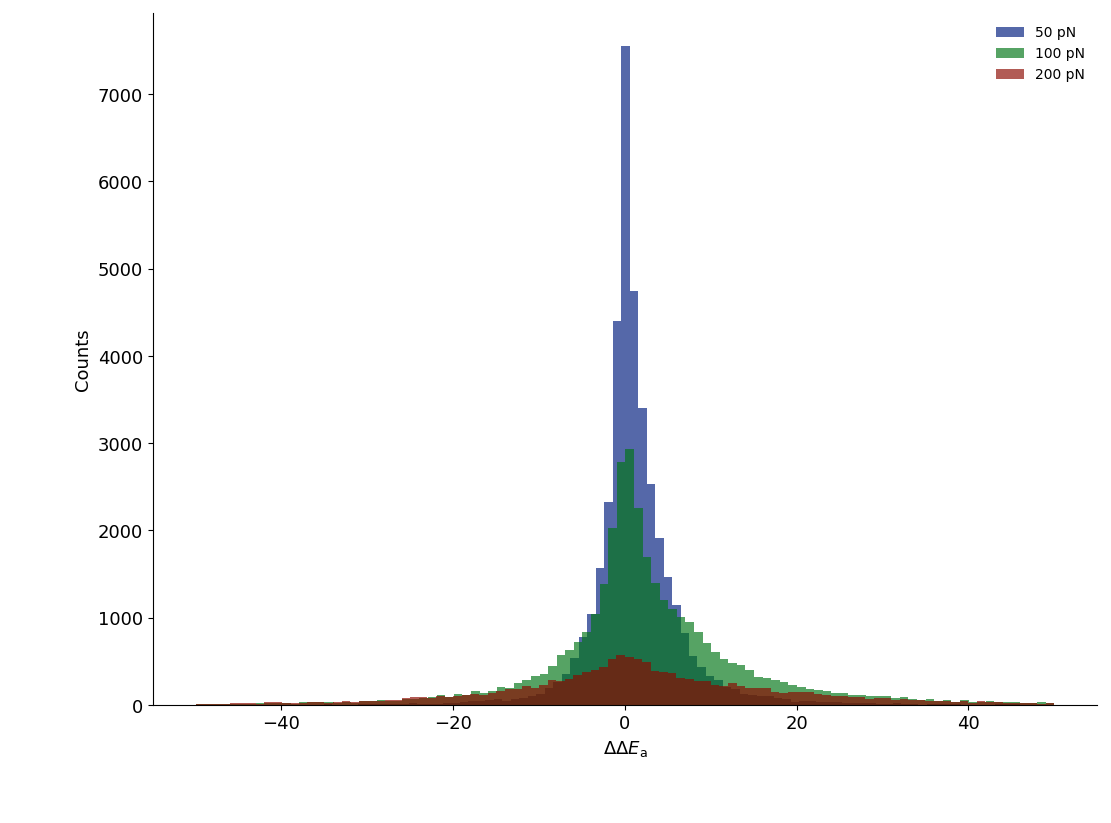

In [119]:
rda.plot_dataset_histogram(ds_reg_rig)

In [73]:
dd = d2_reg_rig[0]
opt = dd.optimizer

In [ ]:
opt.get_displacement_dirs(

In [ ]:
rda.animate_ts(dd)

In [ ]:
rda.animate_ts(dd, fmrd=wah[-2][2])

In [ ]:
opt.

In [86]:
umm = opt.reoptimize_with_force(
    0,
    magnitude=(-200, -100, -50, 50, 100, 200),
    split_magnitudes=True,
    units="PicoJoules/Meters",
    displacements=[dd.fmrds[0].force_vector],
    mass_weight=False,
    rigid=True
)

In [ ]:
np.linalg.norm(dd.fmrds[0].force_vector)

In [94]:
np.linalg.norm(dd.fmrds[0].force_vector)

0.0024275605321914385

In [96]:
np.linalg.norm(
    opt.mode_force_function(
        0,
        # displacements=[dd.fmrds[0].force_vector],
        mass_weight=False
    )[1]
)

1.0

In [246]:
woop = opt.get_displacement_dirs(
        displacements=[dd.fmrds[0].force_vector],
        mass_weight=False
    )
woop2 = opt.get_displacement_dirs(
        # displacements=[dd.fmrds[0].force_vector],
        mass_weight=False
    )

In [ ]:
opt.rs.animate_coordinate(0, coordinate_expansion=[woop2])

In [ ]:
opt.rs.animate_coordinate(0, coordinate_expansion=[woop])

In [ ]:
opt.force_dirs - o3.force_dirs

In [128]:
o2.prepped_modes[1].freqs * UnitsData.hartrees_to_wavenumbers

array([ 166.44008917,  217.9616277 ,  260.82288406,  290.43555834,
        340.62277128,  479.47656788,  517.12595959,  584.77993493,
        692.86586696,  749.55835084,  827.13507433,  888.58766968,
        916.78739243, 1014.90887814, 1047.77814779, 1100.25334536,
       1141.08311371, 1150.53129621, 1178.23072835, 1226.26584422,
       1309.24464038, 1417.32727974, 1437.67184467, 1456.73923351,
       1469.61354247, 1484.53670523, 1745.96211729, 2231.3616337 ,
       2702.53006676, 2911.79474559, 2971.36604367, 3017.39947174,
       3096.21152973])

In [238]:
optdir = importlib.reload(optdir)

In [244]:
opts = {
    k:v for k,v in o2.opts.items()
    if k in ['fragment_indices',
             'extra_localization',
             'remove_fragment_transrot',
             'remove_local_transrot',
             'internals',
             'project_internals',
             'allow_mode_mixing']
}
project_internals = opts.pop('project_internals', None)
if project_internals is False:
    opts.pop('internals', None)
opts['remove_local_transrot'] = True
opts['remove_fragment_transrot'] = True
opts['allow_mode_mixing'] = True
opts['project_zero_gmatrix_modes'] = True
# opts['internals'] = None
modedodo = optdir.prep_optimization_modes(
    o2.rs, o2.ts,
    **opts
)

modedodo2 = optdir.prep_optimization_modes(
    o3.rs, o2.ts,
    **opts
)

In [ ]:
o3.rs.animate_mode(0, modes=modedodo[0])

In [185]:
modedodo2 = optdir.prep_optimization_modes(
    o3.rs, o3.ts,
    **opts
)
modedodo3 = optdir.prep_optimization_modes(
    o3.rs, o3.ts,
    **opts
)

In [ ]:
prep_optimization_modes(
    o2.rs, o2.ts,
    **o2

In [131]:
np.round(
    (o2.prepped_modes[1].freqs * UnitsData.hartrees_to_wavenumbers) - (o3.prepped_modes[1].freqs * UnitsData.hartrees_to_wavenumbers)
)

array([  0.,  -0.,  -1.,  -0.,  -0.,  -3., -12., -27., -10.,  -6.,  -9.,
        38., -22.,  58., -19.,  -5.,  -1., -37., -47., -25.,   6.,  25.,
       -15.,   1.,   0.,  -1., -52., -29., -86., -40.,   0.,   0.,  -0.])

In [118]:
o3 = opt.from_data(
    o2.to_data()
)

In [111]:
wurt = opt.get_displacement_dirs(
        displacements=woop2,
        mass_weight=False
    )

In [ ]:
np.linalg.norm(
    opt.get_displacement_dirs(
        displacements=[dd.fmrds[0].force_vector],
        mass_weight=False
    )[1]
)

In [87]:
wah = opt.reoptimize_with_force(
    0,
    magnitude=(-200, -100, -50, 50, 100, 200),
    split_magnitudes=False,
    units="PicoJoules/Meters",
    # displacements=[dd.fmrds[0].force_vector],
    mass_weight=False,
    rigid=True
)

In [88]:
[rda.fmrd_barrier(b[2]) for b in wah]

[-3.7656156364581967,
 11.740563870873713,
 0.2362568918108101,
 1.8693507939914493,
 5.549450916593173,
 -64.02687460519013]

In [56]:
[rda.fmrd_barrier(b[2]) for b in wah]

[-3.7656156364581967,
 11.740563870873713,
 0.2362568918108101,
 1.8693507939914493,
 5.549450916593173,
 -64.02687460519013]

In [ ]:
rda.animate_ts(dd)

In [ ]:

wtf = ds_reg_rig[
    lambda d:np.abs(d['delta']) < 100, 
    lambda d:d['barrier'] > 10,
    lambda d:d['barrier'] < 50
    ]

### Workflow

In [ ]:
rrr = opt.product_molecule
rrr.plot(
    # mode_vectors=np.clip(v0.flatten() * 10, -3, 3),
    # mode_vector_display_cutoff=.8,
    backend='x3d',
    image_size=1000,
    draw_coords={
        (0, 2):{'line_style':'dashed', 'line_color':'gray'},
        (1, 3):{'line_style':'dashed', 'line_color':'gray'},
    },
    view_settings={
        'right_vector':-rrr.fragments[0].take_submolecule([0, 1, 2, 3, 4]).inertial_axes[:, 2],
        'view_vector':(
            np.average(rrr.coords[(0, 1), :], axis=0) 
            - np.average(rrr.coords[(4, 5), :], axis=0)
        ),
        'view_distance':15
        # 'viewAll':True
    },
    include_save_buttons=True,
    background='transparent',
    # display_atom_numbers=True,
    label_style={'font_style':{'size':15}}
)

In [ ]:
opt = d2_reg[
    lambda d:d['delta'] < -1,
    lambda d:d['force_magnitudes'] < -190,
    lambda d:d['direction_ids'] == 0,
    
    ][26]
rrr = opt.transition_state
fv = opt.fmrd_vector(0, mol='ts')
v0 = nput.vec_normalize(fv).reshape(-1, 3)
rrr.plot(
    mode_vectors=np.clip(v0.flatten() * 10, -3, 3),
    mode_vector_display_cutoff=.8,
    image_size=1000,
    draw_coords={
        (0, 2):{'line_style':'dashed', 'line_color':'gray'},
        (1, 3):{'line_style':'dashed', 'line_color':'gray'},
    },
    view_settings={
        'right_vector':-rrr.fragments[0].take_submolecule([0, 1, 2, 3, 4]).inertial_axes[:, 2],
        'view_vector':(
            np.average(rrr.coords[(0, 1), :], axis=0) 
            - np.average(rrr.coords[(4, 5), :], axis=0)
        ),
        'view_distance':15
        # 'viewAll':True
    },
    include_save_buttons=True,
    background='transparent',
    # display_atom_numbers=True,
    label_style={'font_style':{'size':15}}
)


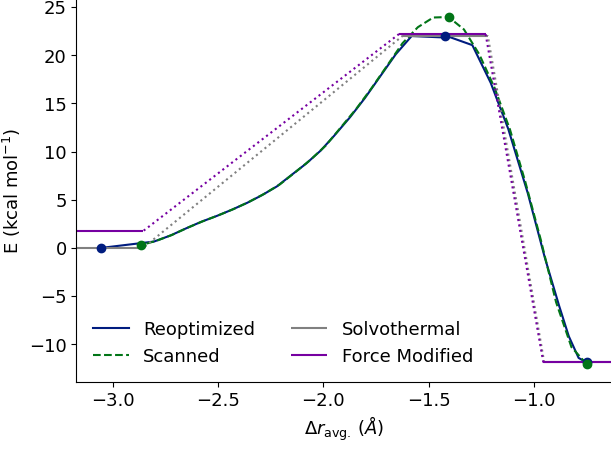

In [33]:
d2_reg[
    lambda d:d['delta'] < -1,
    lambda d:d['force_magnitudes'] < -190,
    lambda d:d['direction_ids'] == 0
][26].compare_profiles(
    image_size=[440, 330],
    padding=[[55, 0], [55, 0]],
    bar_color=[
        'gray',
        plt.prep_color(palette='default', index=3)
    ],
    line_styles={
        'connection_style':{'linestyle': 'dotted'},
        'primary_label':'Solvothermal'
    },
    secondary_styles={
        'primary_label':'Force Modified'
    },
    critical_point_style={
            'zorder':1000
        },
    labels=[
        'Reoptimized',
        'Scanned'
    ],
    plot_legend=True,
    legend_style={
        'frameon':False,
        'fontsize':13,
        'ncol':2
    }
)#.savefig("figs/workflow_example.svg")

In [34]:
d2_groups = rda.get_dienophile_groups(d2_reg)


In [61]:
samp_key = 'O=[SH](=O)c1ccccc1 Fc1ccccc1'
nconfs = {
        k:len(np.unique(d.d_path))
    for k,d in d2_groups[1]['O=[SH](=O)c1ccccc1 Fc1ccccc1'].items()
    }
nkey = max(nconfs.keys(), key=lambda k:nconfs[k])
subdd = d2_groups[1][samp_key][nkey].group_by_props('d_path')
prods = [v[0].product_molecule for v in subdd.values()]

In [46]:
subdd = d2_groups[1]["Fc1ccccc1"][
    'Fc1cc[c:8]([C@H:3]2[CH:1]3[CH:5]=[CH:6][CH:2]([CH2:4]2)[CH2:7]3)cc1'
].group_by_props('d_path')

In [47]:
prods = [v[0].product_molecule for v in subdd.values()]

TypeError: 'dict' object is not an iterator

In [ ]:
opt = list(subdd.values())[6][0]
rrr = opt.reactant
coords = rrr.coords + np.dot(p, axes.T) * 15
rv = rrr.fragments[0].take_submolecule([0, 1, 4, 5, 6]).inertial_axes[:, 2]
vv = (
            np.average(rrr.coords[(0, 1), :], axis=0) 
            - np.average(rrr.coords[(4, 5), :], axis=0)
        )
fv = opt.fmrd_vector(0)
v0 = nput.vec_normalize(fv).reshape(-1, 3)
rrr.plot(
    mode_vectors=np.clip(v0.flatten() * 10, -3, 3),
    mode_vector_display_cutoff=.8,
    image_size=1000,
    # draw_coords={
    #     (0, 2):{'line_style':'dashed', 'line_color':'gray'},
    #     (1, 3):{'line_style':'dashed', 'line_color':'gray'},
    # },
    view_settings={
        'right_vector':rv,
        'view_vector':vv,
        'view_distance':20
        # 'viewAll':True
    },
    backend='x3d',
    include_save_buttons=True,
    background='transparent',
    # display_atom_numbers=True,
    label_style={'font_style':{'size':15}}
)

In [101]:
placements = (
    np.array([1, 0])[np.newaxis, np.newaxis] 
    @ np.moveaxis(nput.rotation_matrix('2d', np.linspace(0, 2*np.pi, 6)[:5]), -1, 0)
)[:, 0]

In [ ]:
p0 = prods[0].get_embedded_molecule(sel=[0, 1, 4, 5, 6])
emb_prods = [p.get_embedded_molecule(ref=p0, sel=[0, 1, 4, 5, 6]) for p in prods]
rrr = emb_prods[7]
clean_prods = [0, 2, 4, 5, 6]
fig = None
placements_3d = np.concatenate([placements, np.zeros((len(placements), 1))], axis=1)
placements_3d = placements_3d[:, (0, 1, 2)]
for i,p in enumerate(placements_3d):
    rrr = emb_prods[clean_prods[i]]
    p = [1.2 if i%2 == 0 else 0, (-2 + i) / 2, 0]
    
    rv = rrr.fragments[0].take_submolecule([0, 1, 4, 5, 6]).inertial_axes[:, 2]
    vv = (
                np.average(rrr.coords[(0, 1), :], axis=0) 
                - np.average(rrr.coords[(4, 5), :], axis=0)
            )
    axes = nput.render_matrix(
        right_vector=rv,
        view_vector=vv
    )[:3, :3]
    coords = rrr.coords + np.dot(p, axes.T) * 15
    fig = rrr.plot(
        coords,
        image_size=1000,
        draw_coords={
            (0, 2):{'line_style':'dashed', 'line_color':'gray'},
            (1, 3):{'line_style':'dashed', 'line_color':'gray'},
        },
        view_settings={
            'right_vector':rv,
            'view_vector':vv,
            'view_distance':35
            # 'viewAll':True
        },
        figure=fig,
        backend='x3d',
        include_save_buttons=True,
        background='transparent',
        # display_atom_numbers=True,
        label_style={'font_style':{'size':15}}
    )
fig

### Histograms and Global Plots

#### Deviation Histograms

In [207]:
import McUtils.Plots

In [245]:
import McUtils.Jupyter as interactive

interactive.ModuleReloader('McUtils.Plots').reload()

In [336]:
rda = importlib.reload(rda)

In [212]:
rda.plot_dataset_density_comparison_histogram(
    ds_reg,
    rx_thresh=-5, 
    ts_thresh=-5,
    max_delta=20,
    filter=lambda d:d[(d > -2) & (d < 15)],
    legend_style={'frameon':False, 'fontsize':13, 'loc':'lower left', 'bbox_to_anchor':[.25, 0]},
    panel_label_anchors=[[1, .3], [1, -.3]],
    panel_label_style={'ha':'right', 'fontsize':13}
    ).savefig('figs/density_distortion_comparisons_reg.svg')

In [213]:
rda.plot_dataset_density_comparison_histogram(
    ds_uin,
    rx_thresh=-5, 
    ts_thresh=-5,
    max_delta=20,
    filter=lambda d:d[(d > -2) & (d < 15)],
    legend_style={'frameon':False, 'fontsize':13, 'loc':'lower left', 'bbox_to_anchor':[.25, 0]},
    panel_label_anchors=[[1, .3], [1, -.3]],
    panel_label_style={'ha':'right', 'fontsize':13}
    ).savefig('figs/density_distortion_comparisons_reg_uin.svg')

In [214]:
rda.plot_dataset_density_comparison_histogram(
    ds_reg_rig,
    rx_thresh=-5, 
    ts_thresh=-5,
    rx_max=100,
    ts_max=100,
    max_delta=20,
    filter=lambda d:d[(d > -5) & (d < 100)],
    legend_style={'frameon':False, 'fontsize':13, 'loc':'lower left', 'bbox_to_anchor':[.3, 0]},
    panel_label_anchors=[[1, .3], [1, -.3]],
    panel_label_style={'ha':'right', 'fontsize':13}
    ).savefig('figs/density_distortion_comparisons_reg_rig.svg')

In [ ]:
# rda.animate_rx(ds_uin_rig[10], embedding_indices=[0, 1, 2, 3, 4, 5 ,6])

In [215]:
rda.plot_dataset_density_comparison_histogram(
    ds_uin_rig,
    rx_thresh=-5, 
    ts_thresh=-5,
    rx_max=100,
    ts_max=100,
    max_delta=20,
    filter=lambda d:d[(d > -5) & (d < 100)],
    legend_style={'frameon':False, 'fontsize':13, 'loc':'lower left', 'bbox_to_anchor':[.25, 0]},
    panel_label_anchors=[[1, .3], [1, -.3]],
    panel_label_style={'ha':'right', 'fontsize':13}
    ).savefig('figs/density_distortion_comparisons_uin_rig.svg')

In [216]:
rda.plot_dataset_density_comparison_histogram(
    ds_reg_rig,
    rx_thresh=-100, 
    ts_thresh=-100,
    rx_max=100,
    ts_max=100,
    max_delta=100,
    filter=lambda d:d[(d > -5)],
    legend_style={'frameon':False, 'fontsize':13, 'loc':'lower right', 'bbox_to_anchor':[1, 0]},
    panel_label_anchors=[[.2, 1], [.2, -1]],
    panel_label_style={'ha':'left', 'fontsize':13}
    ).savefig('figs/density_distortion_comparisons_reg_rig.svg')

In [217]:
rda.plot_dataset_density_comparison_histogram(
    ds_int,
    rx_thresh=-5, 
    ts_thresh=-5,
    max_delta=20,
    filter=lambda d:d[(d > -2) & (d < 12)],
    legend_style={'frameon':False, 'fontsize':13, 'loc':'lower left', 'bbox_to_anchor':[.25, 0]},
    panel_label_anchors=[[1, .3], [1, -.3]],
    panel_label_style={'ha':'right', 'fontsize':13}
    ).savefig('figs/density_distortion_comparisons_int.svg')

In [8]:
rda.plot_dataset_density_comparison_histogram(
    ds_int_rig,
    rx_thresh=-100, 
    ts_thresh=-100,
    rx_max=100,
    ts_max=100,
    max_delta=100,
    filter=lambda d:d[(d > -.1) & (d < 2)],
    legend_style={'frameon':False, 'fontsize':13, 'loc':'lower right', 'bbox_to_anchor':[1, 0]},
    panel_label_anchors=[[.2, 1], [.2, -1]],
    panel_label_style={'ha':'left', 'fontsize':13}
    ).savefig('figs/density_distortion_comparisons_int_rig.svg')

In [10]:
rda.plot_dataset_density_comparison_histogram(
    ds_rand,
    rx_thresh=-5, 
    ts_thresh=-5,
    max_delta=20,
    filter=lambda d:d[(d > -2) & (d < 12)],
    legend_style={'frameon':False, 'fontsize':13, 'loc':'lower left', 'bbox_to_anchor':[.25, 0]},
    panel_label_anchors=[[1, .3], [1, -.3]],
    panel_label_style={'ha':'right', 'fontsize':13}
    ).savefig('figs/density_distortion_comparisons_rand.svg')

In [18]:
rda.plot_dataset_density_comparison_histogram(
    ds_rand_rig,
    rx_thresh=-100, 
    ts_thresh=-100,
    rx_max=100,
    ts_max=100,
    max_delta=100,
    filter=lambda d:d[(d > -.1) & (d < 2)],
    legend_style={'frameon':False, 'fontsize':13, 'loc':'lower right', 'bbox_to_anchor':[1, 0]},
    panel_label_anchors=[[.5, 1], [.35, -1]],
    panel_label_style={'ha':'left', 'fontsize':13}
    ).savefig('figs/density_distortion_comparisons_rand_rig.svg')

In [204]:
# ds_reg, d2_reg = rda.load_prep_filter(f'compressed_datasets/{root}')

#### Global Comparisons

##### Scatters

In [ ]:
ddd = d2_uin[
        lambda d:(
            (d['delta'] < 10)
            & (d['delta'] > -15)
            & (d['barrier'] < 20)
            & (d['barrier'] < 35)
        )]
idx = np.argmax(ddd.deltas)
# ddd.plot()
# rda.animate_rx(ddd[0])
opt = ddd[idx]
rrr = opt.reactant
fv = opt.fmrds[0].force_vector
if len(fv) < len(rrr.atoms)*3:
    fv_func = opt.optimizer.mode_force_function(
        0,
        magnitude=opt.fmrds[0].force_magnitude,
        use_internals=True,
        displacements=[fv]
        # displacements=opt.optimizer.pure_internal_displacement_matrix
    )[0]
    fv = -fv_func(rrr.coords, np.zeros(len(rrr.atoms)*3))
v0 = nput.vec_normalize(fv).reshape(-1, 3)
# v0[rrr.fragment_indices[0], :] = 0
# v0[38:43, :] = 0
rrr.plot(
    rrr.coords - np.average(rrr.coords[(2, 3), :], axis=0)[np.newaxis],
    mode_vectors=np.clip(v0.flatten() * 10, -3, 3),
    mode_vector_display_cutoff=.8,
    image_size=1000,
    view_settings={
        'up_vector':rrr.fragments[0].take_submolecule([0, 1, 2, 3, 4]).inertial_axes[:, 2],
        'view_vector':-(
            np.average(rrr.coords[(0, 1), :], axis=0) 
            - np.average(rrr.coords[(4, 5), :], axis=0)
        ),
        'view_distance':15
        # 'viewAll':True
    },
    include_save_buttons=True,
    background='transparent',
    # display_atom_numbers=True,
    label_style={'font_style':{'size':15}}
)

In [132]:
107911 - len(d2_uin)

33537

In [151]:
len(ds_uin) - 112140

2160

In [ ]:
ds_uin[lambda d:d['barrier'] == 0][0].compare_profiles()

In [162]:
np.unique(ds_uin[lambda d:d['barrier'] == 0].data_ids, axis=0)

array([['ALFJCSUKDJNVTM-OQSWDALSSA-N', '6', 'pipeline_data_useint'],
       ['CEJWYFOYMLHBET-QZTJIDSGSA-N', '13', 'pipeline_data_useint'],
       ['HFOJPRUNBBSFGS-MOPGFXCFSA-N', '4', 'pipeline_data_useint'],
       ['MBPWEKZEDGYWRG-HCWSGVFWSA-N', '6', 'pipeline_data_useint'],
       ['MBPWEKZEDGYWRG-MMVSWEMESA-N', '8', 'pipeline_data_useint'],
       ['NBPAFPAIJYEUBH-ABIFROTESA-N', '0', 'pipeline_data_useint'],
       ['RIADKVPOGAIZFB-KFJBMODSSA-N', '4', 'pipeline_data_useint'],
       ['RIADKVPOGAIZFB-KFJBMODSSA-N', '8', 'pipeline_data_useint'],
       ['RIADKVPOGAIZFB-TVKKRMFBSA-N', '5', 'pipeline_data_useint'],
       ['SQKXNLCDVJKWTQ-QMDRTORHSA-N', '4', 'pipeline_data_useint'],
       ['YJOGQGNGUXYEOS-LCSXWQTCSA-N', '11', 'pipeline_data_useint'],
       ['YXBPHYTZDBNTGE-DTLKIFBZSA-N', '27', 'pipeline_data_useint'],
       ['YXBPHYTZDBNTGE-ROFXEPAZSA-N', '56', 'pipeline_data_useint'],
       ['ZRLBFEQFNUZGJW-BRQZFJGMSA-N', '12', 'pipeline_data_useint']],
      dtype='<U27')

In [159]:
len(
    rda.filter_d2(ds_uin,
                  ts_thresh=-1e8,
                  rx_thresh=-1e8,
                  ts_max=1e8,
                  rx_max=1e8,
                  max_delta=1e8,
                  barrier_range=[-1e-8, 80]
                  )
)

113760

In [130]:
len(rda.filter_d2(ds_uin, ts_thresh=-100))

107911

In [ ]:
len(rda.filter_d2(ds_uin, ts_thresh=-100))

In [125]:
rda.filter_d2(ds_reg, ts_thresh=-.1)

Signature:
rda.filter_d2(
    ds,
    barrier_range=[5, 80],
    max_delta=50,
    ts_thresh=0,
    ts_max=25,
    rx_thresh=-0.1,
    rx_max=25,
)
Docstring: <no docstring>
Source:   
def filter_d2(ds, barrier_range=[5, 80], max_delta=50, ts_thresh=0, ts_max=25, rx_thresh=-.1, rx_max=25):
    return ds.filter_by_props([
        lambda d: d['delta_transition_state'] > ts_thresh,
        lambda d: d['delta_transition_state'] < ts_max,
        lambda d: d['delta_reactant'] > rx_thresh,
        lambda d: d['delta_reactant'] < rx_max,
        lambda d: d['barrier'] > barrier_range[0],
        lambda d: d['barrier'] < barrier_range[1],
        lambda d: np.abs(d['delta']) < max_delta
    ])
File:      ~/Documents/Postdoc/Development/cmcc-reactions/cmcc_reactions/reaction_data_analysis.py
Type:      function

In [364]:
d2_reg_keyed = rda.add_keys(d2_reg)
g2_reg = d2_reg_keyed.group_by_props('d_path')
d2_int_keyed = rda.add_keys(d2_int)
g2_int = d2_int_keyed.group_by_props('d_path')

In [370]:
shit = itut.first(g2_int.values())

In [ ]:
ddd = d2_int[
        lambda d:(
            (d['delta'] < -10)
            & (d['delta'] > -15)
            & (d['barrier'] > 30)
            # & (d['barrier'] < 23)
        )]
idx = np.argmin(ddd.deltas)
# ddd.plot()
# rda.animate_rx(ddd[0])
opt = ddd[idx]
rrr = opt.reactant
fv = opt.fmrds[0].force_vector
if len(fv) < len(rrr.atoms)*3:
    fv_func = opt.optimizer.mode_force_function(
        0,
        magnitude=opt.fmrds[0].force_magnitude,
        use_internals=True,
        displacements=[fv]
        # displacements=opt.optimizer.pure_internal_displacement_matrix
    )[0]
    fv = -fv_func(rrr.coords, np.zeros(len(rrr.atoms)*3))
v0 = nput.vec_normalize(fv).reshape(-1, 3)
# v0[rrr.fragment_indices[0], :] = 0
# v0[38:43, :] = 0
rrr.plot(
    rrr.coords - np.average(rrr.coords[(2, 3), :], axis=0)[np.newaxis],
    mode_vectors=np.clip(v0.flatten() * 10, -3, 3),
    mode_vector_display_cutoff=.8,
    image_size=1000,
    view_settings={
        'up_vector':-rrr.fragments[0].take_submolecule([0, 1, 2, 3, 4]).inertial_axes[:, 2],
        'view_vector':-(
            np.average(rrr.coords[(0, 1), :], axis=0) 
            - np.average(rrr.coords[(4, 5), :], axis=0)
        ),
        'view_distance':15
        # 'viewAll':True
    },
    include_save_buttons=True,
    background='transparent',
    # display_atom_numbers=True,
    label_style={'font_style':{'size':15}}
)

In [91]:
rda = importlib.reload(rda)
type(d2_uin).plot = rda.BarrierHeightDataset.plot

opts = dict(
    plot_range=[[12, 44], [-27, 16]],
    colorbar={
        'orientation': 'horizontal',
        'origin': [300, 315],
        'size': [55, 10],
        'boundaries':[0, 50, 150, 200],
        'ticks':[
            (
                [25, 100, 175],
                [50, 100, 200],
            ),
            []
        ],
        'plot_label':r'$\vec{F}_\text{ext}$ (pN)',
        'ticks_style':{'size':3, 'labelsize':11.5, 
                       # 'labeltop':True, 'top':True, 
                       # 'labelbottom':False, 'bottom':False
                      }
    }, 
    # cmap=plt.ColorPalette(colors).as_colormap(),
    image_size=[350, 350],
    padding=((110, 10), (85, 30)),
    s=1,
    use_abs=True,
    sort_magnitudes=True
)

colors = [
    plt.prep_color(
    palette='default',
    index=0,
    lighten=p,
    saturate=-p * .3,
    modification_space='hsl'
) for p in np.array([2, 1, 0])
]
d2_uin.plot(
    cmap=plt.ColorPalette(colors).as_colormap(),
    **opts
)#.savefig("figs/base_scatter_reg_colorbar_hw_sorted.png", dpi=300)

(350, 350)

In [100]:
colors = [
    plt.prep_color(
        palette='pastel',
        index=3,
        lighten=p/8,
        saturate=-p * .2,
        modification_space='hsl'
    ) 
    for p in np.array([2, .2, -1])
]
d2_int.plot(
    cmap=plt.ColorPalette(colors).as_colormap(),
    **opts
).savefig("figs/base_scatter_int_colorbar_hw_sorted.png", dpi=300)

In [654]:
plt.ColorPalette([
    plt.prep_color(
        palette='default',
        index=0
    ),
    plt.prep_color(
        palette='default',
        index=1
    ),
    plt.prep_color(
        palette='pastel',
        index=3
    )
]).get_colorblindness_test_url()
    

'https://davidmathlogic.com/colorblind/#%23001C7F-%23017517-%23fd7f6f'

In [686]:
len(d2_reg)

74596

In [685]:
len(d2_int)

38877

In [684]:
colors = [
    plt.prep_color(
        palette='pastel',
        index=3,
        lighten=p/8,
        saturate=-p * .2,
        modification_space='hsl'
    ) 
    for p in np.array([2, .2, -1])
]
d2_int.plot(
    cmap=plt.ColorPalette(colors).as_colormap(),
    **opts
).savefig("figs/base_scatter_int_colorbar.png", dpi=300)

In [38]:
base_cmap = mpl.colormaps['viridis']
from matplotlib.colors import ListedColormap

base_cmap = mpl.colormaps['viridis']
colors = base_cmap(np.linspace(0, 1, base_cmap.N))
colors[:, -1] = 0.05
translucent_cmap = ListedColormap(colors)


base_cmap = mpl.colormaps['viridis']
colors = base_cmap(np.linspace(0, 1, base_cmap.N))
colors[:, -1] = 1
translucent_cmap2 = ListedColormap(colors)


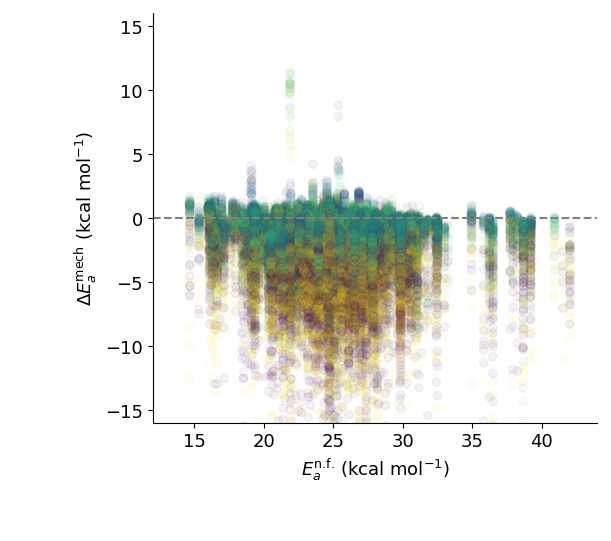

In [48]:
f0 = d2_uin.plot(plot_range=[[12, 44], [-16, 16]], 
            cmap=translucent_cmap, 
            # filled=False,
           )
# d2_uin.plot(plot_range=[[12, 44], [-16, 16]], 
#             # cmap=translucent_cmap2, 
#             filled=False,
#             linewidths=.1,
#             figure=f0
#            )
f0#.savefig("figs/base_scatter_reg_transp.png", dpi=300)

In [304]:
d2_uin.plot(plot_range=[[12, 44], [-16, 16]]).savefig(
    "figs/base_scatter_reg.png",
    dpi=300
)

In [98]:
d2_int_rig.plot(plot_range=[[12, 44], [-16, 16]]).savefig(
    "figs/base_scatter_int_rigid.png",
    dpi=300
)

In [97]:
d2_int.plot(plot_range=[[12, 44], [-16, 16]]).savefig(
    "figs/base_scatter_int.png",
    dpi=300
)

In [306]:
d2_rand.plot(plot_range=[[12, 44], [-16, 16]]).savefig(
    "figs/base_scatter_rand.png",
    dpi=300
)

In [ ]:
d2_rand.plot(plot_range=[[12, 44], [-16, 16]])#.savefig(
    "figs/base_scatter_rand.png",
    dpi=300
)

##### Histograms

In [12]:
rda = importlib.reload(rda)

**Regular**

In [627]:
fuck = plt.ColorPalette(
    [
    plt.prep_color(palette='default', index=0),
    plt.prep_color(palette='default', index=1),
    plt.prep_color(palette='pastel', index=0)
]
)


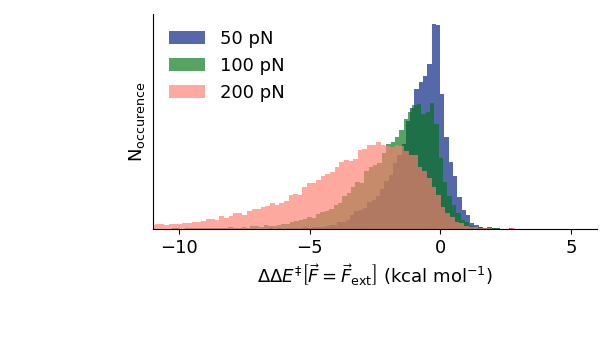

In [27]:
rda = importlib.reload(rda)
fig_hist_reg = rda.plot_dataset_histogram(
    d2_uin,
    image_size=[440, 250],
    bins=150,
    max_delta=15,
    ticks=[[-10, -5, 0, 5], []],
    plot_range=[[-11, 6], None],
    # only_kde=True,
    # filled=True
    # color_generator=lambda i: colors[i]+"aa"
)
fig_hist_reg#.savefig('figs/ds_hists_reg.svg')

In [ ]:
rda = importlib.reload(rda)
colors = [
    plt.prep_color(
        palette='default',
        index=0,
        lighten=p,
        saturate=-p * .3,
        modification_space='hsl'
    ) for p in np.array([2, 1, 0])
]
kde_opts = dict(
    image_size=[120, 350],
    plot_legend=None,
    bins=150,
    max_delta=28,
    ticks=[[], None],
    plot_range=[None, [-27, 16]],
    only_kde=True,
    filled=True,
    orientation='horizontal',
    frame=[[True, False], [True, False]],
    padding=[[60, 0], (85, 30)],
    # axes_labels=[None, None],
    axes_labels=[None, 
                 r"$\Delta \Delta E^{\ddagger} \left[\vec{F}=\vec{F}_\text{ext}\right]$ (kcal mol$^{-1}$)"]
)
fig_hist_reg_kde = rda.plot_dataset_histogram(
    d2_uin,
    color_generator=lambda i: colors[i]+"aa",
    **kde_opts
    # color_generator=lambda i: colors[i]+"aa"
)
fig_hist_reg_kde#.savefig('figs/ds_hists_reg_kde.svg')

In [108]:
len(ds_uin)

114300

In [118]:
np.unique([
    d[0]+"_"+d[1] for d in itertools.chain(
        ds_rand.data_ids,
        ds_uin.data_ids,
        ds_int.data_ids
    )
]).shape
        

(1271,)

In [116]:
np.unique([
    d[0] for d in itertools.chain(
        ds_rand.data_ids,
        ds_uin.data_ids,
        ds_int.data_ids
    )
]).shape
        

(233,)

In [114]:
len(ds_rand) + len(ds_uin) + len(ds_int)

284538

In [110]:
len(ds_int)

55848

In [109]:
len(d2_int)

38877

In [104]:
colors = [
    plt.prep_color(
        palette='pastel',
        index=3,
        lighten=p/12,
        saturate=-p * .2,
        modification_space='hsl'
    ) 
    for p in np.array([2, .2, -1])
]
fig_hist_int_kde = rda.plot_dataset_histogram(
    d2_int,
    color_generator=lambda i: colors[i]+"aa",
    **kde_opts
    # color_generator=lambda i: colors[i]+"aa"
)
fig_hist_int_kde.savefig('figs/ds_hists_int_kde.svg')

In [694]:
fig_hist_int = rda.plot_dataset_histogram(
    d2_int,
    image_size=[440, 250],
    bins=150,
    max_delta=15,
    ticks=[[-10, -5, 0, 5], []],
    plot_range=[[-11, 6], None]
)
fig_hist_int.savefig('figs/ds_hists_int.svg')

In [100]:
ddd_rand_rig = rda.get_dienophile_groups(d2_rand_rig)[0]

In [124]:
bbbb = ddd_rand_rig[
    lambda d:d['d_path'] == 'ZLWDUGOFEUEVEX-GLGOKHISSA-N/5/pipeline_data_random_rigid',
    lambda d:d['direction_ids'] == 8
    ]

In [ ]:
rda.animate_rx(bbbb[5])

In [ ]:
rda.animate_fmrd(d2_rand[550])

In [ ]:
rda.animate_rx(d2_rand[550])

In [65]:
mol = d2_reg[0].reactant
surf = mol.get_surface(radius_scaling=1.8).get_triangulation(method='isosurface', grid_samples=50)


In [145]:
rda = importlib.reload(rda)

In [60]:
fig_hist_rand = rda.plot_dataset_histogram(
    d2_rand,
    image_size=[440, 250],
    bins=150,
    max_delta=15,
    ticks=[[-10, -5, 0, 5], []],
    plot_range=[[-11, 6], None],
    padding=[[50, 0], [50, 25]]
)
fig_hist_rand.axes.set_autoscale_on(False)
plt.Plot(
    [rda.kbT_mag(-298), rda.kbT_mag(-298)],
    [0, 12000],
    figure=fig_hist_rand,
    adjust_limits=False,
    linestyle='dashed',
    color='gray',
    zorder=-10000
)
plt.Text("298K", [rda.kbT_mag(-350), 1400], 
         ha='left',
         font_size=13).plot(fig_hist_rand)
# plt.Rectangle(
#     [
#     [rda.kbT_mag(-298), 0],
#     [rda.kbT_mag(-1000), 12000]
#     ],
#     adjust_limits=False,
#     # linestyle='dashed',
#     color=plt.prep_color('red', lighten=.5, modification_space='hsl'),
#     zorder=-11000
# ).plot(fig_hist_rand)
plt.Plot(
    [rda.kbT_mag(-1000), rda.kbT_mag(-1000)],
    [0, 12000],
    figure=fig_hist_rand,
    adjust_limits=False,
    linestyle='dashed',
    color='gray',
    zorder=-10000
)
plt.Text("1000K", [rda.kbT_mag(-1000), 1400], 
         ha='center',
         font_size=13).plot(fig_hist_rand)
# plt.Rectangle(
#     [
#     [rda.kbT_mag(-1000), 0],
#     [rda.kbT_mag(-2000), 12000]
#     ],
#     adjust_limits=False,
#     # linestyle='dashed',
#     color=plt.prep_color('red', lighten=.2, modification_space='hsl'),
#     zorder=-11000
# ).plot(fig_hist_rand)
plt.Plot(
    [rda.kbT_mag(-2000), rda.kbT_mag(-2000)],
    [0, 12000],
    figure=fig_hist_rand,
    adjust_limits=False,
    linestyle='dashed',
    color='gray',
    zorder=-10000
)
plt.Text("2000K", [rda.kbT_mag(-2000), 1400], 
         ha='center',
         font_size=13).plot(fig_hist_rand)
# plt.Plot(
#     [rda.kbt_acceleration(1/10), rda.kbt_acceleration(1/10)],
#     [0, 12000],
#     figure=fig_hist_rand,
#     adjust_limits=False,
#     linestyle='dashed',
#     color='gray',
#     zorder=-10000
# )
# plt.Plot(
#     [rda.kbt_acceleration(1/100), rda.kbt_acceleration(1/100)],
#     [0, 12000],
#     figure=fig_hist_rand,
#     adjust_limits=False,
#     linestyle='dashed',
#     color='gray',
#     zorder=-10000
# )
# fig_hist_rand.savefig('figs/ds_hists_rand.svg')

**Rigid**

In [698]:
fig_hist_reg_rig = rda.plot_dataset_histogram(
    d2_uin_rig,
    image_size=[440, 250],
    bins=150,
    max_delta=15,
    ticks=[[-10, -5, 0, 5, 10], []],
    plot_range=[[-11, 11], None]
)
fig_hist_reg_rig.savefig('figs/ds_hists_reg_rig.svg')

In [182]:
fig_hist_rand_rig = rda.plot_dataset_histogram(
    d2_rand_rig,
    image_size=[440, 250],
    bins=150,
    max_delta=1.5,
    ticks=[[-1, -.5, 0, .5, 1], []],
    plot_range=[[-1.2, 1.2], None],
    padding=[[50, 0], [50, 25]]
)
fig_hist_rand_rig.savefig('figs/ds_hists_rand_rig.svg')


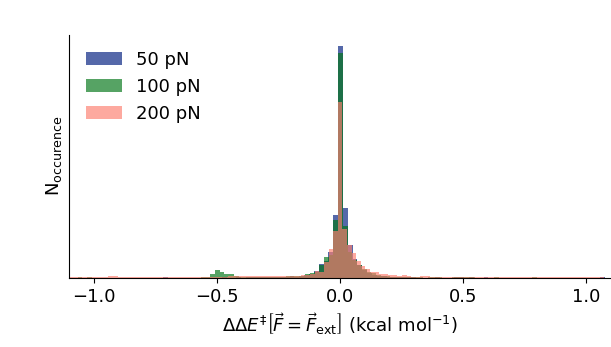

In [179]:
fig_hist_int_rig = rda.plot_dataset_histogram(
    d2_int_rig,
    image_size=[440, 250],
    bins=150,
    max_delta=1.5,
    ticks=[[-1, -.5, 0, .5, 1], []],
    plot_range=[[-1.1, 1.1], None]
)
fig_hist_int_rig.savefig('figs/ds_hists_int_rig.svg')

### Compliances

#### Internal Coordinate Examples

In [34]:
rda = importlib.reload(rda)

In [7]:
uhhh = Molecule.from_string(
    'C(=C/S(=O)(=O)c1ccccc1)/OC',
    energy_evaluator='aimnet2'
).optimize(max_iterations=500)

In [300]:
modes = uhhh.get_normal_modes()

In [9]:
mmm = uhhh.modify(internals=uhhh.get_bond_zmatrix())

In [297]:
import scipy

In [301]:
modes.freqs

array([0.00016695, 0.00032902, 0.00038257, 0.00043058, 0.00071767,
       0.00089344, 0.00097995, 0.00114489, 0.00139174, 0.00151951,
       0.00171158, 0.001853  , 0.00194252, 0.00221208, 0.00233589,
       0.00265792, 0.00274815, 0.00275274, 0.00291376, 0.00302261,
       0.00321572, 0.00329122, 0.00348864, 0.00369596, 0.00388225,
       0.00412327, 0.004319  , 0.00434337, 0.00451087, 0.0046166 ,
       0.00493538, 0.00497896, 0.00504201, 0.00508448, 0.00515925,
       0.00524146, 0.00526396, 0.00555275, 0.0056654 , 0.00574338,
       0.00602703, 0.00612115, 0.00619423, 0.00637224, 0.00652869,
       0.00694314, 0.00698271, 0.00705464, 0.00710602, 0.0072365 ,
       0.00785794, 0.00792599, 0.00828643, 0.01403365, 0.01426451,
       0.01429504, 0.01437032, 0.01449609, 0.01451325, 0.01461644,
       0.01466752, 0.01490207, 0.01499377])

In [299]:
vv = mmm.get_internal_potential_derivatives(order=2)[1]
gg = mmm.get_gmatrix()
np.sqrt(scipy.linalg.eigh(vv, gg, type=3)[0])

array([0.00016752, 0.00032901, 0.00038271, 0.00042875, 0.0007174 ,
       0.00089339, 0.00098008, 0.00114487, 0.00139143, 0.00151953,
       0.0017114 , 0.00185314, 0.00194191, 0.00221183, 0.00233563,
       0.00265774, 0.00274821, 0.00275269, 0.00291368, 0.00302255,
       0.00321573, 0.00329006, 0.00348873, 0.00369612, 0.00388234,
       0.00412324, 0.00431893, 0.00434223, 0.00451071, 0.00461656,
       0.00493539, 0.00497897, 0.00504201, 0.00508451, 0.00515926,
       0.00524145, 0.00526399, 0.00555279, 0.00566534, 0.00574354,
       0.00602658, 0.00612117, 0.00619376, 0.00637233, 0.00652843,
       0.00694319, 0.00698272, 0.0070548 , 0.00710583, 0.00723616,
       0.00785794, 0.00792602, 0.00828635, 0.01403365, 0.01426451,
       0.01429505, 0.01437033, 0.01449608, 0.01451325, 0.01461644,
       0.01466753, 0.01490208, 0.01499377])

In [391]:
def ic_compliances(mmm, units="NanoJoules", return_diag=True, inv=None):
    vv = mmm.get_internal_potential_derivatives(order=2)[1]
    if inv is None:
        inv = nput.frac_powh(vv, -1)
    else:
        inv = inv(vv)
    if return_diag:
        inv = np.diag(inv)
    return inv * (
        UnitsData.convert("BohrRadius", "Angstroms")
        * UnitsData.convert("BohrRadius", "Meters")
        / UnitsData.convert("Hartrees", units)
    )
def bond_compliances(mmm, units="NanoJoules", distance_order=False, include_covalent_data=False, return_mol=False, **etc):
    bd = rda.get_compliances(mmm, distance_order=distance_order, include_covalent_data=include_covalent_data, return_mol=return_mol,
                             **etc)
    conv = (
        UnitsData.convert("BohrRadius", "Angstroms")
        * UnitsData.convert("BohrRadius", "Meters")
        / UnitsData.convert("Hartrees", units)
    )
    if not isinstance(bd, np.ndarray):
        return (conv * bd[0],) + bd[1:]
    else:
        return conv * bd
def ic_gamma(mmm, coord, units="NanoJoules"):
    idx = coordops.zmatrix_indices(mmm.internals['zmatrix'], coord)
    gg = mmm.get_gmatrix()[idx, idx]
    vv = mmm.get_internal_potential_derivatives(order=2)[1][idx, idx]
    return ( 1 / vv ) * (
        UnitsData.convert("BohrRadius", "Angstroms")
        * UnitsData.convert("BohrRadius", "Meters")
        / UnitsData.convert("Hartrees", units)
    )

In [50]:
wat.get_internal_potential_derivatives(order=2)[1][0, 0]

np.float64(0.06789108692225829)

In [51]:
mmm.get_internal_potential_derivatives(order=2)[1][idx, idx]

np.float64(0.8156126351733561)

In [ ]:
# _, wat = rda.get_compliances(mmm, return_mol=True, distance_order=False, include_covalent_data=True)
# print(_)

In [ ]:
wat.animate_coordinate(0)


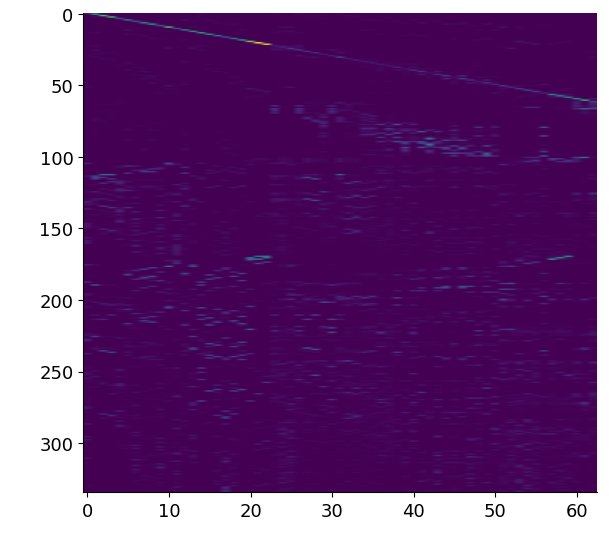

In [47]:
plt.ArrayPlot(wat.internals['redundant_transformation']**2)

In [44]:
_, wat = bond_compliances(mmm, return_mol=True, distance_order=True, include_covalent_data=True, include_covalent_dihedrals=True)
_

np.float64(0.757572571098534)

In [49]:
np.argmax(_)

np.int64(24)

In [ ]:
wat.animate_coordinate(0)

In [ ]:
plt.ArrayPlot(wa

In [ ]:
wat.animate_coordinate(0)

In [41]:
idx = coordops.zmatrix_indices(mmm.internals['zmatrix'], (0, 1))
np.diag(ic_compliances(mmm, units="NanoJoules"))[idx]

np.float64(0.00922402638077978)

In [ ]:
mmm.animate_coordinate(idx, .1)

In [389]:
gg = mmm.get_gmatrix()[25, 25]

In [380]:
vv = mmm.get_internal_potential_derivatives(order=2)[1][25, 25]

In [381]:
( 1 / vv ) * (
    UnitsData.convert("Angstroms", "Meters")
    / UnitsData.convert("Hartrees", "NanoJoules")
)

np.float64(0.03895452137172369)

In [ ]:
mmm.animate_coordinate(25, .1)

In [ ]:
mmm.plot(display_atom_numbers=True)

In [365]:
modes.freqs * UnitsData.convert("Hartrees", "Wavenumbers")

array([  46.60366504,   73.09179845,   82.59605994,  124.91551573,
        177.34534621,  233.60395754,  245.99310109,  265.33334911,
        294.10289512,  336.93265154,  375.66620885,  394.12613452,
        421.9429837 ,  478.52260037,  484.27947268,  567.92178417,
        593.86649234,  611.2450368 ,  642.68496516,  670.74579125,
        693.99966488,  718.94169408,  768.17787219,  808.78422048,
        858.03375564,  901.38205278,  942.01771116,  947.18695242,
        991.79548311, 1001.13420211, 1023.881441  , 1078.79903968,
       1085.74760471, 1109.10109023, 1114.55796601, 1120.40824506,
       1146.5274784 , 1159.83167316, 1202.41830037, 1240.46946224,
       1289.39970527, 1336.22463999, 1375.85277837, 1414.44579518,
       1425.45787634, 1511.547084  , 1524.09068282, 1527.45678278,
       1539.65543555, 1541.72467645, 1713.6029251 , 1739.57107726,
       1797.3451555 , 3089.79944654, 3091.07620048, 3131.59915363,
       3140.68279116, 3173.68147909, 3175.23149923, 3181.27666

In [360]:
(
    1 / (
        (753)**2 / 8
        * UnitsData.convert("Wavenumbers", "Hartrees")
        / UnitsData.convert("BohrRadius", "Angstroms")**2
    )
) * (
    UnitsData.convert("Angstroms", "Meters")
    / UnitsData.convert("Hartrees", "NanoJoules")
)

0.01988957797326349

#### Reference Molecules

In [155]:
ethylene = Molecule.from_string('C=C', energy_evaluator='aimnet2:aimnet2-2025')
ethylene = ethylene.optimize(max_iterations=500)

In [157]:
ethylene.get_normal_modes()
comps = rda.get_compliances(ethylene)

In [159]:
np.average(comps) * conv

0.0001181496538556629

In [414]:
wah = rda.get_dienophile_groups(ds_int)
means, rs_groups, ts_groups = rda.get_compliance_groups(wah[2], tt)

In [440]:
ds2 = wah[2][('', 'CN CN')]
wamp2 = ds2.group_by_props('d_path')

In [441]:
len(wamp2)

5

In [417]:
list(wamp2.values())

[BarrierHeightDataset<24>, BarrierHeightDataset<24>]

In [419]:
def get_compliance_coords(mol):
    mol_int = mol.modify(
        internals={'primitives': [tuple(x) for x in nput.combination_indices(len(mol.atoms), 2)]}
    )
    mol_int.potential_derivatives = [0, mol.potential_derivatives[1]]
    return mol_int

In [446]:
urgh2 = rda.get_compliances(list(wamp2.values())[0][0].reactant)
wtf_mol2 = get_compliance_coords(
    list(wamp2.values())[0][0].reactant
)

In [421]:
urgh = rda.get_compliances(wamp['VYRRTRCGEYDKJO-UHFFFAOYSA-N/1/pipeline_data'][0].reactant)

In [423]:
wtf_mol = get_compliance_coords(
    wamp['VYRRTRCGEYDKJO-UHFFFAOYSA-N/1/pipeline_data'][0].reactant
)

13

In [428]:
urgh[13]

120280.01850806379

In [438]:
urgh[10]

24361.470686227825

In [ ]:
wtf_mol.animate_coordinate(13)

In [420]:
wtf_mol = get_compliance_coords(
    wamp['VYRRTRCGEYDKJO-UHFFFAOYSA-N/1/pipeline_data'][0].reactant
)

In [ ]:
wamp['VYRRTRCGEYDKJO-UHFFFAOYSA-N/0/pipeline_data'][0].reactant

In [ ]:
wamp.keys()

In [ ]:
ds.plot()

In [ ]:
means[0][10]

In [ ]:
plt.HistogramPlot(rs_groups[1][:, 0], bins=250,
                  plot_range=[[-2.5e4, 10e4], None]
                 
                 )

In [ ]:
plt.HistogramPlot(rs_groups[10][:, 0], bins=250,
                  plot_range=[[-2.5e4, 2.5e4], None]
                 
                 )

#### Problems

In [205]:
subwah = wah[0][
    lambda d: [dd == ttttt[122] for dd in d['d_path']],
    lambda d: d['magnitude_ids'] == 0
    ]
_, m = bond_compliances(subwah[0].reactant, return_mol=True, units='PicoJoules')
buh = np.where(np.abs(_) > .5)[0]
np.max(np.abs(_))

np.float64(3.1112810643771494)

In [206]:
_[buh[4]]

np.float64(1.1463892235709192)

In [ ]:
interactive

In [ ]:
m.animate_coordinate(buh[4])

In [192]:
interactive.ModuleReloader('Psience.Molecools').reload()

In [198]:
type(subwah[0].optimizer).animate_normed = optdir.ForceOptimizer.animate_normed

In [197]:
# optdir = importlib.reload(optdir)
# pipeline = importlib.reload(pipeline)
# rda = importlib.reload(rda)

In [199]:
type(subwah[0].optimizer).animate_normed is optdir.ForceOptimizer.animate_normed

True

In [ ]:
rda.animate_fmrd(subwah[1])

In [ ]:
rda.animate_fmrd(subwah[0])

In [163]:
conv = UnitsData.convert("BohrRadius", "Angstroms") / (
        UnitsData.convert("Hartrees", "PicoJoules") /
        UnitsData.convert("BohrRadius", "Meters")
    )

In [161]:
for i in range(len(ttttt)):
    bad_modes = np.where(np.abs(tt[ttttt[i]][0]) > 2.5e5)
    if len(bad_modes[0]) > 0:
        print(i)
        break
    

122


In [142]:
np.max(np.abs(_))

np.float64(0.07689690862449303)

In [130]:
np.argmax(np.abs(_ / 1000))

np.int64(114)

In [111]:
ttttt = list(tt.keys())

In [122]:
keys, mean_data = rda.extract_group_means(wah[2])

In [ ]:
keys

In [345]:
modos = subwah[0].reactant.get_normal_modes()

In [348]:
modos.coords_by_modes @ modos.modes_by_coords

array([[ 1.00000000e+00,  2.93809090e-17,  1.35133564e-16, ...,
         8.70133339e-17,  9.34528344e-17,  7.64995680e-17],
       [ 3.54192392e-17,  1.00000000e+00, -1.81585118e-16, ...,
        -2.28293805e-17, -7.96420372e-17,  7.65300284e-18],
       [ 1.26143719e-16, -2.15352980e-16,  1.00000000e+00, ...,
        -7.68417527e-17,  1.72883678e-16, -1.27086161e-16],
       ...,
       [ 9.37429885e-17, -2.28235203e-17, -7.07515884e-17, ...,
         1.00000000e+00, -6.04319728e-16,  1.51142643e-16],
       [ 9.04980871e-17, -7.54801967e-17,  1.80277125e-16, ...,
        -5.78467494e-16,  1.00000000e+00, -1.38425427e-16],
       [ 8.11286299e-17,  8.61694060e-18, -1.19692498e-16, ...,
         1.50959250e-16, -1.39009443e-16,  1.00000000e+00]],
      shape=(114, 114))

In [334]:
f = subwah[0].reactant.get_normal_modes().freqs
f2 = f[f > (100 * UnitsData.convert("Wavenumbers", "Hartrees"))]
np.average(
    1/(f2**2) * (UnitsData.convert("BohrRadius", "Angstroms")
        / (UnitsData.convert("Hartrees", "PicoJoules") / UnitsData.convert("BohrRadius", "Meters"))
    )
)
    

np.float64(1.3039684360180264)

In [343]:
np.sum(1/(f2**2) * (UnitsData.convert("BohrRadius", "Angstroms")
        / (UnitsData.convert("Hartrees", "PicoJoules") / UnitsData.convert("BohrRadius", "Meters"))
    ))

np.float64(136.91668578189277)

In [349]:
bcs, mol = bond_compliances(subwah[0].reactant, return_mol=True)
cutoff = (500 * UnitsData.convert("Wavenumbers", "Hartrees"))**(-2) * (
    (UnitsData.convert("BohrRadius", "Angstroms")
        / (UnitsData.convert("Hartrees", "PicoJoules") / UnitsData.convert("BohrRadius", "Meters"))
    )
)
b2 = bcs[np.abs(bcs) < 100]
np.sum(bcs)

np.float64(20656.337808737142)

In [354]:
o2 = scipy.linalg.eigh(
    mol.get_internal_potential_derivatives(order=2)[1],
    mol.get_gmatrix(),
    type=3
)[0]
np.sign(o2) * np.sqrt(np.abs(o2)) * UnitsData.hartrees_to_wavenumbers

array([ -27.20001659,    3.77682509,   17.76628702,   32.90636769,
         35.65334351,   48.26599369,   60.37166082,   84.03442976,
         93.20060917,  121.31808669,  130.30076177,  152.8983481 ,
        178.01170671,  189.31019298,  231.52943426,  241.75001823,
        276.55557936,  292.3889431 ,  297.82304414,  313.2816815 ,
        376.06531948,  392.61938021,  397.96585437,  400.30783067,
        420.17470697,  435.83279944,  442.19620807,  445.01519897,
        484.47309981,  530.02542368,  543.93623061,  562.06957036,
        568.65604432,  633.4848442 ,  638.68614568,  656.63738804,
        671.69640729,  682.04249758,  704.86373456,  739.91866188,
        742.25368722,  751.57869528,  778.41111   ,  785.79907921,
        810.60933999,  818.4836492 ,  841.84469593,  845.19747601,
        858.90100411,  867.06020166,  883.43751003,  899.94565475,
        914.37439136,  918.92519932,  920.0496776 ,  925.57874218,
        954.74543281,  979.39093102,  981.46850641, 1005.71640

In [344]:
m = subwah[0].reactant.modify(internals=subwah[0].reactant.get_bond_zmatrix())
bcs = ic_compliances(m, inv=np.linalg.inv, units='PicoJoules')
np.sum(bcs)

np.float64(0.2093687396274197)

In [356]:
np.max(np.abs(mol.get_gmatrix()))

np.float64(0.01095916936471623)

In [357]:
np.max(np.abs(m.get_gmatrix()))

np.float64(0.0005900355753791798)

In [ ]:
o2 = scipy.linalg.eigh(
    mol.get_internal_potential_derivatives(order=2)[1],
    mol.get_gmatrix(),
    type=3
)[0]
np.sign(o2) * np.sqrt(np.abs(o2)) * UnitsData.hartrees_to_wavenumbers

In [834]:
rda = importlib.reload(rda)

In [836]:
cm, mm, em = rda.get_compliances(subwah[0].reactant,
                                 use_modes=True,
                                 use_obliques=True,
                                 nonzero_cutoff=1e-8,
                                 distance_units="Angstroms",
                                 force_units="PicoNewtons",
                                 modes_filter=lambda f: f > 50,
                                 return_mol=True,
                                 return_expansion=True)
np.average(cm)

np.float64(0.0024923403464788183)

In [838]:
cbo, mbo, ebo = rda.get_compliances(subwah[0].reactant,
                                    use_obliques=True,
                                    nonzero_cutoff=1e-8,
                                    distance_units="Angstroms",
                                    force_units="PicoNewtons",
                                    modes_filter=lambda f: f > 50,
                                    return_mol=True,
                                    return_expansion=True)
np.average(cbo)

np.float64(0.002361164538769343)

In [841]:
cbz, mbz, ebz = rda.get_compliances(subwah[0].reactant,
                                    use_obliques=True,
                                    use_zmatrix=True,
                                    nonzero_cutoff=1e-8,
                                    distance_units="Angstroms",
                                    force_units="PicoNewtons",
                                    modes_filter=lambda f: f > 50,
                                    return_mol=True,
                                    return_expansion=True)
np.average(cbz)

np.float64(0.002361164538769374)


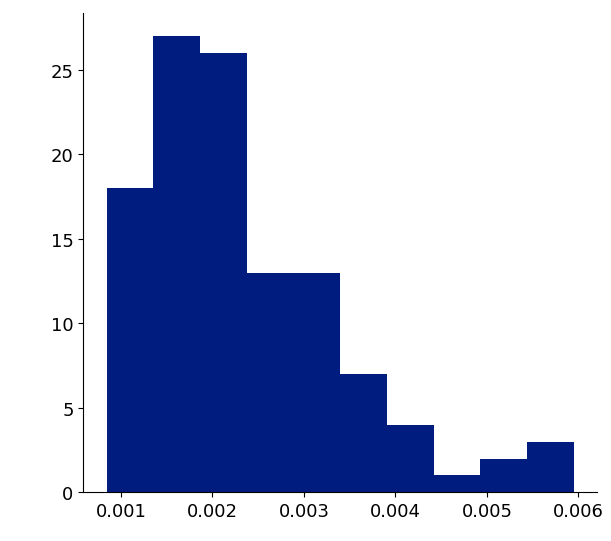

In [844]:
plt.HistogramPlot(cbo)


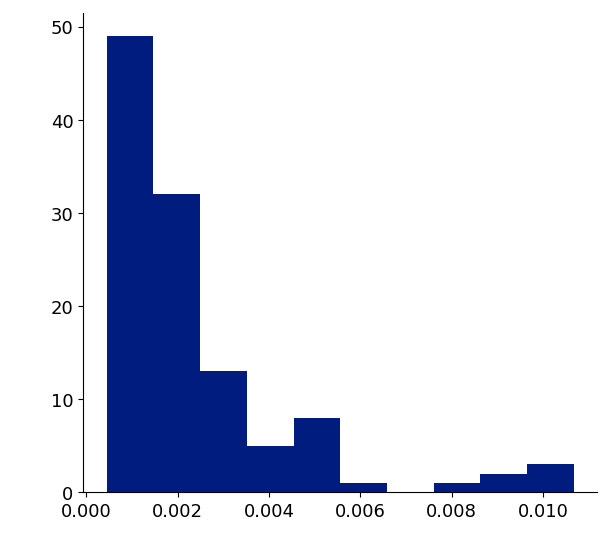

In [843]:
plt.HistogramPlot(cbz)

In [767]:
interactive.ModuleReloader("Psience.Molecools").reload()

In [778]:
from Psience.Molecools import Molecule

In [770]:
type(subwah[0].reactant).get_translation_rotation_projector = Molecule.get_translation_rotation_projector

(120, 120)


np.float64(0.00030640991450511486)

In [753]:
cbo, mbo, ebo = rda.get_compliances(subwah[0].reactant,
                                    use_obliques=True,
                                    nonzero_cutoff=1e-8,
                                    distance_units="Angstroms",
                                    force_units="PicoNewtons",
                                    modes_filter=lambda f: f > 5,
                                    return_mol=True,
                                    return_expansion=True)
np.average(cbo)

np.float64(0.003339975959754532)

In [752]:
czo, mzo, ezo = rda.get_compliances(subwah[0].reactant,
                                    use_obliques=True,
                                    use_zmatrix=True,
                                    nonzero_cutoff=1e-8,
                                    distance_units="Angstroms",
                                    force_units="PicoNewtons",
                                    modes_filter=lambda f: f > 5,
                                    return_mol=True,
                                    return_expansion=True)
np.average(czo)

np.float64(0.0033399759597545014)

In [627]:
cb, mb, eb = bond_compliances(subwah[0].reactant,
                              use_obliques=False,
                              normalize=True,
                              return_mol=True,
                              distance_order=True,
                              include_covalent_data=True,
                              nonzero_cutoff=1e-15,
                              units="PicoJoules",
                              return_expansion=True)
np.average(cb)

np.float64(0.020141846713747323)

In [628]:
cz, mz, ez = bond_compliances(subwah[0].reactant,
                              use_obliques=False,
                              use_zmatrix=True,
                              normalize=True,
                              units="PicoJoules",
                              nonzero_cutoff=1e-14,
                              return_mol=True,
                              return_expansion=True)
np.average(cz)

np.float64(0.03888044829847307)

In [625]:
cbo, mbo, ebo = bond_compliances(subwah[0].reactant,
                                 use_obliques=True,
                                 normalize=False,
                                 return_mol=True,
                                 distance_order=True,
                                 include_covalent_data=True,
                                 modes_filter=lambda f:f>50,
                                 units="PicoJoules",
                                 nonzero_cutoff=1e-14,
                                 return_expansion=True)
np.average(cbo)

np.float64(0.0023611645387693336)


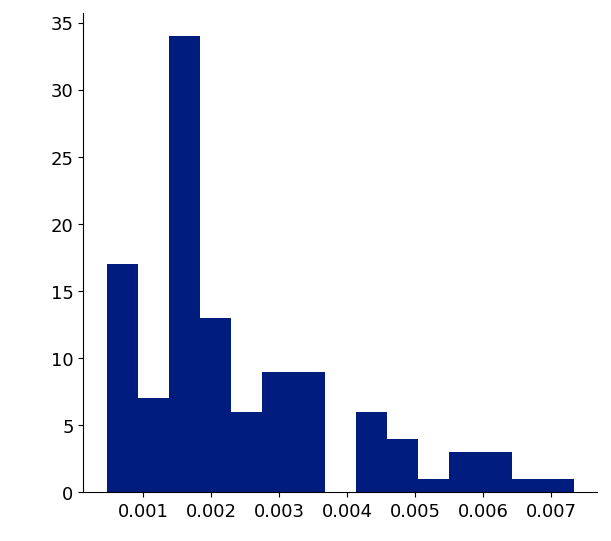

In [642]:
plt.HistogramPlot(cbo, bins=15)

In [ ]:
mbo.animate_coordinate(-40, coordinate_expansion=[ebo])

In [622]:
coordops.zmatrix_indices(mzo.internals['zmatrix'], (2, 3))

69

In [ ]:
mb.animate_coordinate(0, .25, coordinate_expansion=[eb])

In [ ]:
mb.animate_coordinate(69, .5, coordinate_expansion=[ez])

In [621]:
czo, mzo, ezo = bond_compliances(subwah[0].reactant,
                                 use_obliques=True,
                                 use_zmatrix=True,
                                 normalize=False,
                                 modes_filter=lambda f:f>50,
                                 units="PicoJoules",
                                 nonzero_cutoff=1e-14,
                                 return_mol=True,
                                 return_expansion=True)
np.average(czo)

np.float64(0.002361164538769374)

#### Fit Comparisons

In [134]:
rda = importlib.reload(rda)

In [132]:
tt = utils.read_tree('product_library_cyclop_b97_compliances_normalized.npz')

In [120]:
tt = utils.read_tree('product_library_cyclop_b97_compliances_normalized.npz')
tt_all, tt_means = rda.plot_compliance_data_distributions(tt)

In [229]:
tt_all, tt_means = rda.plot_compliance_data_distributions(tt,
                                                          # mean_function=np.max,
                                                          mean_cutoff=100,
                                                          plot_threshold=0.016,
                                                          # mean_cutoff=100,
                                                          # plot_threshold=.5,
                                                          means_styles=dict(
                                                              bins=250,
                                                              ticks=[[0, 0.005, 0.01, 0.015, 0.02], []],
                                                              # plot_range=[[-.001, .016], None],
                                                              # axes_labels=["Max", "N"]
                                                          )
                                                          )
# tt_means.savefig('figs/mean_compliance_distribution.svg')


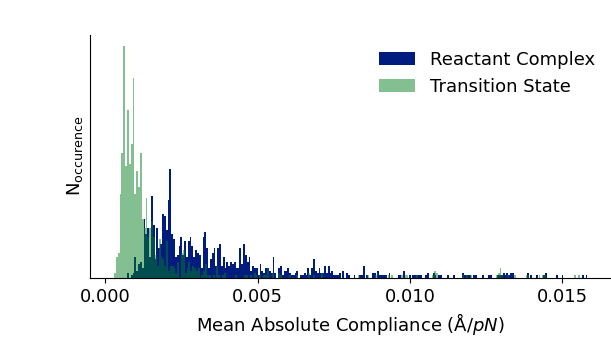

In [230]:
tt_means

In [33]:
# rda = importlib.reload(rda)

In [171]:
comp_data = rda.get_aggregate_compliances(
    {
        'Optimized': d2_uin,
        'Random': d2_rand,
        'Dihedrals': d2_int
    },
    tt,
    # mean_function=lambda d,weights=None,**_:np.max(d, **_),
    thresh=10
)


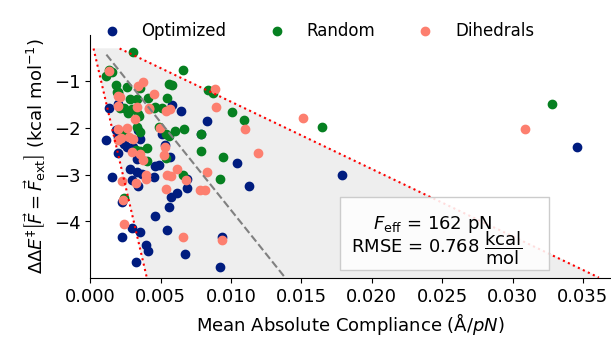

In [172]:
# interactive.ModuleReloader('McUtils.Plots').reload() 
rda = importlib.reload(rda)
comp_fit = rda.plot_compliance_fit(
    comp_data, 
    .02,
    image_size=[440, 250],
    plot_range=[[0, .037], [-5.2, 0]],
    padding=[[65, 0], [50, 25]],
    ticks=[None, [-1, -2, -3, -4]],
    model_bounds=[(100, .05), 300],
    which=1,
    # text_anchor=[.5, .7],
    text_background='#ffffffdd',
    style_list={
        'color':[
            plt.prep_color(palette='default', index=0),
            plt.prep_color(palette='default', index=1),
            plt.prep_color(palette='pastel', index=3)
        ]}
)
comp_fit#.savefig('figs/compliance_treatment_comp.svg')

In [29]:
# # fig = rda.plot_compliance_means(*cd, 
# #                                 image_size=[440, 250],
# #                                 ts_styles=None)
# fig = rda.plot_compliance_means(*comp_data_reg,
#                                 ts_styles=None,
#                                 label='Optimized',
#                                 image_size=[440, 300],
#                                 plot_legend=True,
#                                 legend_style={
#                                     'frameon': False,
#                                     'loc':'upper left',
#                                     'fontsize':12,
#                                     'bbox_to_anchor':[.55, 1]
#                                              },
#                                 axes_labels=[
#                                     'Compliance ($a_0^2$ $E_H^{-1}$)', r'$\Delta E_a$ (kcal mol${-1}$)']
#                                 )
# rda.plot_compliance_means(*comp_data_rand,
#                           ts_styles=None,
#                           figure=fig,
#                           label='Random',
#                           )
# rda.plot_compliance_means(*comp_data_int,
#                           ts_styles=None,
#                           figure=fig,
#                           label='Internals'
#                           )
# rr = np.linspace(np.min(compliances), -3.5 / params[0])
# plt.Plot(rr, model(rr), 
#          figure=fig,
#          linestyle='dashed',
#          color='gray',
# )
# plt.Text([fr'$\Delta E_a$ = {params[0]*1e3:.3f} $\eta$/1000'], [(4.2 * 1000, -.8)],
#         font_size=13
#         ).plot(fig)
# plt.Text([f'R$^2$ = {fit:.3f}'], [(4.25 * 1000, -1.2)],
#         font_size=13
#         ).plot(fig)
# fig

In [128]:
# fig = rda.plot_compliance_means(means, np.array(wop[0]) / 1e3, wop[1], ts_styles=None, 
#                           image_size=[440, 300],
#                          axes_labels=[
#                              r'Mean Compliance ($a_0^2$ $E_H^{-1} \times 10^{3})$', 
#                              r'$\Delta E_a$ (kcal mol${-1}$)'
#                          ]
#                          )#.savefig('compliance_mean_comp')
# plt.Plot(
#     np.linspace(0, 6),
#     residual_func(optimized_params, np.linspace(0, 6000), 0),
#     figure=fig,
#     linestyle='dashed',
#     color='gray'
# )
# plt.Text([f'$\Delta E_a$ = {optimized_params[0]*1e3:.3f} C + {optimized_params[1]:3f}'], [(4, -.8)],
#         font_size=13
#         ).plot(fig)
# plt.Text([f'R$^2$ = {r_squared:.3f}'], [(4.22, -1.2)],
#         font_size=13
#         ).plot(fig)
# fig.savefig('figs/compliance_mean_comp_rs_fitted.svg')

In [86]:
residuals

array([-0.09455916, -0.1926782 , -0.005616  , -0.09964651,  0.04339758,
        0.20628979, -0.29361372,  0.2867525 ,  0.02662298,  0.58748306,
       -0.54264224, -0.36476914,  0.25608232,  0.66114824,  0.20657559,
       -0.48283767,  0.05238267,  0.17009526, -0.58513935,  0.12106529,
       -0.60757636, -0.02074642, -0.43568861, -0.04928518, -0.278506  ,
        0.14123779, -0.08252768,  0.14876952, -1.24024879, -0.75235488,
        1.0984412 , -0.1326512 , -0.86399552, -0.41351234, -0.16830358,
        0.14491521,  0.1357255 ,  0.17948322, -0.14376751, -0.18461717,
       -0.05438291,  0.11814709,  0.86311763,  0.27112566, -0.22230759,
        0.18364354,  0.4973172 ,  0.08443381,  0.19600142,  0.33961952,
        1.29210013])


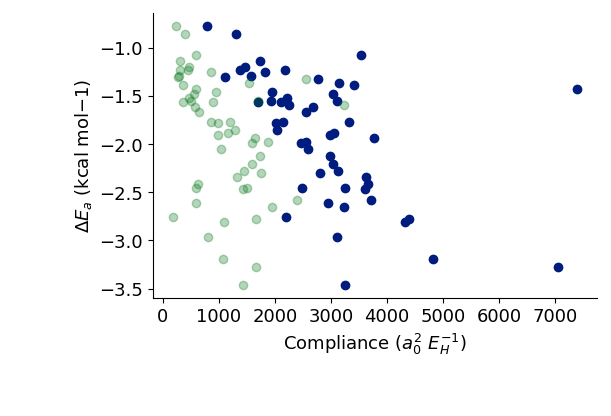

In [70]:
rda.plot_compliance_means(means, wop[0], wop[1],
                          image_size=[440, 300],
                         axes_labels=['Compliance ($a_0^2$ $E_H^{-1}$)', r'$\Delta E_a$ (kcal mol${-1}$)']
                         )

#### Outliers

In [15]:
np.where(comp_data['Optimized'][1] > .03)

(array([10]),)

In [17]:
comp_data['Optimized'][0][1][0]

np.float64(-1.5925051222032514)

In [18]:
comp_data['Optimized'][0][0][10]

('', 'CO CO')

In [39]:
[i for i,x in enumerate(comp_data['Optimized'][0][0]) if x[1] == 'CC(C)(C)C CC(C)(C)C']

[1]

In [69]:
np.exp(
    .4 * UnitsData.convert("BoltzmannConstant", ("Kilojoules/Mole", "InverseKelvins")) * 295
)

np.float64(2.6674063316666325)

In [41]:
comp_data['Optimized'][0][0][1]

array(['', 'CC(C)(C)C CC(C)(C)C'], dtype='<U37')

In [42]:
comp_data['Optimized'][0][1][1]

np.float64(-3.278521060668522)

In [45]:
comp_data['Optimized'][1][1]

np.float64(0.009305675337588633)

In [55]:
model_scaling(0.009305675337588633, 162)

-3.5150956899193533

In [47]:
def model_scaling(x, mag=100):
    return -(
                    mag * UnitsData.convert("PicoJoules", "Hartrees") /
                    UnitsData.convert("Meters", "BohrRadius")
            ) ** 2 * (
            x * UnitsData.convert("Angstroms", "BohrRadius")
            / (UnitsData.convert("PicoJoules", "Hartrees") / UnitsData.convert("Meters", "BohrRadius"))
    ) * UnitsData.convert("Hartrees", "Kilocalories/Mole")

In [92]:
comp_data_ext = rda.get_aggregate_compliances(
    {
        'Extended': d2_ext
    },
    tt,
    thresh=10
)

#### Global Plot

In [11]:
all_rs_compliances = np.concatenate([r for r,t in tt.values()])
all_ts_compliances = np.concatenate([t for r,t in tt.values()])

In [51]:
# fig = plt.HistogramPlot(
#     all_rs_compliances[np.abs(all_rs_compliances) < 2.0e4],
#     bins=250,
#     plot_range=[[-15100, 15100], None],
#     ticks=[[-10000, 0, 10000], []],
#     image_size=[450, 350],
#                   label='Reactant Complex',
#     plot_legend=True,
#     legend_style={'frameon':False, 'fontsize':13, 
#                   'loc':'upper left',
#                   'bbox_to_anchor':(-.025, 1.04)
#                  },
#     axes_labels=['Compliance ($a_0^2$ $E_H^{-1}$)', 'Counts']
# )
# plt.HistogramPlot(all_ts_compliances[np.abs(all_ts_compliances) < 2.0e4], 
#                   figure=fig,
#                   bins=250,
#                   label='Transition State',
#                   color=plt.prep_color(palette='default', index=1, alpha=.5))
# fig.savefig('figs/raw_compliance_distribution.svg')

In [107]:
distance_units = "Angstroms"
force_units = ("PicoJoules", "Meters")
conv = UnitsData.convert("BohrRadius", distance_units) / (
        UnitsData.convert("Hartrees", force_units[0]) /
        UnitsData.convert("BohrRadius", force_units[1])
    )

all_rs_means = np.array([np.mean(r[np.abs(r) < 2.5e4]) for r,t in tt.values()]) * conv
all_ts_means = np.array([np.mean(t[np.abs(t) < 2.5e4]) for r,t in tt.values()]) * conv

/Users/Mark/Documents/UW/Research/Development/McUtils/McUtils/Plots/Backends.py:4797: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  figure, axes = MPLManager.plt_api().subplots(*args, **kwargs)



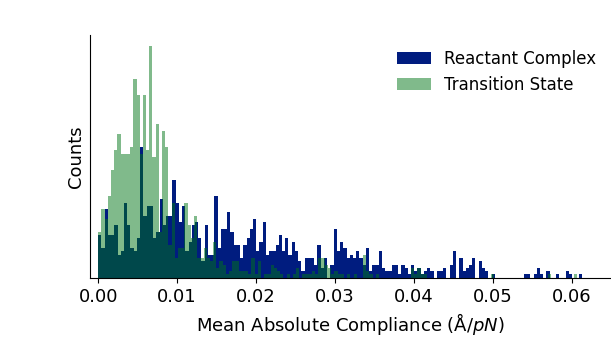

In [130]:
fig = plt.HistogramPlot(
    np.abs(all_rs_means),
    bins=150,
    plot_range=[[-.001, .065], None],
    ticks=[None, []],
    padding=[[65, 0], [50, 25]],
    image_size=[440, 250],
    label='Reactant Complex',
    plot_legend=True,
    legend_style={'frameon': False, 'fontsize': 12,
                  'loc': 'upper right',
                  # 'bbox_to_anchor':(-.025, 1.04)
                  },
    axes_labels=['Mean Absolute Compliance ($\mathrm{\AA} / pN$)', 'Counts']
)
plt.HistogramPlot(np.abs(all_ts_means),
                  figure=fig,
                  bins=150,
                  label='Transition State',
                  color=plt.prep_color(palette='default', index=1, alpha=.5))
fig.savefig('figs/mean_compliance_distribution.svg')
fig

##### Old


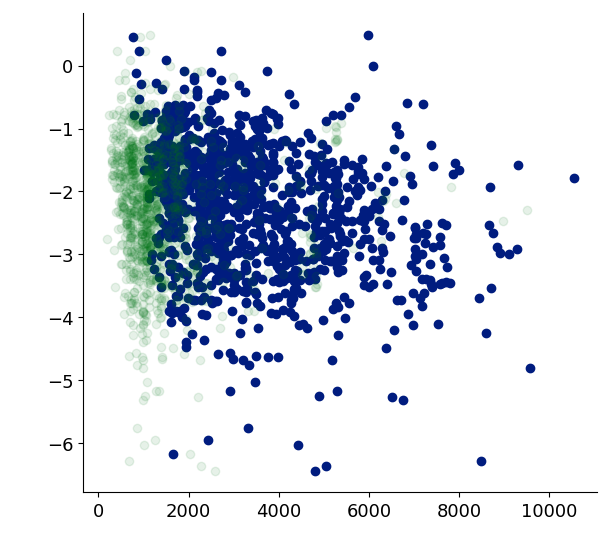

In [142]:
f1 = plt.ScatterPlot(
    rs_means,
    np.array(means[1])[:, 0]
)
plt.ScatterPlot(
    ts_means,
    np.array(means[1])[:, 0],
    figure=f1,
    color=plt.prep_color(palette='default', alpha=.1, index=1)
)

In [156]:
means2 = rda.extract_group_means(wah[2])

In [159]:
rs_means2 = [
    np.mean(np.concatenate([
        np.abs(tt[p][0])[np.abs(tt[p][0]) < 2.5e4]
        for p in wah[2][k].d_path
    ]))     
    for k in means2[0]
]
ts_means2 = [
    np.mean(np.concatenate([
        np.abs(tt[p][1])[np.abs(tt[p][1]) < 2.5e4]
        for p in wah[2][k].d_path
    ]))     
    for k in means2[0]
]

#### Functional Group Analysis

In [99]:
distance_units = "Angstroms"
force_units = ("PicoJoules", "Meters")
conv = UnitsData.convert("BohrRadius", distance_units) / (
        UnitsData.convert("Hartrees", force_units[0]) /
        UnitsData.convert("BohrRadius", force_units[1])
    )
def get_test_compliances(func=None,
                         root=pipeline.BASE_DIENOPHILES['ethene'],
                         max_iterations=500,
                         chiralities=None,
                         stereos=None,
                         ):
    if func is not None:
        if isinstance(func, (str, dict)):
            func = [func]
        root = extprog.build_templated_smiles(
            root,
            *func,
            chiralities=chiralities,
            stereos=stereos
        )
    hmm = Molecule.from_string(
        root,
        add_implicit_hydrogens='full',
        energy_evaluator='aimnet2:aimnet2-2025'
    )
    hmm = hmm.optimize(max_iterations=max_iterations)
    hmm.get_normal_modes()
    comps, hmm = rda.get_compliances(hmm, return_mol=True)
    ord_comp = np.argsort(comps)
    sort_comps = comps[ord_comp,] * conv
    return (root, hmm), np.mean(np.abs(sort_comps)[np.abs(sort_comps) < .02]), (ord_comp, sort_comps)

In [3]:
eth_data = get_test_compliances()
eth_data[1]

0.00011813882564907614

In [180]:
sulf_data = get_test_compliances(pipeline.BASE_FRAGMENTS['sulfonyl-phenyl'])
sulf_data[1]

0.0030522964766507782

In [181]:
tbu_data = get_test_compliances(pipeline.BASE_FRAGMENTS['tBu'])
tbu_data[1]

0.002389008002283996

In [196]:
# import McUtils.Jupyter as interactive
# interactive.ModuleReloader('McUtils.ExternalPrograms').reload()
# import McUtils.ExternalPrograms as extprog

In [4]:
tbu2_data = get_test_compliances(
    [
        pipeline.BASE_FRAGMENTS['tBu'],
        pipeline.BASE_FRAGMENTS['tBu']
    ],
    stereos={(0, 1): 'cis'},
    max_iterations=500
)
print(tbu2_data[1])  # 0.008320247853953213
# tbu2_data[0]

0.00609809045202935


In [16]:
pipeline.BASE_FRAGMENTS['tBu']

'[C:1]C(C)(C)(C)'

In [35]:
Chem.BondDir.EITHERDOUBLE

rdkit.Chem.rdchem.BondDir.EITHERDOUBLE

In [5]:
ttbu2_data = get_test_compliances(
    [
        '[C:1](C)(C)(C)',
        '[C:1](C)(C)(C)'
    ],
    stereos={(0, 1): 'trans'},
    max_iterations=500)
print(ttbu2_data[1])  # 0.00855257352059085
# tbu2_data[0]

0.005024635050374527


In [28]:
UnitsData.convert("Hartrees", "Kilocalories/Mole")

627.5094740630558

In [ ]:
ttbu2_data[0][1].animate_coordinate(25)

In [19]:
tbu2_data = get_test_compliances(
    [
        pipeline.BASE_FRAGMENTS['tBu'],
        pipeline.BASE_FRAGMENTS['tBu']
    ],
    stereos={(0, 1): 'trans'},
    max_iterations=500)
print(tbu2_data[1])  # 0.00855257352059085
# tbu2_data[0]

0.008466577752635434


In [22]:
sulf2_data_cyc = get_test_compliances(
    [
        pipeline.BASE_FRAGMENTS['sulfonyl-phenyl'],
        pipeline.BASE_FRAGMENTS['sulfonyl-phenyl']
    ],
    root='[C:1]([C:5]2)[C:3]=[C:4][C:2]2',
    stereos={(0, 1): 'trans'},
    max_iterations=500)
print(sulf2_data[1])
# sulf2_data[0]

AttributeError: 'NoneType' object has no attribute 'SetStereo'

In [18]:
sulf2_data = get_test_compliances(
    [
        pipeline.BASE_FRAGMENTS['sulfonyl-phenyl'],
        pipeline.BASE_FRAGMENTS['sulfonyl-phenyl']
    ],

    stereos={(0, 1): 'trans'},
    max_iterations=500)
print(sulf2_data[1])
# sulf2_data[0]

0.010694860796685239


In [12]:
sulf2_data = get_test_compliances(
    [
        pipeline.BASE_FRAGMENTS['sulfonyl-phenyl'],
        pipeline.BASE_FRAGMENTS['sulfonyl-phenyl']
    ],

    stereos={(0, 1): 'cis'},
    max_iterations=500)
print(sulf2_data[1])
# sulf2_data[0]

0.0057612838865721125


In [166]:
pfph_data = get_test_compliances(pipeline.BASE_FRAGMENTS['pF-phenyl'])
pfph_data[1]

0.0005447620560841304

In [167]:
sch_data = get_test_compliances(pipeline.BASE_FRAGMENTS['sulfonyl-chex'])
sch_data[1]

0.0035536989410104108

In [197]:
tbu_data = get_test_compliances(pipeline.BASE_FRAGMENTS['tBu'])
tbu_data[1]

array([  9.86435162,  10.87731564,  14.56121257,  15.61446487,
        16.37259691,  17.37916862,  18.44899164,  19.33859077,
        20.08855019,  21.67759395,  22.29260665,  28.31564049,
        32.49895533,  38.64478399,  39.76432265,  46.21747006,
        47.02719959,  48.58867743,  48.78992027,  49.25894664,
        50.72991996,  53.95148087,  54.94431393,  59.26451503,
        60.2867935 ,  77.76095259,  82.8172919 ,  84.52283751,
        86.99245274, 108.62601354, 244.99123035, 264.3688583 ,
       300.24060937])

In [195]:
hmm = Molecule.from_string(
    extprog.build_templated_smiles(
        pipeline.BASE_DIENES['cyclopentadiene'],
        pipeline.BASE_FRAGMENTS['sulfonyl-phenyl']
    ),
    add_implicit_hydrogens='full',
    energy_evaluator='aimnet2'
)
hmm = hmm.optimize(max_iterations=500)
hmm.get_normal_modes()
np.sort(rda.get_compliances(hmm))

array([  25.29388166,   42.5233519 ,   48.98082369,   52.33646605,
         53.42809244,   71.83414775,   90.90897671,   92.33484665,
        107.01227056,  118.61740259,  123.93904544,  144.17777665,
        146.96193793,  148.32366229,  152.30940831,  156.88062474,
        157.66359773,  163.86793194,  164.38583546,  166.82184804,
        173.50106279,  186.89685223,  208.56409707,  217.52355155,
        224.47008644,  236.76715501,  239.28585033,  242.12740271,
        251.93346614,  257.77085838,  271.11618567,  284.02421604,
        331.62235035,  343.81883138,  345.46533334,  356.03381341,
        360.59322763,  365.52193089,  379.55484563,  382.63885903,
        388.38097646,  392.57282342,  400.77178329,  416.39896166,
        418.72571807,  419.5390305 ,  477.70304719,  486.00764003,
        486.07917629,  498.40745675,  517.03138591,  526.63881307,
        556.86920359,  560.31105131,  566.95402461,  577.33630537,
        595.41244226,  607.05076107,  613.72006131,  678.87718

In [194]:
hmm = Molecule.from_string(
    extprog.build_templated_smiles(
        pipeline.BASE_DIENES['cyclopentadiene'],
        pipeline.BASE_FRAGMENTS['pF-phenyl']
    ),
    add_implicit_hydrogens='full',
    energy_evaluator='aimnet2'
)
hmm = hmm.optimize(max_iterations=500)
hmm.get_normal_modes()
np.sort(rda.get_compliances(hmm))

array([ 18.77736046,  29.7700836 ,  31.43755259,  38.23366067,
        39.57045485,  39.57350152,  43.27720475,  45.68167231,
        48.17869427,  77.44224117,  79.15515098,  79.37023739,
        81.76058666,  89.13048877,  91.64381705,  96.37683158,
        98.66240218,  99.7506184 , 100.28493786, 102.29888132,
       109.06833723, 114.83771731, 119.60115886, 121.90740013,
       122.51798134, 128.71715033, 130.91253273, 133.64657135,
       134.24488195, 140.81850945, 159.90442265, 174.9498482 ,
       175.51335501, 197.7789558 , 198.17121238, 198.82879094,
       208.38754136, 218.23991025, 227.32056664, 245.16975262,
       265.19490599, 290.53495964, 296.44333169, 300.65246066,
       305.94928873, 318.94722465, 324.17601604, 330.48962944,
       336.06770615, 350.36287804, 358.56326685, 395.61882742,
       455.93825262, 478.73877382, 569.76953507, 588.60113086,
       613.85115134, 619.8424084 , 643.12701132, 648.92962798,
       673.46997396, 715.91964563, 914.89920663])

In [ ]:
Molecule.from_string(
    extprog.build_templated_smiles(
        pipeline.BASE_DIENES['cyclopentadiene'],
        pipeline.BASE_FRAGMENTS['sulfonyl-chex']
    ),
    add_implicit_hydrogens='full',
    energy_evaluator='aimnet2'
)

In [196]:
hmm = Molecule.from_string(
    extprog.build_templated_smiles(
        pipeline.BASE_DIENES['cyclopentadiene'],
        pipeline.BASE_FRAGMENTS['sulfonyl-chex']
    ),
    add_implicit_hydrogens='full',
    energy_evaluator='aimnet2'
)
hmm = hmm.optimize(max_iterations=500)
hmm.get_normal_modes()
np.sort(rda.get_compliances(hmm))

array([  135.08728254,   136.41513681,   137.99352163,   155.33503208,
         169.57908407,   204.37295034,   213.41326045,   213.9789561 ,
         222.5287975 ,   233.35320131,   266.84449681,   310.06795991,
         321.19495269,   328.40329811,   335.69670197,   349.80401062,
         353.80411863,   411.58655992,   413.62782166,   419.06033771,
         420.48627228,   428.75744109,   451.75064073,   452.74323099,
         457.52467385,   467.60249569,   469.47351441,   478.86838251,
         486.47350742,   487.29593481,   514.52656169,   525.07271294,
         536.68749453,   546.13916798,   556.39613671,   567.00179916,
         632.68968863,   640.86121269,   643.68566076,   651.24772049,
         666.33102996,   684.4324817 ,   698.09869901,   706.23265905,
         766.48662723,   767.72220821,   782.49125493,   805.26230386,
         809.54073769,   814.84157176,   821.49670115,   821.7745008 ,
         892.84671901,   897.98150959,  1021.44193926,  1024.37893688,
      

In [ ]:
Molecule.from_string(
    extprog.build_templated_smiles(
        pipeline.BASE_DIENOPHILES['ethene'],
        pipeline.BASE_FRAGMENTS['pF-phenyl']
    ),
    add_implicit_hydrogens='full',
    energy_evaluator='aimnet2'
)

In [ ]:
Molecule.from_string(
    extprog.build_templated_smiles(
        pipeline.BASE_DIENES['cyclopentadiene'],
        pipeline.BASE_FRAGMENTS['sulfonyl-phenyl']
    ),
    add_implicit_hydrogens='full',
    energy_evaluator='aimnet2'
)

In [ ]:
hmm = Molecule.from_string(
    extprog.build_templated_smiles(
        pipeline.BASE_DIENOPHILES['ethene'],
        pipeline.BASE_FRAGMENTS['pF-phenyl']
    ),
    add_implicit_hydrogens='full',
    energy_evaluator='aimnet2'
)
hmm = hmm.optimize(max_iterations=500)
hmm.get_normal_modes()
np.sort(rda.get_compliances(hmm))

In [182]:
extprog.build_templated_smiles(
    pipeline.BASE_DIENOPHILES['ethene'],
    pipeline.BASE_FRAGMENTS['sulfonyl-phenyl']
)
    

'O=[S:3](=O)(c1ccccc1)[CH:1]=[CH2:2]'


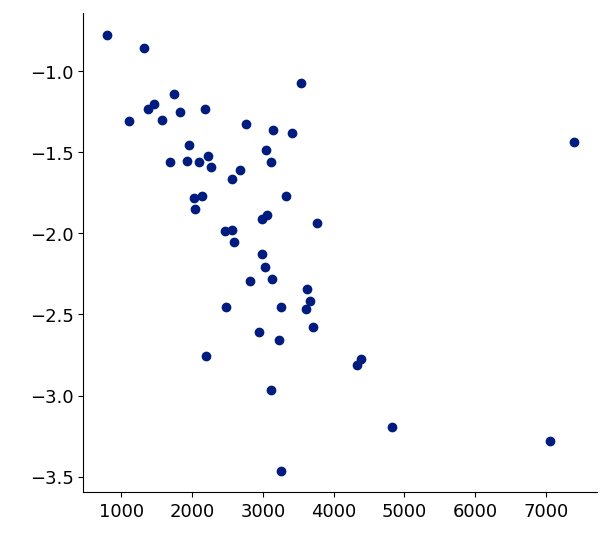

In [163]:
f1 = plt.ScatterPlot(
    rs_means2,
    np.array(means2[1])[:, 0]
)
# plt.ScatterPlot(
#     ts_means2,
#     np.array(means2[1])[:, 0],
#     figure=f1,
#     color=plt.prep_color(palette='default', alpha=.3, index=1)
# )
f1

#### asdasdasdasd

In [102]:
vd = list(tt.values())
class MockData:
    def __init__(self, i):
        self.i = i
        self.rs = self.SysId(i, 0)
        self.ts = self.SysId(i, 1)
    class SysId:
        def __init__(self, i, tag):
            self.id = (i, tag)
            self.i = i
            self.t = tag
i = 90
wm = means[1][i]
rda.freq_comp_plot(
    [MockData(i)],
    freq_gen=lambda m:np.abs(vd[m.i][m.t]),
    plot_label=(
                                   f"Mean: {wm[0]:.2f} kcal/mol Std: {wm[1]:.2f} kcal/mol"
                                   if wm is not None else None
                    ),
    display_format='svg',
    plot_range=[[-2000, 25000], None]
)


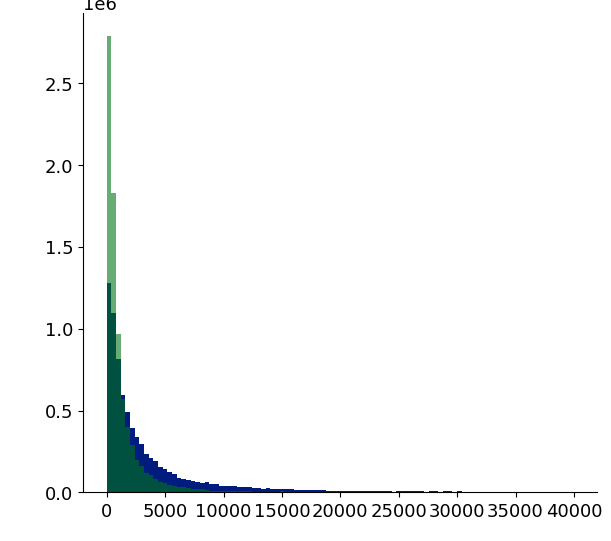

In [150]:
fig = plt.HistogramPlot(
    np.abs(all_rs)[np.abs(all_rs) < 4e4], 
    bins=100
)
plt.HistogramPlot(
    np.abs(all_ts)[np.abs(all_ts) < 4e4], 
    bins=100, figure=fig,
    color=plt.prep_color(palette='default', alpha=.6, index=1)
    )


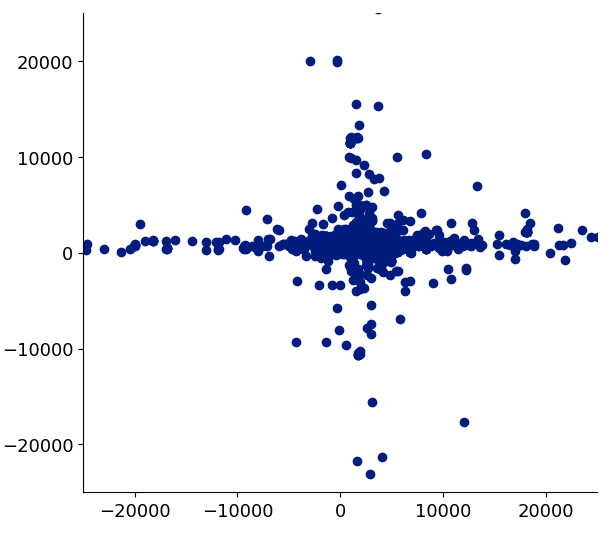

In [48]:
plt.ScatterPlot(*np.array(list(means.values())).T, 
                plot_range=[
                    [-25000, 25000],
                    [-25000, 25000]
                ])

In [5]:
wah = rda.get_dienophile_groups(d2_reg)

In [6]:
dp_wah = wah[0].group_by_props('d_path')

In [8]:
rs_1, ts_1 = rda.freq_comp_data(itut.first(dp_wah.values()), freq_gen=rda.get_compliances)

In [ ]:
dp_wah_data = {
    k:echo_means(freq_comp_data(ds, freq_gen=get_compliances))
    for k,ds in dp_wah.items()
}

In [4]:
rs_1, ts_1 = rda.freq_comp_data(itut.first(dp_wah.values()), freq_gen=da.get_compliances)

NameError: name 'dp_wah' is not defined

In [54]:
echo_means = lambda x:(print(np.mean(x[0]), np.mean(x[1])), x)[-1]

In [27]:
dp_means = rda.extract_group_means(dp_wah)

In [50]:
np.mean(rs_1) - np.mean(ds_1)

1440.8843798806888

In [49]:
np.mean(ds_1)

387.8128949548534

In [19]:
opt = d2_reg[100]
freq_comp_plot(opt, 
               plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol",
               freq_gen=get_compliances,
               display_format='svg')

In [20]:
opt = d2_reg[1000]
freq_comp_plot(opt, 
               plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol",
               freq_gen=get_compliances,
               display_format='svg')

In [21]:
opt = d2_reg[1500]
freq_comp_plot(opt, 
               plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol",
               freq_gen=get_compliances,
               display_format='svg')

In [ ]:
wah = rda.get_dienophile_groups(d2_reg)
wah_keys, wah_means = rda.extract_group_means(wah[2])
wah_sort = np.argsort([w[0] for w in wah_means])
wah_sort2 = np.argsort([w[1] for w in wah_means])
# wah_sort2 = wah_sort2[[wah_means[x][1] > 0 for x in wah_sort2]]
ix = wah_sort2[-2]
fig_dir = "figs/compliance_comps"
os.makedirs(fig_dir, exist_ok=True)
for k,ix in enumerate(wah_sort2):
    wk, wm = wah_keys[ix], wah_means[ix]
    fig = plot_dataset_freq_comp(wah[2][wk], 
                                 freq_gen=get_compliances,
                                 plot_range=[[-25000, 25000], None])
    fig.savefig(f'{fig_dir}/std_sorted_{k}.svg')
    fig.close()

In [213]:
np.linalg.pinv(mol0.potential_derivatives[1])

array([[  3407400.27588832,  -5783564.89214674,  -4616060.4953901 , ...,
          3405290.59496675,  -5783470.33836153,  -4613712.0050972 ],
       [ 38244348.73883264,  35242480.79884064,  65158048.15245239, ...,
         38260438.11266392,  35244785.22498289,  65118874.89107312],
       [-22247288.85950033,   2860194.55581931, -23725183.15092478, ...,
        -22249151.6678341 ,   2858716.27119843, -23712071.16630827],
       ...,
       [  3409669.74159548,  -5779778.99171159,  -4611369.63769709, ...,
          3407163.10415031,  -5779631.52840709,  -4608889.43172895],
       [ 38242974.66509204,  35242261.31257007,  65156388.70555551, ...,
         38259116.57695449,  35244571.28244741,  65117240.44074404],
       [-22240616.43674217,   2856554.4411888 , -23719791.54706907, ...,
        -22242344.82921445,   2855100.63732033, -23707097.28848815]])

(903, 2)

In [252]:
zm1 = mol0.get_bond_zmatrix()

In [304]:
j1 = mol0.modify(internals=zm1).get_cartesians_by_internals(1)

In [264]:
int_H1 = nput.tensor_reexpand(
    mol0.modify(internals=zm1).get_cartesians_by_internals(1), 
    [0, mol0.potential_derivatives[1]]
)[1]

In [270]:
int_H2 = nput.tensor_reexpand(
    mol0.modify(internals=zm2).get_cartesians_by_internals(1), 
    [0, mol0.potential_derivatives[1]]
)[1]

In [272]:
import McUtils.Coordinerds as coordops 

In [274]:
bonds1 = [i for i in coordops.extract_zmatrix_internals(zm1) if len(i) == 2]
bonds2 = [i for i in coordops.extract_zmatrix_internals(zm2) if len(i) == 2]

In [289]:
shared, _, _, x1, x2 = nput.intersection(bonds1, bonds2, return_indices=True)

In [303]:
np.linalg.pinv(int_H1)[x1, x1] - np.linalg.pinv(int_H2)[x2, x2]

array([ 1.69612951e+00,  1.36282355e-01, -1.05081259e-01, -1.27265026e+00,
       -6.86451676e+00,  1.92339505e-02,  9.37254176e+00, -1.08360117e+07,
       -1.44677612e+00,  4.74235245e-01,  2.49475574e+00, -1.41777404e+00,
       -1.30083066e+01, -3.12536463e-03, -1.02754746e+01, -1.06409714e+01,
        2.36820679e+07,  1.06409714e+01,  1.22006100e+06, -1.00232539e+08,
       -9.98480443e+00,  1.01329980e+00,  3.50333231e+06,  8.47239802e+00,
       -1.11393737e+07,  9.98480443e+00, -1.38163531e+07,  2.28757107e+00,
        2.45022069e+01, -3.54912244e+01, -6.30976239e-01,  1.27308735e+01,
        1.15539241e+01, -2.39059196e+00, -1.95066199e+01, -5.03159476e+01,
       -3.19156084e+01,  2.36612019e+00])

In [ ]:
mol0.modify(internals=zm1).animate_coordinate(15)

In [258]:
zm2 = mol0.get_bond_zmatrix(root=[8])

In [ ]:
mol0.modify(internals=zm2).animate_coordinate(15)

In [ ]:
mol0.modify(internals=zm1).get_cartesians_by_internals()

In [335]:
exps = coordops.RedundantCoordinateGenerator(
    [tuple(x) for x in nput.combination_indices(len(mol0.atoms), 2)],
    masses=mol0.atomic_masses
).compute_redundant_expansions(mol0.coords, order=1)

In [341]:
exps[1]

[array([[-2.54152198e-01,  7.15650698e-02,  4.36258857e-03, ...,
          4.30467072e-02, -8.79107771e-03,  3.60207625e-02],
        [-8.46958241e-03, -5.13740322e-02,  1.12484369e-01, ...,
          1.37173721e-02, -2.07998512e-03, -3.62721436e-02],
        [-8.74286898e-02,  5.41532695e-02, -9.62650611e-04, ...,
         -1.22248218e-01,  1.11312815e-01, -1.28564519e-01],
        ...,
        [-7.31107962e-01,  2.95077160e-01,  3.49493587e-03, ...,
          3.66663399e-03,  2.46751130e-05,  3.74624635e-03],
        [-4.26396791e-01,  1.29453245e-01,  1.47504272e-01, ...,
         -6.72791382e-04, -4.62553845e-04, -3.69161790e-03],
        [-2.53776206e-01,  1.34028022e-01, -2.68663414e-03, ...,
         -9.14850557e-03,  8.55390288e-03, -5.46282295e-03]])]

In [312]:
ic, inv = nput.internal_coordinate_tensors(
    mol0.coords,
    [tuple(x) for x in nput.combination_indices(len(mol0.atoms), 2)],
    masses=mol0.atomic_masses,
    order=1,
    return_inverse=True
)
    

In [319]:
g1 = ic[1].T @ np.diag(np.repeat(1/mol0.atomic_masses, 3)) @ ic[1]
z, q = np.linalg.eigh(g1)
q = q[:, z > 1e-8]

In [313]:
inv_comp = nput.tensor_reexpand(inv, [0, mol0.potential_derivatives[1]])[1]

In [322]:
c1 = (q.T @ nput.frac_powh(inv_comp, -1, nonzero_cutoff=1e-6) @ q)

In [324]:
np.diag(c1)

array([ 6318.95399878,  9666.20427105, 16759.66616316,   879.206826  ,
        2018.25642425,  1102.50194066,  1550.87609433, 35359.36488541,
        3699.16235534,  1219.67026865,  8345.05348284,   623.43788902,
         375.50620884,  1775.58163254,  1832.60527188,   369.00194542,
        1752.38588015,   173.77902057,  6439.19414453,  8039.44949563,
         804.0121592 ,  3170.32953766,   104.99180529,   313.18640035,
         468.08340675,  3207.10873501,   300.43954201,   746.25889795,
         997.44430681,  3018.37756662,  1790.19741338,  1282.80482394,
        1352.02841357,  1464.78804576,  1441.7296799 ,  1302.28733862,
       19563.37320195, 11619.74013223, 10107.11511515,  3842.36971034,
        1664.41370074,   878.41920008, 10597.87015544,  3987.84049698,
       10524.61865455,  1399.03230201, 17799.21846066,  6405.59019855,
        2014.6734481 ,  1157.64626644,  2201.55146293,  3746.42813689,
        1632.83199595,  4378.42624608,  1290.14342402,  1076.36473545,
      

In [314]:
np.max(np.abs(nput.frac_powh(inv_comp, -1, nonzero_cutoff=1e-6)))

16659.404680625143

In [244]:
woof = np.linalg.pinv(
    nput.tensor_reexpand(inv, [0, mol0.potential_derivatives[1]])[1]
)

In [ ]:
def compliance_matrix(mol):
    ...
def compliance_matrix(mol):
    ...

In [ ]:
ix = 13
wk, wm = wah_keys[ix], wah_means[ix]
ds = wah[2][wk]
plot_dataset_freq_comp(ds)

In [ ]:
freq_comp_plot(v1[-1], 
               plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol",
              display_format='svg')

In [ ]:
opt = d2_reg[100]
freq_comp_plot(opt, plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol",
              display_format='svg')

In [ ]:
opt = d2_reg[50000]
freq_comp_plot(opt, plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol")

In [ ]:
opt = d2_reg[200]
freq_comp_plot(opt, plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol")

In [ ]:
opt = d2_reg[1000]
freq_comp_plot(opt, plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol")

In [ ]:
opt = d2_reg[1800]
freq_comp_plot(opt, plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol")


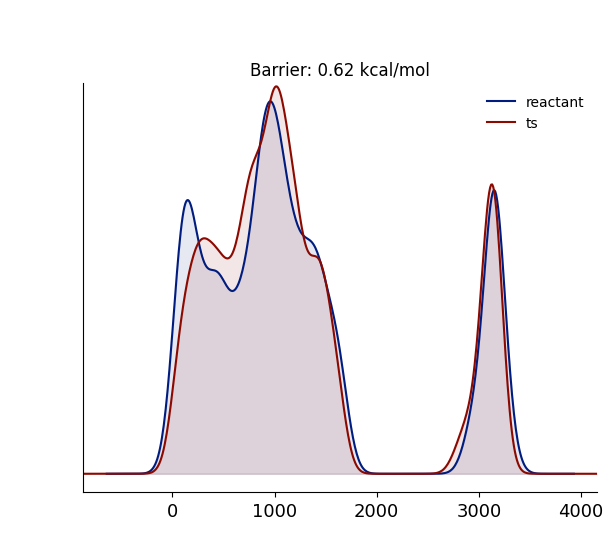

In [84]:
opt = d2_reg[1000]
freq_comp_plot(opt, plot_label=f"Barrier: {rda.fmrd_barrier(opt):.2f} kcal/mol")


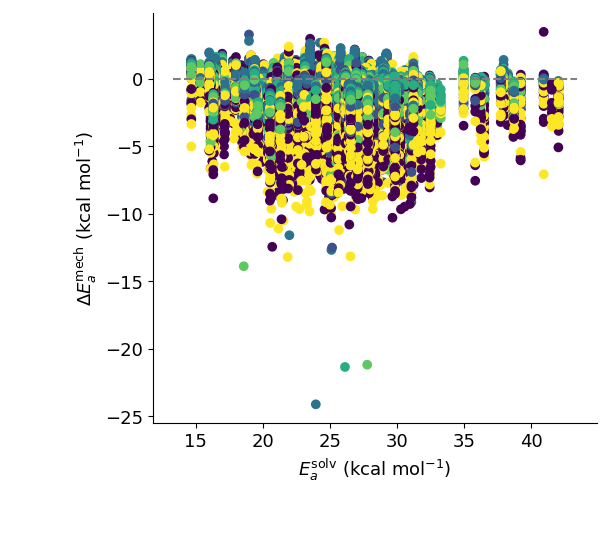

In [3]:
d2_reg.plot()

### Functional Group Means

In [473]:
# rda = importlib.reload(rda)

In [ ]:
d2_groups = rda.get_dienophile_groups(d2_reg)
d2_groups_int = rda.get_dienophile_groups(d2_int)
d2_groups_rand = rda.get_dienophile_groups(d2_rand)

#### Table

In [285]:
kms_reg = dict(zip(*rda.extract_group_means(d2_groups[2])))
kms_int = dict(zip(*rda.extract_group_means(d2_groups_int[2])))
kms_rand = dict(zip(*rda.extract_group_means(d2_groups_rand[2])))

In [ ]:
d2_groups_ext = rda.get_dienophile_groups(d2_ext)
kms_ext = dict(zip(*rda.extract_group_means(d2_groups_ext[2])))

In [89]:
fg_mapping = {
    'O=[SH](=O)c1ccccc1':'SO$_2$-Ph',
    'O=[SH](=O)C1CCCCC1':'SO$_2$-hex',
    'CC(C)(C)C':'Me-t-Bu',
    'Fc1ccccc1':'pF-Ph',
    'CO':'OMe',
    'CN':'CNH2',
    'CC(C)C':'t-Bu',
}

scoring = {v:(10)**i + 1 for i,v in enumerate([
    'CNH2',
    'OMe',
    't-Bu',
    'Me-t-Bu',
    'pF-Ph',
    'SO$_2$-Ph',
    'SO$_2$-hex'
])}
def replace_fgroups(subs):
    for k,v in fg_mapping.items():
        subs = subs.replace(k, v)
    return subs
def restore_fgroups(subs):
    for k,v in fg_mapping.items():
        subs = subs.replace(v, k)
    return subs
def restore_fgkey(key):
    return tuple(restore_fgroups(s) for s in key)
def score_fg(fg):
    return sum(
        scoring.get(f, 0)
            for f in fg.split()
    )

In [307]:
all_keys = sorted(
    [(replace_fgroups(k1), replace_fgroups(k2)) for k1, k2 in 
     itut.delete_duplicates(
        list(kms_reg) + list(kms_int) + list(kms_rand)
    )
    ],
    key=lambda x:score_fg(x[0]) + score_fg(x[1]) + (
        0
            if x[1] == '' else 
        1 
            if x[0] == '' else 
        2
    )
)
all_table_data = {
    'Regular':[
        [
            x if not nput.is_int(x) else str(x)
                for x in
            kms_reg.get(restore_fgkey(k), ['-', '-', '-'])
        ]
        for k in all_keys
    ],
    'Random':[
        [
            x if not nput.is_int(x) else str(x)
                for x in
            kms_rand.get(restore_fgkey(k), ['-', '-', '-'])
        ]
        for k in all_keys
    ],
    'Internals':[
        [
            x if not nput.is_int(x) else str(x)
                for x in
            kms_int.get(restore_fgkey(k), ['-', '-', '-'])
        ]
        for k in all_keys
    ]
}

In [ ]:
wap = rda.format_group_table(
        [(k[0].replace(" ", "+"), k[1].replace(" ", "+"))
         for k in all_keys], all_table_data,
        column_join=' & ',
        row_join=r'\\'+'\n',
        separator=' '
    )
print(wap)

In [82]:
def combine_standard_deviations(sample_sizes, means, std_devs):
    """
    Combines k standard deviations given their sample sizes and means.
    
    Parameters:
    sample_sizes (list or array): Number of samples (n) for each group
    means (list or array): Mean (x_bar) for each group
    std_devs (list or array): Standard deviation (s) for each group
    
    Returns:
    float: The combined standard deviation
    """
    # Convert inputs to numpy arrays for element-wise operations
    n = np.array(sample_sizes)
    x_bar = np.array(means)
    s = np.array(std_devs)
    
    # 1. Calculate total number of samples
    n_total = np.sum(n)
    if n_total == 1: return 0
    
    # 2. Calculate the overall combined mean
    combined_mean = np.sum(n * x_bar) / n_total
    
    # 3. Calculate within-group variance sum: sum((n_i - 1) * s_i^2)
    within_group = np.sum((n - 1) * (s ** 2))
    
    # 4. Calculate between-group variance sum: sum(n_i * (x_bar_i - combined_mean)^2)
    between_group = np.sum(n * ((x_bar - combined_mean) ** 2))
    
    # 5. Combine and divide by total degrees of freedom (N - 1)
    combined_variance = (within_group + between_group) / (n_total - 1)
    
    # 6. Return the standard deviation (square root of variance)
    return np.sqrt(combined_variance)

In [326]:
merged_table_data = [
    [
            ds.get(restore_fgkey(k), [0, 0, 0])
            for ds in [
                kms_reg,
                kms_rand,
                kms_int
            ]
        ]
        for k in all_keys
    ]
merged_table_data = [
    [
        np.average([x[0] for x in d], weights=[x[2] for x in d]),
        combine_standard_deviations([x[2] for x in d], [x[0] for x in d], [x[1] for x in d]),
        str(np.sum([x[2] for x in d]))
    ]
    for d in merged_table_data
]

In [327]:
wap = rda.format_group_table(
        [(k[0].replace(" ", "+"), k[1].replace(" ", "+"))
         for k in all_keys],
    merged_table_data,
        column_join=' & ',
        row_join=r'\\'+'\n',
        separator=' '
    )
print(wap)

    Diene Funcs     &     Diop Funcs.     & Mean  & Std  & Counts\\
                                                                 \\
                 CN &                     & -1.24 & 0.71 &     80\\
                    &                  CN & -0.83 & 0.90 &     23\\
              CN+CN &                     & -1.55 & 1.09 &     56\\
                    &               CN+CN & -1.18 & 1.23 &    267\\
                 CN &                  CN & -1.39 & 1.07 &    303\\
                 CO &                     & -2.75 & 0.00 &      1\\
                    &                  CO & -0.96 & 1.37 &     97\\
              CO+CN &                     & -0.89 & 0.68 &     18\\
                    &               CO+CN & -1.63 & 1.16 &    213\\
                 CO &                  CN & -1.28 & 1.07 &    284\\
              CO+CO &                     & -1.00 & 0.70 &     68\\
                    &               CO+CO & -1.52 & 0.94 &     99\\
                 CO &                  CO & -1.1

In [90]:
all_keys = sorted(
    [(replace_fgroups(k1), replace_fgroups(k2)) for k1, k2 in
     itut.delete_duplicates(
        list(kms_ext)

        + list(kms_rand)
        + list(kms_int)
    )
    ],
    key=lambda x: score_fg(x[0]) + score_fg(x[1]) + (
        0
        if x[1] == '' else
        1
        if x[0] == '' else
        2
    )
)
# all_table_data = {
#     'Regular':[
#         [
#             x if not nput.is_int(x) else str(x)
#                 for x in
#             kms_reg.get(restore_fgkey(k), ['-', '-', '-'])
#         ]
#         for k in all_keys
#     ],
#     'Random':[
#         [
#             x if not nput.is_int(x) else str(x)
#                 for x in
#             kms_rand.get(restore_fgkey(k), ['-', '-', '-'])
#         ]
#         for k in all_keys
#     ],
#     'Internals':[
#         [
#             x if not nput.is_int(x) else str(x)
#                 for x in
#             kms_int.get(restore_fgkey(k), ['-', '-', '-'])
#         ]
#         for k in all_keys
#     ]
# }
merged_table_data = [
    [
        ds.get(restore_fgkey(k), [0, 0, 0])
        for ds in [
            kms_ext,
            kms_int,
            kms_rand
        ]
    ]
    for k in all_keys
]
merged_table_data = [
    [
        np.average([x[0] for x in d], weights=[x[2] for x in d]),
        combine_standard_deviations(
            [x[2] for x in d], [x[0] for x in d], [x[1] for x in d]),
        str(np.sum([x[2] for x in d]))
    ]
    for d in merged_table_data
]

In [91]:
wap = rda.format_group_table(
        [(k[0].replace(" ", "+"), k[1].replace(" ", "+"))
         for k in all_keys],
    merged_table_data,
        column_join=' & ',
        row_join=r'\\'+'\n',
        separator=' '
    )
print(wap)

     Diene Funcs      &      Diop Funcs.      & Mean  & Std  & Counts\\
                                                                     \\
                 CNH2 &                       & -1.24 & 0.71 &     80\\
                      &                  CNH2 & -0.83 & 0.90 &     23\\
            CNH2+CNH2 &                       & -1.55 & 1.09 &     56\\
                      &             CNH2+CNH2 & -1.18 & 1.23 &    267\\
                 CNH2 &                  CNH2 & -1.39 & 1.07 &    303\\
                  OMe &                       & -2.75 & 0.00 &      1\\
                      &                   OMe & -0.96 & 1.37 &     97\\
             OMe+CNH2 &                       & -1.00 & 0.69 &     38\\
                      &              OMe+CNH2 & -1.63 & 1.16 &    213\\
                  OMe &                  CNH2 & -1.28 & 1.07 &    284\\
              OMe+OMe &                       & -1.00 & 0.70 &     68\\
                      &               OMe+OMe & -1.52 & 0.94 &  

#### RMSD

In [488]:
from McUtils.Data import AtomData

In [500]:

d2_groups_rand = rda.get_dienophile_groups(d2_rand)
d2_groups_rand_rig = rda.get_dienophile_groups(d2_rand_rig)

In [501]:
subds = d2_groups_rand[0].group_by_props('d_path')
subds_rig = d2_groups_rand_rig[0].group_by_props('d_path')

In [528]:
def ds_reactant_rmsds(ds, geom_type='forced'):
    masses = [AtomData[a, "Mass"] for a in ds.atoms[0]]
    geoms = (
        ds.force_modified_reactant_geometries 
            if geom_type == 'forced' else 
        ds.reactant_geometries
    )
    return [
        nput.eckart_rmsd(geoms[i], geoms[j], masses=masses)
        for i,j in itertools.combinations(range(len(geoms)), 2)
    ]

In [506]:
lk = list(subds.keys())
lk_rig = list(subds_rig.keys())

In [509]:
pair_rmsds = np.concatenate([
    ds_reactant_rmsds(ds)
    for ds in subds.values()
])

In [510]:
pair_rmsds_rig = np.concatenate([
    ds_reactant_rmsds(ds)
    for ds in subds_rig.values()
])

In [529]:
pair_rmsds_no_force = np.concatenate([
    ds_reactant_rmsds(ds, geom_type='normal')
    for ds in subds.values()
])

In [530]:
np.savez('random_force_pairwise_rmsds.npz',
         rigid=pair_rmsds_rig,
         relaxed=pair_rmsds,
         no_force=pair_rmsds_no_force)

In [507]:
# pair_rmsds_rig = ds_reactant_rmsds(subds_rig[lk_rig[0]])


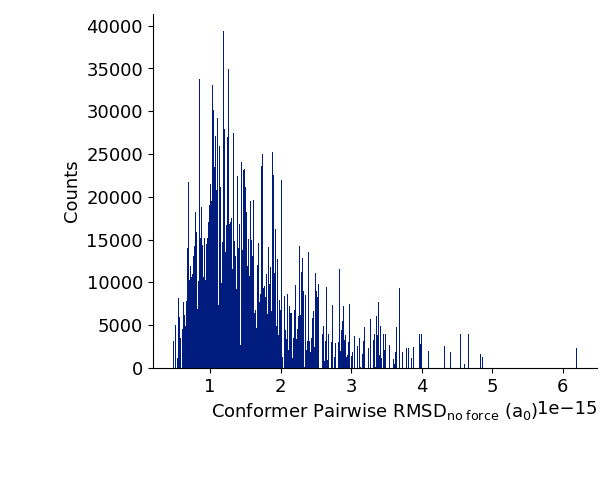

In [532]:
plt.HistogramPlot(pair_rmsds_no_force, bins=500, image_size=[440, 350],
                 axes_labels=[
                     r"Conformer Pairwise RMSD$_\text{no force}$ (a$_0$)",
                     "Counts"
                 ]
                 )#.savefig("figs/ridig_pairwise_rmsds.png", dpi=288)


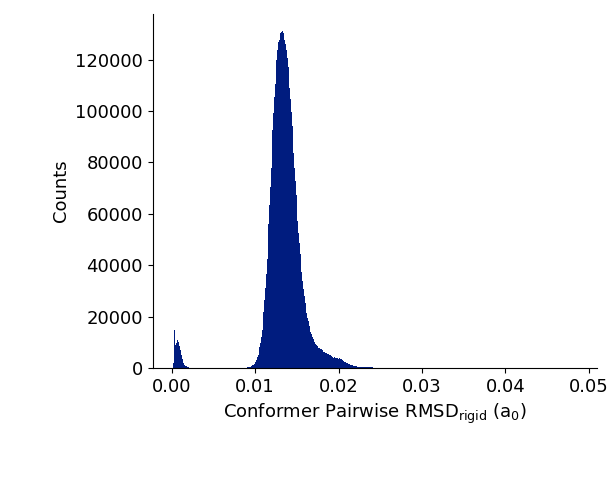

In [523]:
plt.HistogramPlot(pair_rmsds_rig, bins=500, image_size=[440, 350],
                 axes_labels=[
                     r"Conformer Pairwise RMSD$_\text{rigid}$ (a$_0$)",
                     "Counts"
                 ]
                 )#.savefig("figs/ridig_pairwise_rmsds.png", dpi=288)


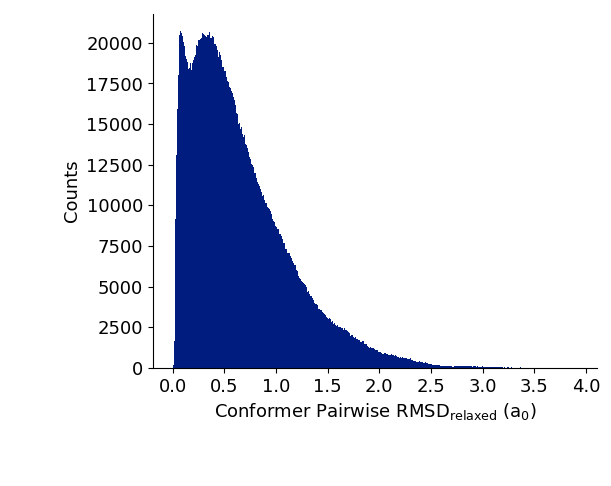

In [526]:
plt.HistogramPlot(pair_rmsds, bins=500, image_size=[440, 350],
                 axes_labels=[
                     r"Conformer Pairwise RMSD$_\text{relaxed}$ (a$_0$)",
                     "Counts"
                 ]
                 )#.savefig("figs/relaxed_pairwise_rmsds.png", dpi=288)

### Stereo

#### Stereoflip Figure

In [ ]:
rda = importlib.reload(rda)


In [419]:
d2_groups_uin = rda.get_dienophile_groups(d2_uin)


In [ ]:
# d2_groups_uin[2][('', 'CC(C)(C)C CC(C)(C)C')].merge_datasets(
#     d2_groups_uin[2][('CC(C)(C)C', 'CC(C)(C)C')]
# )

In [ ]:
# rda.merge_stereo_datasets([
#     d2_groups_uin[2][('', 'CC(C)(C)C CC(C)(C)C')],
#     d2_groups_uin[2][('CC(C)(C)C', 'CC(C)(C)C')]
# ]).plot()

In [6]:
d2_groups = rda.get_dienophile_groups(d2_reg)
# d2_groups_int = rda.get_dienophile_groups(d2_int)
# d2_groups_rand = rda.get_dienophile_groups(d2_rand)
# d2_groups = rda.get_dienophile_groups(d2_uin)

In [7]:
pairs = [k for k in d2_groups[1] if ' ' in k]
subwoof = d2_groups[1][pairs[5]]

In [8]:
sd = sum(
    (rda.get_real_sterodata(d2_groups[1], p, return_data=True) for p in pairs),
    []
)

In [12]:
rda = importlib.reload(rda)
figure = rda.plot_stereo_barrier_data(sd, 'Min Energy Force', 'Min Energy Solvo',
                                      label='Min. Conf',
                                      plot_legend=True,
                                      marker='s',
                                      maskmarker='D',
                                      solvo_exclude=0,
                                      mech_exclude=0,
                                      base_color=plt.prep_color(palette='pastel', index=1,
                                                                saturate=1,
                                                                lighten=.45,
                                                                alpha=.5,
                                                                modification_space='hsl'),
                                      
                                      panel_color=plt.prep_color('gray', index=1,
                                                                saturate=1,
                                                                lighten=.95,
                                                                alpha=.5,
                                                                modification_space='hsl'),
                                      padding=[[50, 0], [50, 20]],
                                      image_size=[350, 350],
                                      mask_excludes=[.2, .2],
                                      plot_range=[[-5.5, 5.5], [-5.5, 5.5]],
                                      legend_style={
                                          'frameon': False,
                                          # 'loc': 'lower right',
                                          # 'bbox_to_anchor':[1.04, -.04],
                                          'ncol': 2,
                                          'loc': 'upper left',
                                          'columnspacing': .1,
                                          'bbox_to_anchor': [-.03, 1.09],
                                          'fontsize': 12
                                      }
                                      )
rda.plot_stereo_barrier_data(sd, 'Min Barrier Force', 'Min Barrier Solvo',
                             figure=figure,
                             plot_range=[[-5.5, 5.5], [-5.5, 5.5]],
                             draw_panels=False,
                             mask_excludes=[.2, .2],
                                      maskmarker='p',
                             label='Min. Barrier',
                             padding=[[50, 0], [50, 20]],
                             image_size=[350, 350]
                             )
# plt.ScatterPlot(
#     [1.41251072],
#     [-0.48305043],
#     color='orange',
#     figure=figure
# )

figure#.savefig('figs/stereo_comps_3.svg')

In [241]:
uuh = sum(
    (rda.get_real_sterodata(d2_groups[1], p, return_data=True) for p in pairs[:3]),
    []
)

In [40]:
pairs[13]

'O=[SH](=O)c1ccccc1 Fc1ccccc1'

In [41]:
eeey = rda.prep_stereo_subgroups(d2_groups[1], pairs[13])

#### Main Figure

In [5]:
d2_int_groups = rda.get_dienophile_groups(d2_int)

In [187]:
wah = np.intersect1d(
    np.unique([
        d.rsplit('/', 1)[0]
            for d in d2_int_groups[0].d_path
    ]),
    np.unique([
        d.rsplit('/', 1)[0]
            for d in d2_groups[0].d_path
    ])
)

In [230]:
source = wah[1]#'PSUFIFFBZBVCLE-FUICEZJUSA-N/15'

filt0_int = d2_int_groups[0][
    lambda d:d['d_path'] == source + '/pipeline_data_internals',
    # lambda d:(d['force_magnitudes'] > 0) & (d['force_magnitudes'] < 60),
    lambda d:(d['force_magnitudes'] > 0) & (d['force_magnitudes'] > 190),
    # lambda d:d['direction_ids'] == 0
    ][1]
mol = filt0_int.reactant
def chop(fv):
    fv = fv.reshape((-1, 3))
    fv[mol.fragment_indices[0]] *= 0
    return fv
# filt0_int.plot_fmrd_vector(0, image_size=800,
#                        include_save_buttons=True,
#                        processor=chop,
#                        view_settings={
#                         'view_vector':rda.get_pointing_vector(mol),
#                         'right_vector':(mol.coords[1] - mol.coords[0]),
#                         'view_distance':20,
#                         # 'view_center':[0, 2, 0]
#                     }
#                       )

filt0_rand = d2_rand_groups[0][
    lambda d:d['d_path'] == source + '/pipeline_data_random',
    # lambda d:(d['force_magnitudes'] > 0) & (d['force_magnitudes'] < 60),
    lambda d:(d['force_magnitudes'] > 0) & (d['force_magnitudes'] > 190),
    # lambda d:d['direction_ids'] == 0
    ][1]
mol = filt0_rand.reactant
# def chop(fv):
#     fv = fv.reshape((-1, 3))
#     fv[mol.fragment_indices[0]] *= 0
#     return fv
# filt0_rand.plot_fmrd_vector(0, image_size=800,
#                        include_save_buttons=True,
#                        # processor=chop,
#                        view_settings={
#                         'view_vector':rda.get_pointing_vector(mol),
#                         'right_vector':(mol.coords[1] - mol.coords[0]),
#                         'view_distance':20,
#                         # 'view_center':[0, 2, 0]
#                     }
#                       )

filt0 = d2_groups[0][
    lambda d:d['d_path'] == source+'/pipeline_data',
    # lambda d:(d['force_magnitudes'] > 0) & (d['force_magnitudes'] < 60),
    lambda d:(d['force_magnitudes'] < -190),
    # lambda d:d['direction_ids'] == 0
    ][1]
mol = filt0.reactant
# filt0.plot_fmrd_vector(0, image_size=800, include_save_buttons=True,
#                        view_settings={
#                         'view_vector':rda.get_pointing_vector(mol),
#                         'right_vector':(mol.coords[1] - mol.coords[0]),
#                         'view_distance':20,
#                         # 'view_center':[0, 2, 0]
#                     }
#                       )

f0 = filt0.plot_profile(
                        color='black', 
                        fmrd_index=None,
                        force_modified=False,
                        mark_critical_points=False,
                         image_size=[440 * .8, 250 * .8],
                         padding=[[20, 0], [25, 0]],
                         ticks=[[], []],
                         axes_labels=[r"$\Delta r_\text{avg.}$", "Energy"], 
                        # labels=['No Force', 'Optimized'],
                        plot_legend=True
                       )
# f0 = filt0.plot_profile(bar_color=['gray', rda.COLOR_PALETTE[0]], 
#                         color='black', 
#                          image_size=[440 * .8, 250 * .8],
#                          padding=[[20, 0], [25, 0]],
#                          ticks=[[], []],
#                          axes_labels=[r"$\Delta r_\text{avg.}$", "Energy"], 
#                         # labels=['No Force', 'Optimized'],
#                         plot_legend=True
#                        )
filt0.plot_fmrd_lines(0, figure=f0, bar_color='gray',
                      force_modified=False,
                         primary_label='No Force',
                      legend_style={'frameon':False, 'fontsize':12,
                                   'loc':'upper left',
                                    'bbox_to_anchor':[-.01, 1.05]
                                   }
                         )
filt0.plot_fmrd_lines(0, figure=f0, bar_color=rda.COLOR_PALETTE[0],
                         primary_label='Optimized'
                         )
filt0_int.plot_fmrd_lines(0, figure=f0, bar_color=rda.COLOR_PALETTE[2],
                         primary_label='Dihedrals'
                         )
filt0_rand.plot_fmrd_lines(0, figure=f0, bar_color=rda.COLOR_PALETTE[1],
                         primary_label='Random')
f0.savefig('figs/distortion_example_curve.svg')

In [34]:
d2_rand_groups = rda.get_dienophile_groups(d2_rand)

In [109]:
d2_groups = rda.get_dienophile_groups(d2_reg)

In [152]:
def get_stereoconfs(ds):
    # dd = ds.add_aggregation_fields(
    #     lambda d: {
    #         'int_mag': int(round(
    #             d.fmrds[0].force_magnitude * UnitsData.convert(
    #                 ("Hartrees", "InverseBohrRadius"),
    #                 ("PicoJoules", "InverseMeters")
    #             )
    #         ))
    #     },
    #     # input='fields',
    #     pool=None
    # )
    # d3 = dd.group_by_props(('int_mag', 'direction_ids'))
    cc = ds.group_by_props('d_path')
    cds = [dd[0] for dd in cc.values()]
    mols = [dd[0].reactant for dd in cc.values()]
    mols[0] = mols[0].get_embedded_molecule(sel=[0, 1, 2, 3, 4, 5])
    mols[1:] = [
        m.get_embedded_molecule(ref=mols[0], sel=[0, 1, 2, 3, 4, 5])
        for m in mols[1:]
        ]
    return cc, cds, mols

In [228]:
key_map, optos, cc = get_stereoconfs(eeey['2@1/3@1'])

In [230]:
fig = None
for n,o in enumerate(optos):
    if n == 5: continue
    fig = o.plot_profile(force_modified=False, 
                         image_size=[440 * .8, 250 * .8],
                         padding=[[20, 0], [25, 0]],
                         ticks=[[], []],
                         axes_labels=[r"$\Delta r_\text{avg.}$", "Energy"],
                         figure=fig, mark_critical_points=False)
fig.savefig('figs/exo_reaction_profiles_big.svg')

In [ ]:
f0 = cc[0].plot(backend='x3d', image_size=800, background='white',
               include_save_buttons=True,
                view_settings={
                    'view_vector':rda.get_pointing_vector(cc[0]),
                    'right_vector':-(cc[0].coords[1] - cc[0].coords[0]),
                    'view_distance':20,
                    'view_center':[0, 2, 0]
                }
               )
stack = [(list(key_map)[0], cc[0])]
for k,m in zip(list(key_map)[1:], cc[1:]):
    if any(
        m.get_rmsd(mm, 
                   sel=[i for i,a in enumerate(m.atoms) if a != "H"]
                  ) < .1
        for _,mm in stack
    ): continue
    stack.append([k, m])
    m.plot(backend='x3d', figure=f0, 
           transparency=.7,
           atom_style={'glow':'#301015'})
f0

In [436]:
aaa = eeey['2@1/2@-1'].add_aggregation_fields(
    int_mag=lambda d:int(round(d['force_magnitudes']))
)
                                        

In [433]:
hmm = eeey['2@1/2@-1'].group_by_props(('force_magnitudes', 'direction_ids'))

In [ ]:
np.argmin(eeey['2@1/3@-1'].barriers + eeey['2@1/3@-1'].deltas)

In [247]:
np.argmin(eeey['2@1/3@-1'].barriers + eeey['2@1/3@-1'].deltas)

np.int64(116)

In [252]:
?rda.animate_rx

Signature: rda.animate_rx(opt, fmrd=0, **etc)
Docstring: <no docstring>
File:      ~/Documents/Postdoc/Development/cmcc-reactions/cmcc_reactions/reaction_data_analysis.py
Type:      function

In [ ]:
eeey['2@1/3@-1'][116].reactant.plot(display_atom_numbers=True)

In [ ]:
rda.animate_rx(eeey['2@1/3@-1'][116], embedding_indices=[2, 3, 7, 8, 9])

In [ ]:
opt = eeey['2@1/3@-1'][116]
rrr = opt.reactant
fmrd = opt.fmrds[0]
coords = [
    rrr.coords,
    fmrd.force_modified_reactant_geom
]
coords = rrr.embed_coords(coords, sel=[0, 1, 2, 3, 4])
fv = coords[1] - coords[0]
v0 = nput.vec_normalize(fv).reshape(-1, 3)
rrr.plot(
    mode_vectors=np.clip(v0.flatten() * 2, -3, 3),
    mode_vector_display_cutoff=.8,
    image_size=1000,
    view_settings={
        'up_vector':-rrr.fragments[0].take_submolecule([0, 1, 2, 3, 4]).inertial_axes[:, 2],
        'right_vector':-(
            np.average(rrr.coords[(0, 1), :], axis=0) 
            - np.average(rrr.coords[(4, 5), :], axis=0)
        ),
        'view_distance':15
        # 'viewAll':True
    },
    include_save_buttons=True,
    background='transparent',
    # display_atom_numbers=True,
    label_style={'font_style':{'size':15}}
)

#### Old

In [11]:
def merge_datasets(ds_vals):
    d = ds_vals[0]
    for d2 in ds_vals[1:]:
        d = d.merge_datasets(d2)
    return d

In [16]:
def get_stereopos(smi):
    return tuple(
        (int(k.split(":")[1][:-1]), '+' if '@@' in k else '-')
        for k in re.findall(r"\[C@+H:\d+\]", smi)
    )
def get_stereopairs(smi_list):
    bits = {s:get_stereopos(s) for s in smi_list}
    pairs = []
    item_list = list(bits.items())
    for n,(s,b) in enumerate(item_list):
        if len(b) < 2: continue
        for s2,b2 in item_list[n+1:]:
            if len(b2) < 2: continue
            if all(i == j and k != l for (i,k),(j,l) in zip(b, b2)):
                pairs.append([(s, s2), (b, b2)])
    return pairs

In [27]:
# just for cyclopd
def get_pointing_vector(mol):
    if isinstance(mol, np.ndarray):
        coords = mol
    elif isinstance(mol, tuple):
        coords = mol.product_geometry
    else:
        coords = mol.coords
    return nput.vec_normalize((coords[1] + coords[0]) - (coords[4] + coords[5]))
def get_stereo_orientation(mol):
    if isinstance(mol, tuple):
        coords = mol.product_geometry
    else:
        coords = mol.coords
    pv = get_pointing_vector(coords)
    i_conn = None
    j_conn = None
    for b in mol.bonds:
        i,j = sorted(b[:2])
        if i in (2, 3):
            if j == 7:
                i_conn = int(i)
            elif j == 8:
                j_conn = int(i)
    iv = coords[7] - coords[i_conn]
    jv = coords[8] - coords[j_conn]
    return (i_conn, int(np.sign(np.dot(pv, iv)))), (j_conn, int(np.sign(np.dot(pv, jv))))

In [32]:
def get_stereoswap_table(d2_groups, main_pair, pair_data, return_data=False):
    l,r = main_pair.split(' ', 1)
    subwoof = d2_groups[main_pair]
    (s, s2), (b, b2) = pair_data
    # print(b, b2, s, s2)
    l = f"{l}({b[0][1]})"
    r = f"{r}({b2[0][1]})"
    if return_data:
        return rda.get_dataset_sterodata(subwoof[s], subwoof[s2])
    else:
        return rda.plot_dataset_stereocomp(subwoof[s], subwoof[s2], l, r)
def get_stereoswap_tables(d2_groups, main_pair, sep="\n\n", return_data=False):
    dl = [
        get_stereoswap_table(d2_groups, main_pair, pd, return_data=return_data)
            for pd in get_stereopairs(d2_groups[main_pair].keys())
    ]
    if return_data:
        return dl
    else:
        return sep.join(dl)
def get_stereoswap_datasets(d2_groups, main_pair, sep="\n\n", return_data=False):
    subwoof = d2_groups[main_pair]
    return [
        (
            [subwoof[pd[0][0]], subwoof[pd[0][1]]],
            pd
        )
        for pd in get_stereopairs(d2_groups[main_pair].keys())
    ]

In [307]:
def prep_subgroups(d2_groups, main_pair):
    subwoof = d2_groups[main_pair]
    submerge = merge_datasets(list(subwoof.values()))
    orients = [
        get_stereo_orientation(submerge.get_tree_data(i))
        for i in range(len(submerge))
    ]
    ds = submerge.add_aggregation_fields(
        orientations=orients,
        o_keys=[f"{i}@{r}/{j}@{s}" for (i,r), (j,s) in orients]
    )
    return ds.group_by_props('o_keys')
def get_real_sterodata(d2_groups, main_pair, return_data=False):
    subgroups = prep_subgroups(d2_groups, main_pair)
    l,r = main_pair.split(' ', 1)

    bits = []
    for ((s, b1), (s2, b2)) in [
        [('2@-1/2@1', '2(+)'), ('2@1/2@-1', '2(-)')],
        [('2@1/3@1', '2(+)'), ('2@-1/3@-1', '3(+)')],
        [('2@1/3@-1', '2(+)'), ('2@-1/3@1', '3(-)')],
        
    ]:
        if s not in subgroups or s2 not in subgroups: continue
        x = f"{l} | {b1}"
        y = f"{r} | {b2}"
        if return_data:
            bits.append(rda.get_dataset_sterodata(subgroups[s], subgroups[s2]))
        else:
            bits.append(rda.plot_dataset_stereocomp(subgroups[s], subgroups[s2], x, y))

    return bits

In [76]:
print(
    "\n".join(get_real_sterodata(d2_groups[1], pairs[13]))
)

O=[SH](=O)c1ccccc1 | 2(+)    Endo      Exo      Delta  
    Fc1ccccc1 | 2(-)       kcal/mol  kcal/mol  kcal/mol
-------------------------------------------------------
       Min Barrier Solvo:    25.1      27.8        -2.7
       Min Barrier Force:    16.6      20.4        -3.8
        Min Energy Solvo:    25.1      31.0        -5.9
        Min Energy Force:    23.9      30.0        -6.1
      Min Energy/Barrier:    16.6      24.3        -7.7
O=[SH](=O)c1ccccc1 | 2(+)    Endo      Exo      Delta  
    Fc1ccccc1 | 3(+)       kcal/mol  kcal/mol  kcal/mol
-------------------------------------------------------
       Min Barrier Solvo:    25.5      23.5         2.0
       Min Barrier Force:    17.9      13.6         4.2
        Min Energy Solvo:    25.5      25.2         0.3
        Min Energy Force:    24.9      25.4        -0.5
      Min Energy/Barrier:    22.6      20.7         1.8
O=[SH](=O)c1ccccc1 | 2(+)    Endo      Exo      Delta  
    Fc1ccccc1 | 3(-)       kcal/mol  kcal/mol  k

In [29]:
subgroups = ds.group_by_props('o_keys')

In [30]:
subgroups.keys()

dict_keys(['2@-1/2@1', '2@-1/3@-1', '2@-1/3@1', '2@1/2@-1', '2@1/3@-1', '2@1/3@1'])

In [24]:
# sd = sum(
#     (get_stereoswap_tables(d2_groups[1], p, return_data=True) for p in pairs),
#     []
# )

In [334]:
for p in pairs:
    print(
        "\n".join(get_real_sterodata(d2_groups[1], p))
    )

 CC(C)(C)C | 2(+)      Endo      Exo      Delta  
 CC(C)(C)C | 3(-)    kcal/mol  kcal/mol  kcal/mol
-------------------------------------------------
 Min Barrier Solvo:    29.8      29.8         0.1
 Min Barrier Force:    21.3      21.4        -0.1
  Min Energy Solvo:    29.9      29.8         0.1
  Min Energy Force:    29.4      30.0        -0.6
Min Energy/Barrier:    21.6      23.0        -1.4
     CN | 2(+)         Endo      Exo      Delta  
 CC(C)(C)C | 2(-)    kcal/mol  kcal/mol  kcal/mol
-------------------------------------------------
 Min Barrier Solvo:    29.5      30.8        -1.3
 Min Barrier Force:    20.6      24.4        -3.8
  Min Energy Solvo:    30.3      32.4        -2.1
  Min Energy Force:    30.5      32.5        -2.1
Min Energy/Barrier:    20.6      24.4        -3.8
     CN | 2(+)         Endo      Exo      Delta  
 CC(C)(C)C | 3(+)    kcal/mol  kcal/mol  kcal/mol
-------------------------------------------------
 Min Barrier Solvo:    26.2      26.5        -0.3


In [79]:
sd = sum(
    (get_real_sterodata(d2_groups[1], p, return_data=True) for p in pairs),
    []
)

In [301]:
"""
        CN | 2(+)            Endo      Exo      Delta  
O=[SH](=O)c1ccccc1"


SyntaxError: incomplete input (37916176.py, line 1)

In [309]:
subgroups = prep_subgroups(d2_groups[1], 'CN O=[SH](=O)c1ccccc1')

In [316]:
np.argmin(
    subgroups['2@1/2@-1'].reactant_energies
)

np.int64(0)

In [ ]:
rda.animate_rx(
    subgroups['2@1/2@-1'][47]
)

In [ ]:
rda.animate_rx(
    subgroups['2@1/2@-1'][0]
)

In [317]:
np.argmin(
    subgroups['2@1/2@-1'].delta_r + subgroups['2@1/2@-1'].reactant_energies
)

np.int64(47)

In [320]:
np.argmin(
    subgroups['2@-1/2@1'].reactant_energies
)

np.int64(453)

In [ ]:
subgroups['2@-1/2@1'].barriers

In [ ]:
rda.animate_rx(
    subgroups['2@-1/2@1'][453]
)

In [327]:
np.argmin(
    subgroups['2@-1/2@1'].delta_r + subgroups['2@-1/2@1'].reactant_energies
)

np.int64(639)

In [ ]:
np.argmin(subgroups['2@-1/2@1'].reactant_energies

In [ ]:
opt = subgroups['2@1/2@-1'][47]
rrr = opt.reactant
fmrd = opt.fmrds[0]
coords = [
    opt.reactant.coords,
    fmrd.force_modified_reactant_geom
]
coords = opt.reactant.embed_coords(coords, sel=[0, 1, 2, 3, 4])
fv = coords[1] - coords[0]
v0 = nput.vec_normalize(fv).reshape(-1, 3)
rrr.plot(
    mode_vectors=np.clip(v0.flatten() * 2, -3, 3),
    mode_vector_display_cutoff=.8,
    image_size=1000,
    view_settings={
        'up_vector':-rrr.fragments[0].take_submolecule([0, 1, 2, 3, 4]).inertial_axes[:, 2],
        'view_vector':(
            np.average(rrr.coords[(0, 1), :], axis=0) 
            - np.average(rrr.coords[(4, 5), :], axis=0)
        ),
        'view_distance':15
        # 'viewAll':True
    },
    include_save_buttons=True,
    background='transparent',
    # display_atom_numbers=True,
    label_style={'font_style':{'size':15}}
)

In [ ]:
rda.animate_rx(subgroups['2@1/2@-1'][47])

In [326]:
figure = plot_stero_barrier_data(sd, 'Min Energy Force', 'Min Energy Solvo',
                                 label='Min. Conf',
                                 plot_legend=True,
                                 marker='s',
                                 legend_style={'frameon':False, 'loc':'lower right', 'fontsize':13}
                                 )
plot_stero_barrier_data(sd, 'Min Barrier Force', 'Min Barrier Solvo', figure=figure,
                        draw_panels=False,
                        label='Min. Barrier',
                        )
figure#.savefig('figs/stereo_comps.svg')

In [273]:
# plot_stero_barrier_data(sd, 'Min Barrier Force').savefig('figs/stereo_min_barrier.svg')

In [275]:
# plot_stero_barrier_data(sd, 'Min Energy/Barrier').savefig('figs/stereo_min_energy.svg')


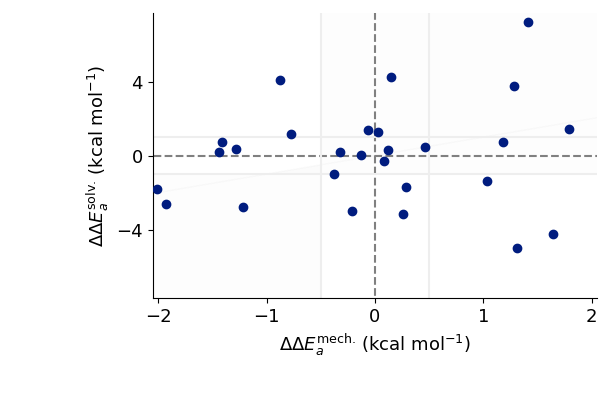

In [81]:
diffl = lambda x:x[1] - x[0]
figure = plt.ScatterPlot(
    [diffl(d['Min Barrier Solvo']) for d in sd],
    # [diffl(d['Min Barrier Force']) for d in sd],
    [diffl(d['Min Energy/Barrier']) for d in sd],
    plot_range=[[-2.05, 2.05], [-7.7, 7.7]],
    # color='white',
    ticks=[[-2, -1, 0, 1, 2], [-4, 0, 4]],
    zorder=1000,
    image_size=[440, 300],
    axes_labels=[r'$\Delta \Delta E_a^{\text{mech.}}$ (kcal mol$^{-1}$)',
                 r'$\Delta \Delta E_a^{\text{solv.}}$ (kcal mol$^{-1}$)'
                ]
)
plt.Plot(
    [0, 0],
    [-10, 10],
    figure=figure,
    color='gray',
    linestyle='dashed'
)
plt.Plot(
    [-10, 10],
    [0, 0],
    figure=figure,
    color='gray',
    linestyle='dashed'
)

# plt.FilledPlot._get_plot_data = _get_plot_data
plt.FilledPlot(
    [-10, 10],
    [-1, -1],
    [1, 1],
    figure=figure,
    color=plt.prep_color('#AAAAAA', alpha=.025)
)
plt.Plot(
    [-10, 10],
    [-1, -1],
    figure=figure,
    color='#eee',
    # linestyle='dashed'
)
plt.Plot(
    [-10, 10],
    [1, 1],
    figure=figure,
    color='#eee',
    # linestyle='dashed'
)
# plt.HorizontalFilledPlot._get_plot_data = _get_plot_data
plt.HorizontalFilledPlot(
    [-10, 10],
    [-.5, -.5],
    [.5, .5],
    figure=figure,
    color=plt.prep_color('#AAAAAA', alpha=.025)
)
plt.Plot(
    [-.5, -.5],
    [-10, 10],
    figure=figure,
    color='#eee',
    # linestyle='dashed'
)
plt.Plot(
    [.5, .5],
    [-10, 10],
    figure=figure,
    color='#eee',
    # linestyle='dashed'
)
# figure.savefig('figs/stereodiffs.svg')
figure

In [655]:
stereodatasets_sub = get_stereoswap_datasets(d2_groups[1], 'O=[SH](=O)c1ccccc1 Fc1ccccc1')

In [666]:
ddd = [
    _ for _, k in stereodatasets_sub
    if k[1][0][0][1] == '+' and k[1][0][1][1] == '-'
][0]

In [671]:
np.argmin(ddd[0].barriers + ddd[0].deltas)

166

In [676]:
opt = ddd[0][166]

In [687]:
fmrd = opt.fmrds[0]
coords = [
    opt.reactant.coords,
    fmrd.force_modified_reactant_geom
]
coords = opt.reactant.embed_coords(coords, sel=[0, 1, 2, 3, 4])

In [ ]:
rda.animate_rx(opt)

In [ ]:
opt = ddd[0][166]
rrr = opt.reactant
fv = coords[1] - coords[0]
v0 = nput.vec_normalize(fv).reshape(-1, 3)
rrr.plot(
    mode_vectors=np.clip(v0.flatten() * 2, -3, 3),
    mode_vector_display_cutoff=.8,
    image_size=1000,
    view_settings={
        'up_vector':-rrr.fragments[0].take_submolecule([0, 1, 2, 3, 4]).inertial_axes[:, 2],
        'right_vector':-(
            np.average(rrr.coords[(0, 1), :], axis=0) 
            - np.average(rrr.coords[(4, 5), :], axis=0)
        ),
        'view_distance':15
        # 'viewAll':True
    },
    include_save_buttons=True,
    background='transparent',
    # display_atom_numbers=True,
    label_style={'font_style':{'size':15}}
)

In [662]:
len(ddd)

1

In [644]:
d2_groups[1]['O=[SH](=O)c1ccccc1 Fc1ccccc1'].keys()

dict_keys(['O=[S:8](=O)(c1ccccc1)[C@:3]1([c:9]2ccc(F)cc2)[CH:1]2[CH:5]=[CH:6][CH:2]([CH2:4]1)[CH2:7]2', 'O=[S:8](=O)(c1ccccc1)[C@@:3]1([c:9]2ccc(F)cc2)[CH:1]2[CH:5]=[CH:6][CH:2]([CH2:4]1)[CH2:7]2', 'O=[S:8](=O)(c1ccccc1)[C@@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@@H:4]1[c:9]1ccc(F)cc1)[CH2:7]2', 'O=[S:8](=O)(c1ccccc1)[C@@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@H:4]1[c:9]1ccc(F)cc1)[CH2:7]2', 'O=[S:8](=O)(c1ccccc1)[C@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@@H:4]1[c:9]1ccc(F)cc1)[CH2:7]2', 'O=[S:8](=O)(c1ccccc1)[C@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@H:4]1[c:9]1ccc(F)cc1)[CH2:7]2'])

In [ ]:
'O=[SH](=O)c1ccccc1(+)    Endo      Exo      Delta  
    Fc1ccccc1(-)'

In [555]:
print(
    ("\n" + "#"*50 + "\n" + "="* 50 + "\n" + "#"*50 + "\n").join(
        get_stereoswap_tables(d2_groups[1], p)
        for p in pairs
    )
)

   CC(C)(C)C(+)        Endo      Exo      Delta  
   CC(C)(C)C(-)      kcal/mol  kcal/mol  kcal/mol
-------------------------------------------------
 Min Barrier Solvo:    29.8      29.8        -0.0
 Min Barrier Force:    21.3      21.4        -0.1
  Min Energy Solvo:    29.8      29.8        -0.0
  Min Energy Force:    30.0      29.4         0.6
Min Energy/Barrier:    23.4      23.0         0.4
##################################################
##################################################
       CN(+)           Endo      Exo      Delta  
   CC(C)(C)C(-)      kcal/mol  kcal/mol  kcal/mol
-------------------------------------------------
 Min Barrier Solvo:    26.2      26.2         0.0
 Min Barrier Force:    19.2      20.4        -1.2
  Min Energy Solvo:    28.4      28.5        -0.1
  Min Energy Force:    27.7      28.3        -0.6
Min Energy/Barrier:    23.5      22.7         0.9

       CN(+)           Endo      Exo      Delta  
   CC(C)(C)C(-)      kcal/mol  kcal/mol  kcal/m

In [ ]:
get_dataset_sterodata

In [548]:
print(
    ("\n" + "#"*50 + "\n" + "="* 50 + "\n" + "#"*50 + "\n").join(
        get_stereoswap_tables(d2_groups[1], p)
        for p in pairs
    )
)

   CC(C)(C)C(+)        Endo      Exo      Delta  
   CC(C)(C)C(-)      kcal/mol  kcal/mol  kcal/mol
-------------------------------------------------
 Min Barrier Solvo:    29.8      29.8        -0.0
 Min Barrier Force:    21.3      21.4        -0.1
  Min Energy Solvo:    29.8      29.8        -0.0
  Min Energy Force:    30.0      29.4         0.6
Min Energy/Barrier:    23.4      23.0         0.4
##################################################
##################################################
       CN(+)           Endo      Exo      Delta  
   CC(C)(C)C(-)      kcal/mol  kcal/mol  kcal/mol
-------------------------------------------------
 Min Barrier Solvo:    26.2      26.2         0.0
 Min Barrier Force:    19.2      20.4        -1.2
  Min Energy Solvo:    28.4      28.5        -0.1
  Min Energy Force:    27.7      28.3        -0.6
Min Energy/Barrier:    23.5      22.7         0.9

       CN(+)           Endo      Exo      Delta  
   CC(C)(C)C(-)      kcal/mol  kcal/mol  kcal/m

### Pressure

In [74]:
import csv

sheets = {}
with open(f'pressure/smi_sheet.csv') as press_100:
    smis = [line[2] for line in itertools.islice(csv.reader(press_100), 1, None)]
for mag in [100, 200, 500, 1000]:
    with open(f'pressure/0728_hydro_compare_organized_{mag}.csv') as press_100:
        sheets[mag] = np.array([
            [float(x) if x != '' else np.nan for x in line]
                for line in itertools.islice(csv.reader(press_100), 1, None)
        ])

# smis_2 = []
# sheets2 = {}
# skip_cols = [1]
# for mag in [100, 200, 500, 1000]:
#     with open(f'pressure/pressue_sorted_master_newdataset_corr_0814_{mag}.csv') as press_100:
#         lines = []
#         for line in itertools.islice(csv.reader(press_100), 1, None):
#             lines.append([float(x) if x != '' else np.nan for j,x in enumerate(line) if j not in skip_cols])
#         smis_2.append(line[1])
#         sheets2[mag] = np.array(lines)


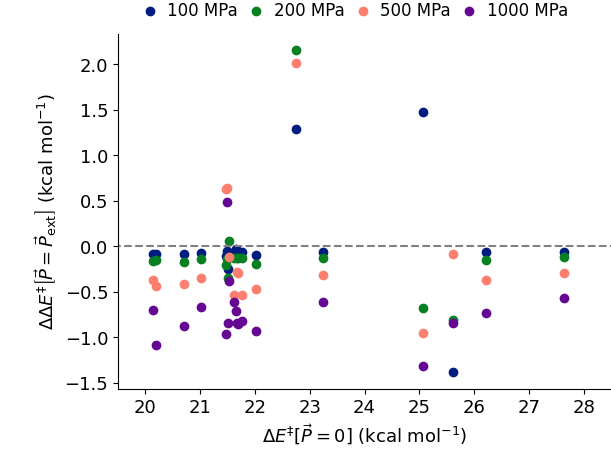

In [75]:
ds_data = {}
for mag in [100, 200, 500, 1000]:
    nf = np.concatenate([
        sheets[mag][:, (2, 3)],
        # sheets2[mag][:, (2, 3)]
    ], axis=0)
    gf = np.concatenate([
        sheets[mag][:, (10, 12)],
        # sheets2[mag][:, (10, 12)]
    ], axis=0)
    bf = rda.eh2kcal * (
        (gf[:, 1] - gf[:, 0])
    )
    b0 = rda.eh2kcal * (
        (nf[:, 1] - nf[:, 0])
    )
    db =  bf - b0
    mask=~np.isnan(db)
    mask=mask & (np.abs(db) < 15)
    mask=mask & (b0 > 10)
    ds_data[mag] = (b0[mask], db[mask], bf[mask], mask, db, nf, gf)

figure = None
for i,(mag, ds) in enumerate(ds_data.items()):
    figure = plt.ScatterPlot(ds[0], ds[1],
                             label=f"{mag} MPa",
                             plot_legend=True,
                             legend_style={
                                 'frameon':False, 
                                 'fontsize':12,
                                 'ncol':4,
                                 'handletextpad':.05,
                                 'columnspacing':.1,
                                 'loc':'lower left',
                                 'bbox_to_anchor':[0, 1]
                             },
                             style_list={'color':rda.COLOR_PALETTE},
                             image_size=[440, 330],
                             padding=[[85, 0], [50, 25]],
                             plot_range=[[19.5, 28.5], None],
                             axes_labels=[
                                 r"$\Delta E^{\ddagger} \left[\vec{P}=0\right]$ (kcal mol$^{-1}$)", 
                                 r"$\Delta \Delta E^{\ddagger} \left[\vec{P}=\vec{P}_\text{ext}\right]$ (kcal mol$^{-1}$)"
                             ],
                             figure=figure)
plt.Plot([19, 29], [0, 0], figure=figure, color='gray', linestyle='dashed')
# figure.savefig('pressure_barrier_changes.svg')
figure

In [ ]:
ds_data2 = {}
for mag in [100, 200, 500, 1000]:
    nf = np.concatenate([
        # sheets[mag][:, (2, 3)],
        sheets2[mag][:, (2, 3)]
    ], axis=0)
    gf = np.concatenate([
        # sheets[mag][:, (10, 12)],
        sheets2[mag][:, (10, 12)]
    ], axis=0)
    bf = rda.eh2kcal * (
        (gf[:, 1] - gf[:, 0])
    )
    b0 = rda.eh2kcal * (
        (nf[:, 1] - nf[:, 0])
    )
    db =  bf - b0
    mask=~np.isnan(db)
    # mask=mask & (np.abs(db) < 15)
    # mask=mask & (b0 > 10)
    ds_data2[mag] = (b0[mask], db[mask], bf[mask], mask, db, nf, gf)

figure = None
for i,(mag, ds) in enumerate(ds_data2.items()):
    figure = plt.ScatterPlot(ds[0], ds[1],
                             label=f"{mag} MPa",
                             plot_legend=True,
                             legend_style={'frameon':False, 'fontsize':12},
                             image_size=[440, 330],
                             axes_labels=[
                                 r"$\Delta E^{\ddagger} \left[\vec{P}=0\right]$ (kcal mol$^{-1}$)", 
                                 r"$\Delta \Delta E^{\ddagger} \left[\vec{P}=\vec{P}_\text{ext}\right]$ (kcal mol$^{-1}$)"
                             ],
                             figure=figure)
# figure.savefig('pressure_barrier_changes.svg')
figure

In [244]:
import pandas

pressure_sheets = {
    k:pandas.read_excel('pressure/sorted_master_newdataset_rm_0910.xlsx', sheet_name=f'{k}mpa')
    for k in [100, 200, 500, 1000]
}

In [72]:
distortion_sheet = pandas.read_excel('pressure/sorted_master_newdataset_rm_0910.xlsx', sheet_name=f'SP_step0_stepN')


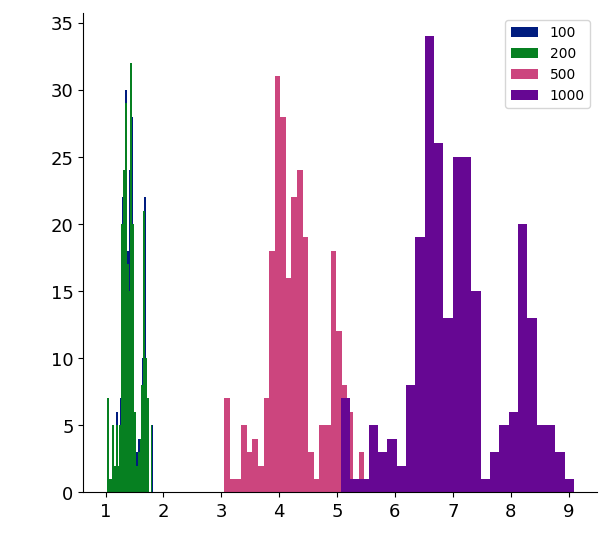

In [73]:
f0 = None
for start, end in [
        ('nf_last', '100_0'),
        ('100_last', '200_0'),
        ('200_last', '500_0'),
        ('500_last', '1000_0')
]:
    f0 = plt.HistogramPlot(
        (distortion_sheet[end] - distortion_sheet[start]).to_numpy() * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
        bins=25,
        figure=f0,
        label=end[:-2],
        plot_legend=True
    )
f0

In [76]:
old_barriers = pressure_sheets[100]['nf_Ea(kcal/mol)'].to_numpy()

In [94]:
new_barriers = np.cumsum(distortion_sheet.to_numpy()[:, (-2, -4, -6, -8)].astype(float), axis=-1).T


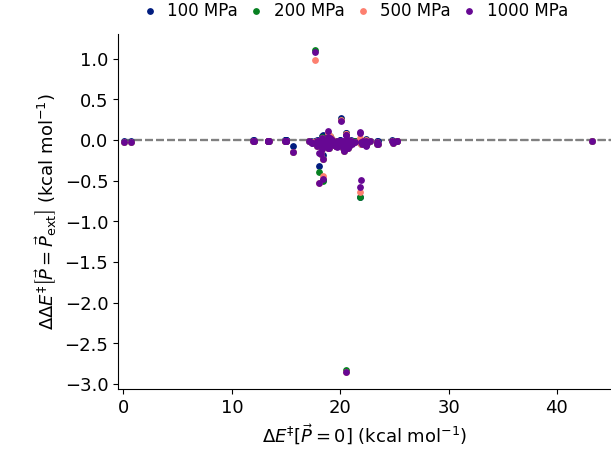

In [77]:
figure = None
for i,(mag, new_b) in enumerate(zip([100, 200, 500, 1000], new_barriers)):
    figure = plt.ScatterPlot(old_barriers, new_b,
                             label=f"{mag} MPa",
                             plot_legend=True,
                             legend_style={
                                 'frameon':False, 
                                 'fontsize':12,
                                 'ncol':4,
                                 'handletextpad':.05,
                                 'columnspacing':.1,
                                 'loc':'lower left',
                                 'bbox_to_anchor':[0, 1]
                             },
                             style_list={'color':rda.COLOR_PALETTE},
                             image_size=[440, 330],
                             padding=[[85, 0], [50, 25]],
                             plot_range=[[-.5, 45], None],
                             axes_labels=[
                                 r"$\Delta E^{\ddagger} \left[\vec{P}=0\right]$ (kcal mol$^{-1}$)", 
                                 r"$\Delta \Delta E^{\ddagger} \left[\vec{P}=\vec{P}_\text{ext}\right]$ (kcal mol$^{-1}$)"
                             ],
                             s=15,
                             figure=figure)
    plt.Plot(
        [0, 45],
        [0, 0],
        color='gray',
        linestyle='dashed',
        figure=figure,
        zorder=-1000
    )
    
# figure.savefig('figs/pressure_barrier_changes.svg')
figure

In [247]:
166 + 158 + 152 + 152

628

166
158
152
152



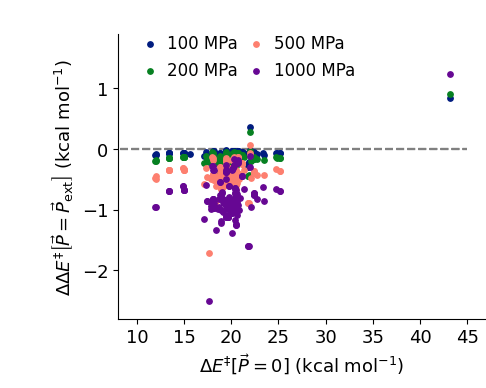

In [246]:
figure = None
for i,mag in enumerate([100, 200, 500, 1000]):
    sss = pressure_sheets[mag]
    print(
        np.sum(
            (~np.isnan(sss['nf_Ea(kcal/mol)']))
            & (~np.isnan(sss['DEa(kcal/mol)']))
        )
    )
          
    figure = plt.ScatterPlot(sss['nf_Ea(kcal/mol)'], sss['DEa(kcal/mol)'],
                             label=f"{mag} MPa",
                             plot_legend=True,
                             legend_style={
                                 'frameon':False, 
                                 'fontsize':12,
                                 'ncol':2,
                                 'handletextpad':.05,
                                 'columnspacing':.1,
                                 'loc':'upper left',
                                 'bbox_to_anchor':[0, 1.05]
                             },
                             style_list={'color':rda.COLOR_PALETTE},
                             image_size=[350, 280],
                             padding=[[85, 0], [50, 25]],
                             plot_range=[[8, 47], [-2.8, 1.9]],
                             axes_labels=[
                                 r"$\Delta E^{\ddagger} \left[\vec{P}=0\right]$ (kcal mol$^{-1}$)", 
                                 r"$\Delta \Delta E^{\ddagger} \left[\vec{P}=\vec{P}_\text{ext}\right]$ (kcal mol$^{-1}$)"
                             ],
                             s=15,
                             figure=figure)
    plt.Plot(
        [0, 45],
        [0, 0],
        color='gray',
        linestyle='dashed',
        figure=figure,
        zorder=-1000
    )
    
figure#.savefig('figs/pressure_barrier_changes_shrunk.svg')
# figure

### RMSDs

In [299]:
import pandas as pd

rmsd_data = pd.read_pickle('pressure_outputs/R_rmsd_dataset.pkl')
rmsd_data_T = pd.read_pickle('pressure_outputs/P_TS_rmsd_dataset.pkl')

In [ ]:
comp_R = rmsd_data[
        rmsd_data['comparison'] == 'nf_vs_gost1000'
    ]['rmsd_angstrom']
comp_T = rmsd_data_T[
        rmsd_data_T['comparison'] == 'nf_vs_gost1000'
    ]['rmsd_angstrom']

c_R = comp_R[comp_R < .2]
c_T = comp_T[comp_T < .2]
f0 = plt.HistogramPlot(
    c_R,
    image_size=[440, 330],
    axes_labels=[r"RMSD ($\mathrm{\AA}$)", "Density"],
    bins=100,
    weights=np.full(len(c_R), 1/len(c_R))
)
plt.HistogramPlot(
    c_T,
    bins=100,
    figure=f0,
    weights=np.full(len(c_T), 1/len(c_T)),
    color=plt.prep_color(palette='default', index=1, alpha=.5)
)
f0#.savefig('pressure_rmsd_density.svg')


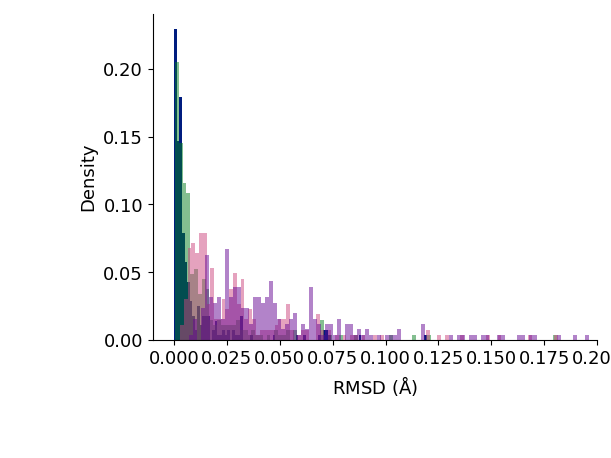

In [329]:
comp_R = rmsd_data[
        rmsd_data['comparison'] == 'nf_vs_gost1000'
    ]['rmsd_angstrom']
comp_T = rmsd_data_T[
        rmsd_data_T['comparison'] == 'nf_vs_gost1000'
    ]['rmsd_angstrom']

comp_R_500 = rmsd_data[
        rmsd_data['comparison'] == 'nf_vs_gost500'
    ]['rmsd_angstrom']
comp_T_500 = rmsd_data_T[
        rmsd_data_T['comparison'] == 'nf_vs_gost500'
    ]['rmsd_angstrom']

comp_R_200 = rmsd_data[
        rmsd_data['comparison'] == 'nf_vs_gost200'
    ]['rmsd_angstrom']
comp_T_200 = rmsd_data_T[
        rmsd_data_T['comparison'] == 'nf_vs_gost200'
    ]['rmsd_angstrom']

comp_R_100 = rmsd_data[
        rmsd_data['comparison'] == 'nf_vs_gost100'
    ]['rmsd_angstrom']
comp_T_100 = rmsd_data_T[
        rmsd_data_T['comparison'] == 'nf_vs_gost100'
    ]['rmsd_angstrom']

c_R = comp_R[comp_R < .2]
c_T = comp_T[comp_T < .2]

c_R_500 = comp_R_500[comp_R_500 < .2]
c_T_500 = comp_T_500[comp_T_500 < .2]

c_R_200 = comp_R_200[comp_R_200 < .2]
c_T_200 = comp_T_200[comp_T_200 < .2]

c_R_100 = comp_R_100[comp_R_100 < .2]
c_T_100 = comp_T_100[comp_T_100 < .2]

f0 = plt.HistogramPlot(
    c_R_100,
    plot_range=[[-.01, 0.2], None],
    image_size=[440, 330],
    axes_labels=[r"RMSD ($\mathrm{\AA}$)", "Density"],
    bins=100,
    weights=np.full(len(c_R_100), 1/len(c_R_100))
)
plt.HistogramPlot(
    c_R_200,
    image_size=[440, 330],
    axes_labels=[r"RMSD ($\mathrm{\AA}$)", "Density"],
    bins=100,
    figure=f0,
    color=plt.prep_color(palette='default', index=1, alpha=.5),
    weights=np.full(len(c_R_200), 1/len(c_R_200))
)
plt.HistogramPlot(
    c_R_500,
    bins=100,
    figure=f0,
    weights=np.full(len(c_R_500), 1/len(c_R_500)),
    color=plt.prep_color(palette='default', index=2, alpha=.5)
)
plt.HistogramPlot(
    c_R,
    bins=100,
    figure=f0,
    weights=np.full(len(c_R), 1/len(c_R)),
    color=plt.prep_color(palette='default', index=3, alpha=.5)
)

# plt.HistogramPlot(
#     c_T,
#     bins=100,
#     figure=f0,
#     weights=np.full(len(c_T), 1/len(c_T)),
#     color=plt.prep_color(palette='default', index=1, alpha=.5)
# )
f0#.savefig('figs/pressure_rmsd_density.svg')

In [330]:
comp_R = rmsd_data[
        rmsd_data['comparison'] == 'nf_vs_gost1000'
    ]['rmsd_angstrom']
comp_T = rmsd_data_T[
        rmsd_data_T['comparison'] == 'nf_vs_gost1000'
    ]['rmsd_angstrom']

comp_R_500 = rmsd_data[
        rmsd_data['comparison'] == 'nf_vs_gost500'
    ]['rmsd_angstrom']
comp_T_500 = rmsd_data_T[
        rmsd_data_T['comparison'] == 'nf_vs_gost500'
    ]['rmsd_angstrom']

comp_R_200 = rmsd_data[
        rmsd_data['comparison'] == 'nf_vs_gost200'
    ]['rmsd_angstrom']
comp_T_200 = rmsd_data_T[
        rmsd_data_T['comparison'] == 'nf_vs_gost200'
    ]['rmsd_angstrom']

comp_R_100 = rmsd_data[
        rmsd_data['comparison'] == 'nf_vs_gost100'
    ]['rmsd_angstrom']
comp_T_100 = rmsd_data_T[
        rmsd_data_T['comparison'] == 'nf_vs_gost100'
    ]['rmsd_angstrom']

c_R = comp_R[comp_R < .2]
c_T = comp_T[comp_T < .2]

c_R_500 = comp_R_500[comp_R_500 < .2]
c_T_500 = comp_T_500[comp_T_500 < .2]

c_R_200 = comp_R_200[comp_R_200 < .2]
c_T_200 = comp_T_200[comp_T_200 < .2]

c_R_100 = comp_R_100[comp_R_100 < .2]
c_T_100 = comp_T_100[comp_T_100 < .2]

f0 = plt.HistogramPlot(
    c_T_100,
    plot_range=[[-.01, 0.2], None],
    image_size=[440, 330],
    axes_labels=[r"RMSD ($\mathrm{\AA}$)", "Density"],
    bins=100,
    weights=np.full(len(c_T_100), 1/len(c_T_100))
)
plt.HistogramPlot(
    c_T_200,
    image_size=[440, 330],
    axes_labels=[r"RMSD ($\mathrm{\AA}$)", "Density"],
    bins=100,
    figure=f0,
    color=plt.prep_color(palette='default', index=1, alpha=.5),
    weights=np.full(len(c_T_200), 1/len(c_T_200))
)
plt.HistogramPlot(
    c_T_500,
    bins=100,
    figure=f0,
    weights=np.full(len(c_T_500), 1/len(c_T_500)),
    color=plt.prep_color(palette='default', index=2, alpha=.5)
)
plt.HistogramPlot(
    c_T,
    bins=100,
    figure=f0,
    weights=np.full(len(c_T), 1/len(c_T)),
    color=plt.prep_color(palette='default', index=3, alpha=.5)
)

# plt.HistogramPlot(
#     c_T,
#     bins=100,
#     figure=f0,
#     weights=np.full(len(c_T), 1/len(c_T)),
#     color=plt.prep_color(palette='default', index=1, alpha=.5)
# )
f0#.savefig('figs/pressure_rmsd_density_T.svg')

In [ ]:
f0 = plt.HistogramPlot(
    rmsds_R_50,
    plot_range=[[-.05, 1.65], None],
    image_size=[440, 330],
    axes_labels=[r"RMSD ($\mathrm{\AA}$)", "Density"],
    bins=100,
    weights=np.full(len(rmsds_R_50), 1/len(rmsds_R_50))
)
plt.HistogramPlot(
    rmsds_R_100,
    bins=100,
    figure=f0,
    weights=np.full(len(rmsds_R_100), 1/len(rmsds_R_100)),
    color=plt.prep_color(palette='default', index=1, alpha=.5)
)
plt.HistogramPlot(
    rmsds_R,
    bins=100,
    figure=f0,
    weights=np.full(len(rmsds_R), 1/len(rmsds_R)),
    color=plt.prep_color(palette='default', index=2, alpha=.5)
)
f0#.savefig('figs/rmsd_force.svg')

In [303]:
pressure_data_1000 = pd.read_excel('pressure/sorted_master_newdataset_rm_0910.xlsx', sheet_name='1000mpa')
pressure_data_500 = pd.read_excel('pressure/sorted_master_newdataset_rm_0910.xlsx', sheet_name='500mpa')
pressure_data_200 = pd.read_excel('pressure/sorted_master_newdataset_rm_0910.xlsx', sheet_name='200mpa')
pressure_data_100 = pd.read_excel('pressure/sorted_master_newdataset_rm_0910.xlsx', sheet_name='100mpa')
pressure_data_inc = pd.read_excel('pressure/sorted_master_newdataset_rm_0910.xlsx', sheet_name='1000mpa')

In [304]:
pressure_barriers = (pressure_data_1000['gost_Ea(kcal/mol)'] - pressure_data_1000['nf_Ea(kcal/mol)']).to_numpy()
pressure_barriers_500 = (pressure_data_500['gost_Ea(kcal/mol)'] - pressure_data_500['nf_Ea(kcal/mol)']).to_numpy()
pressure_barriers_200 = (pressure_data_200['gost_Ea(kcal/mol)'] - pressure_data_200['nf_Ea(kcal/mol)']).to_numpy()
pressure_barriers_100 = (pressure_data_100['gost_Ea(kcal/mol)'] - pressure_data_100['nf_Ea(kcal/mol)']).to_numpy()

In [18]:
distortion_sheet = pd.read_excel('pressure/sorted_master_newdataset_rm_0910.xlsx', sheet_name=f'SP_step0_stepN')
new_barriers = np.cumsum(distortion_sheet.to_numpy()[:, (-2, -4, -6, -8)].astype(float), axis=-1).T


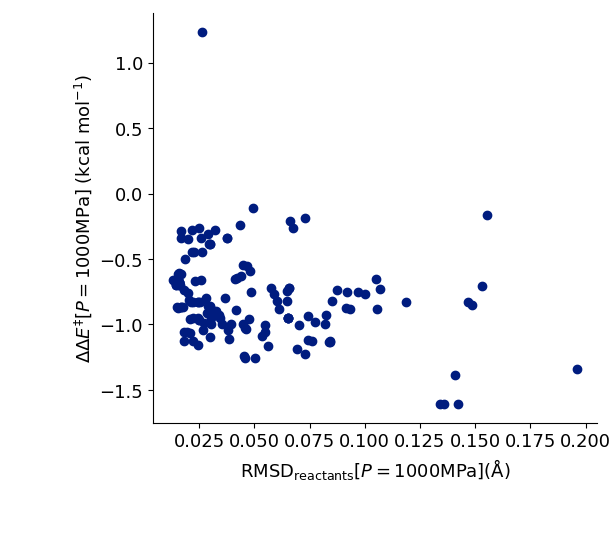

In [53]:
pbs = pressure_barriers[:len(comp_R)]
mask = ~np.isnan(pbs) & (np.abs(pbs)  < 19) & (comp_R < .2)

f0 = plt.ScatterPlot(
    comp_R[mask],
    pbs[mask],
    # color=plt.prep_color(palette='default', index=0, alpha=.01),
    axes_labels=[
        r"$\text{RMSD}_\text{reactants} \left[P=1000 \text{MPa}\right] (\mathrm{\AA})$", 
        r"$\Delta \Delta E^{\ddagger} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
    ]
)
# plt.Plot([0, .2], [fit(0), fit(.2)], figure=f0, 
#         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
#         )
f0

In [ ]:
fit_50 = rda.get_compliance_fit(
    rmsds_R_50,
    uuh_50.deltas * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
    include_intercept=False
)[1]


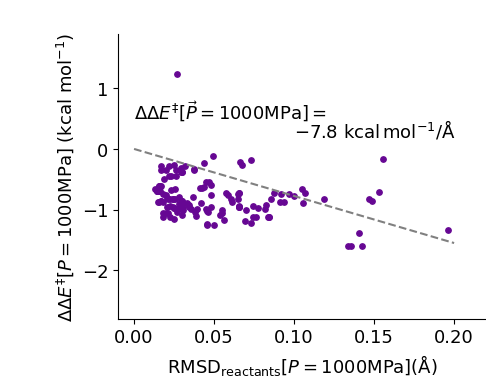

In [406]:
pbs2 = pressure_barriers[:len(comp_R)]
mask = ~np.isnan(pbs2) & (np.abs(pbs2) < 19)

f0 = plt.ScatterPlot(
    comp_R[mask],
    pbs2[mask],
    ticks=[[0, .05, .1, .15, .2], None],
    color=plt.prep_color(palette='default', index=3),
    image_size=[350, 280],
    padding=[[85, 0], [50, 25]],
    plot_range=[[-.01, .22], [-2.8, 1.9]],
    s=15,
    axes_labels=[
        r"$\text{RMSD}_\text{reactants} \left[P=1000 \text{MPa}\right] (\mathrm{\AA})$",
        r"$\Delta \Delta E^{\ddagger} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
        # "Full"
        # r"$\Delta E_\text{dist.} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
    ]
)
fit_stuff = rda.get_compliance_fit(
    comp_R[mask],
    pbs2[mask],
    include_intercept=False
)  # [1]
slope, fit = fit_stuff[:2]

plt.Plot([0, 0.2], [fit(0), fit(0.2)], figure=f0,
         linestyle='dashed', 
         color='gray',
         # color=plt.prep_color(palette='default', index=2)
         )
plt.Text(
    rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{P}}=1000 \text{{MPa}}\right] = $",
    [0, 0.5],
    font_size=13
).plot(f0)
plt.Text(
    rf"${slope[0]:.1f}\ \text{{kcal}}\,\text{{mol}}^{{-1}} / \mathrm{{\AA}}$",
    [.1, 0.2],
    font_size=13
).plot(f0)

f0#.savefig("figs/pressure_rmsd_fit_panel.svg", dpi=288)


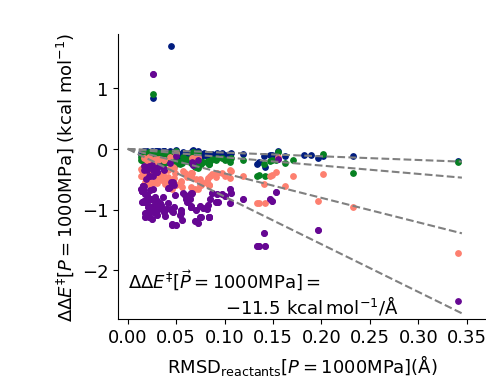

In [466]:
pbs2 = pressure_barriers[:len(comp_R)]
mask = ~np.isnan(pbs2) & (np.abs(pbs2) < 19) & (comp_R < .2)

f0 = plt.ScatterPlot(
    comp_R[mask],
    pbs2[mask],
    # ticks=[[0, .05, .1, .15, .2], None],
    color=plt.prep_color(palette='default', index=3),
    image_size=[350, 280],
    padding=[[85, 0], [50, 25]],
    plot_range=[[-.01, .37], [-2.8, 1.9]],
    s=15,
    axes_labels=[
        r"$\text{RMSD}_\text{reactants} \left[P=1000 \text{MPa}\right] (\mathrm{\AA})$",
        r"$\Delta \Delta E^{\ddagger} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
        # "Full"
        # r"$\Delta E_\text{dist.} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
    ]
)
fit_stuff = rda.get_compliance_fit(
    comp_R[mask],
    pbs2[mask],
    include_intercept=False
)  # [1]
slope, fit = fit_stuff[:2]

# plt.Plot([0, 0.2], [fit(0), fit(0.2)], figure=f0,
#          linestyle='dashed', 
#          color='gray',
#          # color=plt.prep_color(palette='default', index=2)
#          )
plt.Text(
    rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{P}}=1000 \text{{MPa}}\right] = $",
    [0, -2.3],
    font_size=13
).plot(f0)
plt.Text(
    rf"${slope[0]:.1f}\ \text{{kcal}}\,\text{{mol}}^{{-1}} / \mathrm{{\AA}}$",
    [.1, -2.7],
    font_size=13
).plot(f0)

for n,b0 in enumerate([
    pressure_barriers_100,
    pressure_barriers_200,
    pressure_barriers_500,
    pressure_barriers,
]):
    pbs2 = b0[:len(comp_R)]
    mask = ~np.isnan(pbs2) & (np.abs(pbs2) < 19)
    
    f0 = plt.ScatterPlot(
        comp_R[mask],
        pbs2[mask],
        color=plt.prep_color(palette=rda.COLOR_PALETTE, index=n),#, alpha=0),
        figure=f0,
        s=15
    )

    mask = mask & (pbs2 > -2) & (pbs2 < 1)
    fit_stuff = rda.get_compliance_fit(
        comp_R[mask],
        pbs2[mask],
        include_intercept=False
    )  # [1]
    slope, fit = fit_stuff[:2]
    
    plt.Plot([0, .345], [fit(0), fit(.345)], figure=f0,
             linestyle='dashed', color='gray'
             )


# eb = '#fdfdfe'
# x0, y0 = [-55, .8]
# x1, y1 = [x0+56, y0+1]
# # plt.Rectangle(
# #     [
# #         [x0, y0],
# #         [x1, y1]
# #     ],
# #     color=eb,
# #     edgecolor='#f0f0f0',#plt.prep_color(eb, lighten=-.2, modification_space='hsl'),
# #     zorder=-1000
# # ).plot(f0)
# plt.Text(
#     rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{P}}=1000 \text{{MPa}}\right] =$",
#     [x0+1, y1-.35],
#     font_size=13
# ).plot(
#     f0
# )
# plt.Text(
#     rf"$\left({slope[0]:.3f} \mathrm{{\AA}}^{{-3}} + {slope[1]:.3f}\right) \text{{ kcal mol}}^{{-1}}$",
#     [x0+6, y0+.15],
#     font_size=13
# ).plot(f0)



# plt.Text(
#     rf"$\left({slope[0]:.3f} \mathrm{{\AA}}^{{-3}}\right) \text{{ kcal mol}}^{{-1}}$",
#     [-35, -3.1],
#     font_size=13
# ).plot(f0)
# plt.Plot([0, .2], [fit(0), fit(.2)], figure=f0, 
#         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
#         )

f0#.savefig('figs/pressure_volume_fit_all.svg')

/Users/Mark/Documents/Postdoc/Development/cmcc-reactions/cmcc_reactions/reaction_data_analysis.py:2160: RuntimeWarning: invalid value encountered in sqrt
  rmse = np.sqrt(np.mean(residuals))



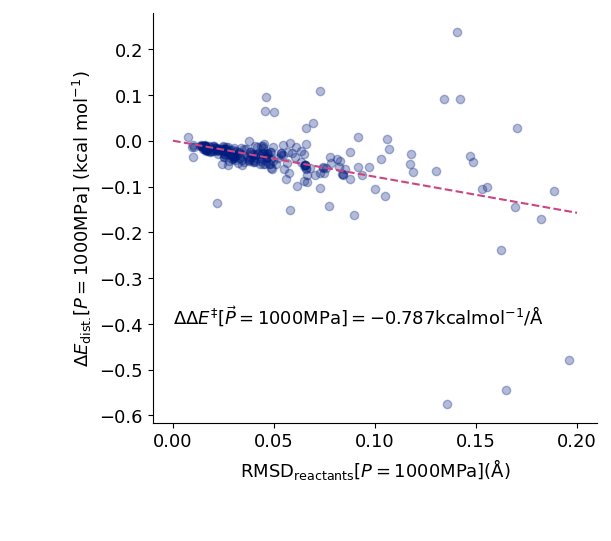

In [345]:
pbs2 = new_barriers[-1][:len(comp_R)]
mask = ~np.isnan(pbs2) & (comp_R < .2)

f0 = plt.ScatterPlot(
    comp_R[mask],
    pbs2[mask],
    ticks=[[0, .05, .1, .15, .2], None],
    color=plt.prep_color(palette='default', index=0, alpha=.3),
    axes_labels=[
        r"$\text{RMSD}_\text{reactants} \left[P=1000 \text{MPa}\right] (\mathrm{\AA})$", 
        r"$\Delta E_\text{dist.} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
    ]
)
fit_stuff = rda.get_compliance_fit(
    comp_R[mask],
    pbs2[mask],
    include_intercept=False
)  # [1]
slope, fit = fit_stuff[:2]

plt.Plot([0, 0.2], [fit(0), fit(0.2)], figure=f0,
         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
         )
plt.Text(
    rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{P}}=1000 \text{{MPa}}\right] = {slope[0]:.3f} "
    rf"\text{{kcal}} \text{{mol}}^{{-1}} / \mathrm{{\AA}}$",
    [0, -0.4],
    font_size=13
).plot(
    f0
)

f0#.savefig("figs/pressure_rmsd_fit.png", dpi=288)


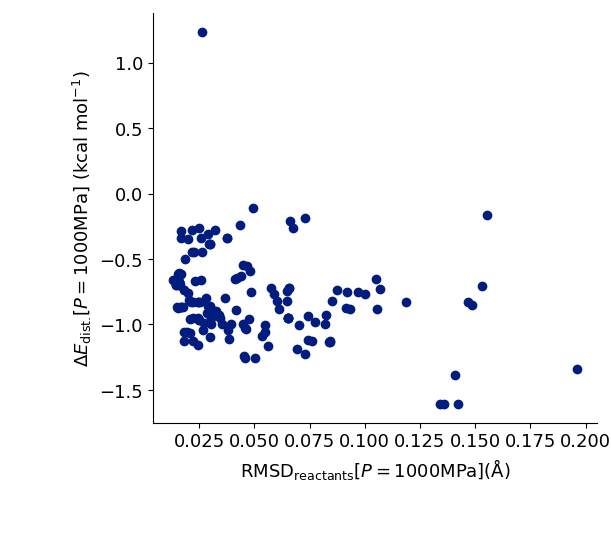

In [63]:
pbs = pressure_barriers[:len(comp_R)]
mask = ~np.isnan(pbs) & (comp_R < .2) & (np.abs(pbs) < 10)

f0 = plt.ScatterPlot(
    comp_R[mask],
    pbs[mask],
    # color=plt.prep_color(palette='default', index=0, alpha=.01),
    axes_labels=[
        r"$\text{RMSD}_\text{reactants} \left[P=1000 \text{MPa}\right] (\mathrm{\AA})$", 
        r"$\Delta E_\text{dist.} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
    ]
)
# plt.Plot([0, .2], [fit_50(0), fit_50(.2)], figure=f0, 
#         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
#         )
f0

In [427]:
pressure_confs = scaff.NumpyTreeArchive.load('pressure_outputs/R_conformers.npz')
pressure_confs_T = scaff.NumpyTreeArchive.load('pressure_outputs/P_TS_conformers.npz')

In [428]:
p_key_mask = ['1000' in pressure_confs[k] for k in pressure_confs.keys()]
p_keys = [k for k in pressure_confs.keys() if '1000' in pressure_confs[k]]

p_key_mask_T = ['1000' in pressure_confs_T[k] and 'nf' in pressure_confs_T[k] for k in pressure_confs_T.keys()]
p_keys_T = [k for m,k in zip(p_key_mask_T, pressure_confs_T.keys()) if m]

both_keys = np.intersect1d(p_keys_T, p_keys)
both_keys_mask = [k in both_keys for k in pressure_confs.keys()]


subkeys_mask = [k in p_keys_T for k in p_keys]

In [429]:
def load_pmols(i, ds='R'):
    if ds == 'T':
        if not isinstance(i, str):
            i = p_keys_T[i]
        pc = pressure_confs_T
    else:
        if not isinstance(i, str):
            i = p_keys[i]
        pc = pressure_confs
    conf = pc[i]
    return Molecule(conf['nf']['atoms'], conf['nf']['coords']), Molecule(conf['1000']['atoms'], conf['1000']['coords'])
def mol_volume_proxy(mol, radius_scaling=1, **opts):
    # return (
    #     mol.get_surface().get_triangulation(method='isosurface', grid_samples=50).volume()
    # )
    # try:
    return mol.get_surface(radius_scaling=radius_scaling).volume(**opts)
    # except:
    #     mol.to_file('/Users/Mark/Desktop/problem.xyz')
    #     raise
    # return mol.get_surface().volume(method='monte-carlo', n_samples=500_000)
    # pm.get_surface().surface_area()
def mol_area_proxy(mol, radius_scaling=1, **opts):
    # return (
    #     mol.get_surface().get_triangulation(method='isosurface', grid_samples=50).volume()
    # )
    # try:
    return mol.get_surface(radius_scaling=radius_scaling).surface_area(**opts)
    # except:
    #     mol.to_file('/Users/Mark/Desktop/problem.xyz')
    #     raise
    # return mol.get_surface().volume(method='monte-carlo', n_samples=500_000)
    # pm.get_surface().surface_area()
def mol_volume_comp(mol):
    # return (
    #     mol.get_surface().get_triangulation(method='isosurface', grid_samples=50).volume()
    # )
    try:
        return mol.get_surface().volume() - mol.get_surface().volume(method='monte-carlo', n_samples=1_000_000)
    except:
        mol.to_file('/Users/Mark/Desktop/problem.xyz')
        raise
    # return mol.get_surface().volume(method='monte-carlo', n_samples=500_000)
    # pm.get_surface().surface_area()
    
def pvolume_diffs(i, ds='R', **opts):
    nf, pm = load_pmols(i, ds=ds)
    return mol_volume_proxy(pm, **opts) - mol_volume_proxy(nf, **opts)

def nf_volume(i, ds='R', **opts):
    nf, pm = load_pmols(i, ds=ds)
    return mol_volume_proxy(nf, **opts)

def nf_area(i, ds='R', **opts):
    nf, pm = load_pmols(i, ds=ds)
    return mol_area_proxy(nf, **opts)
    
def pm_volume(i, ds='R', **opts):
    nf, pm = load_pmols(i, ds=ds)
    return mol_volume_proxy(pm, **opts)
    

In [6]:
# all_pdiffs = np.array([
#     pvolume_diffs(i) 
#     for i in range(len(p_keys))
# ])

In [430]:
all_pvols = np.array([
    pm_volume(i, radius_scaling=1.8)
    for i in range(len(p_keys))
])
all_pvols_T = np.array([
    pm_volume(i, radius_scaling=1.8, ds='T') 
    for i in range(len(p_keys_T))
])

In [431]:
all_nfvols = np.array([
    nf_volume(i, radius_scaling=1.8)
    for i in range(len(p_keys))
])
all_nfvols_T = np.array([
    nf_volume(i, radius_scaling=1.8, ds='T') 
    for i in range(len(p_keys_T))
])

In [293]:
# all_nfvols_unscaled = np.array([
#     nf_volume(i, radius_scaling=1)
#     for i in range(len(p_keys))
# ])
# all_nfvols_T_unscaled = np.array([
#     nf_volume(i, radius_scaling=1, ds='T') 
#     for i in range(len(p_keys_T))
# ])

In [ ]:
# pbs = pressure_barriers[:len(p_key_mask)][both_keys_mask]
# adiff = (all_nfvols_T) - (all_nfvols)[subkeys_mask]
# adiff = (all_pvols_T - all_nfvols_T) - (all_pvols - all_nfvols)[subkeys_mask]
# mask = ~np.isnan(pbs) & (np.abs(pbs) < 19) #& (np.abs(apd) < 5)

# plt.ScatterPlot(
#     adiff[mask],
#     pbs[mask],
#     # color=plt.prep_color(palette='default', index=0, alpha=.01),
#     axes_labels=[
#         r"$\Delta \text{V} \left[P=1000 \text{MPa}\right] (\mathrm{\AA}^3)$", 
#         r"$\Delta \Delta E^{\ddagger} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
#     ]
# )
# # plt.Plot([0, .2], [fit(0), fit(.2)], figure=f0, 
# #         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
# #         )

In [432]:
pbs = pressure_barriers[:len(p_key_mask)][both_keys_mask]
pbs2 = new_barriers[-1][:len(p_key_mask)][both_keys_mask]
# pbs = pbs - pbs2
# adiff = (all_nfvols_T) - (all_nfvols)[subkeys_mask]
# adiff = (all_pvols_T) - (all_pvols)[subkeys_mask]
adiff = (all_pvols - all_nfvols)[subkeys_mask]
# adiff = (all_pvols_T - all_nfvols_T)
# adiff = (all_pvols_T - all_nfvols_T) - (all_pvols - all_nfvols)[subkeys_mask]
mask = ~np.isnan(pbs) & (np.abs(pbs) < 19) #& (np.abs(adiff) < 10)

plt.ScatterPlot(
    adiff[mask],
    pbs[mask],
    color=plt.prep_color(palette='default', index=2),
    axes_labels=[
        r"$\Delta \text{V} \left[P=0 \text{MPa}\right] (\mathrm{\AA}^3)$", 
        r"$\Delta \Delta E^{\ddagger} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
    ]
)
# plt.Plot([0, .2], [fit(0), fit(.2)], figure=f0, 
#         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
#         )

NameError: name 'new_barriers' is not defined

In [471]:
pbs = pressure_barriers[:len(p_key_mask)][both_keys_mask]
# pbs2 = new_barriers[-1][:len(p_key_mask)][both_keys_mask]
# pbs = pbs - pbs2
adiff = (all_nfvols_T) - (all_nfvols)[subkeys_mask]
# adiff = (all_nfvols_T_unscaled) - (all_nfvols_unscaled)[subkeys_mask]
adiff = adiff * UnitsData.convert("BohrRadius", "Angstroms")**3
# adiff = (all_pvols_T) - (all_pvols)[subkeys_mask]
# adiff = (all_pvols_T - all_nfvols_T) - (all_pvols - all_nfvols)[subkeys_mask]
mask = ~np.isnan(pbs) & (np.abs(pbs) < 19) #& (np.abs(apd) < 5)

f0 = plt.ScatterPlot(
    adiff[mask],
    pbs[mask],
    image_size=[350, 280],
    padding=[[85, 0], [50, 25]],
    plot_range=[None, [-2.8, 1.9]],
    color=plt.prep_color(palette=rda.COLOR_PALETTE, index=3),#, alpha=0),
    axes_labels=[
        r"$\Delta \text{V} \left[P=0 \text{MPa}\right] (\mathrm{\AA}^3)$", 
        r"$\Delta \Delta E^{\ddagger} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
    ],
    s=15
)
mask = mask & (pbs > -2) & (pbs < 3)
fit_stuff = rda.get_compliance_fit(
    adiff[mask],
    pbs[mask],
    include_intercept=True
)  # [1]
slope, fit = fit_stuff[:2]

plt.Plot([-50, 2], [fit(-50), fit(2)], figure=f0,
         linestyle='dashed', color='gray'
         )

for n,b0 in enumerate([
    pressure_barriers_100,
    pressure_barriers_200,
    pressure_barriers_500
]):
    pbs3 = b0[:len(p_key_mask)][both_keys_mask]
    mask2 = ~np.isnan(pbs3) & (np.abs(pbs3) < 19) #& (pbs3 < 1.5)
    plt.ScatterPlot(
        adiff[mask2],
        pbs3[mask2],
        color=plt.prep_color(palette=rda.COLOR_PALETTE, index=n),#, alpha=0),
        figure=f0,
        s=15
    )

    mask = mask & (pbs3 > -2) & (pbs3 < 1)
    fit_stuff = rda.get_compliance_fit(
        adiff[mask],
        pbs3[mask],
        include_intercept=True
    )  # [1]
    slope, fit = fit_stuff[:2]
    
    plt.Plot([-50, 2], [fit(-50), fit(2)], figure=f0,
             linestyle='dashed', color='gray'
             )


eb = '#fdfdfe'
x0, y0 = [-55, .8]
x1, y1 = [x0+56, y0+1]
# plt.Rectangle(
#     [
#         [x0, y0],
#         [x1, y1]
#     ],
#     color=eb,
#     edgecolor='#f0f0f0',#plt.prep_color(eb, lighten=-.2, modification_space='hsl'),
#     zorder=-1000
# ).plot(f0)
plt.Text(
    rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{P}}=1000 \text{{MPa}}\right] =$",
    [x0+1, y1-.35],
    font_size=13
).plot(
    f0
)
plt.Text(
    rf"$\left({slope[0]:.3f} \mathrm{{\AA}}^{{-3}} + {slope[1]:.3f}\right) \text{{ kcal mol}}^{{-1}}$",
    [x0+6, y1-.35-.4],
    font_size=13
).plot(f0)

# plt.Text(
#     rf"$\left({slope[0]:.3f} \mathrm{{\AA}}^{{-3}}\right) \text{{ kcal mol}}^{{-1}}$",
#     [-35, -3.1],
#     font_size=13
# ).plot(f0)
# plt.Plot([0, .2], [fit(0), fit(.2)], figure=f0, 
#         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
#         )

f0.savefig('figs/pressure_volume_fit_shrunk.svg')

/Users/Mark/Documents/Postdoc/Development/cmcc-reactions/cmcc_reactions/reaction_data_analysis.py:2262: RuntimeWarning: invalid value encountered in sqrt
  rmse = np.sqrt(np.mean(residuals))


In [ ]:
pbs = pressure_barriers[:len(p_key_mask)][both_keys_mask]
adiff = (all_pvols_T - all_nfvols_T) - (all_pvols - all_nfvols)[subkeys_mask]
mask = ~np.isnan(pbs) & (np.abs(pbs) < 19) #& (np.abs(apd) < 5)

plt.ScatterPlot(
    adiff[mask],
    pbs[mask],
    # color=plt.prep_color(palette='default', index=0, alpha=.01),
    axes_labels=[
        r"$\Delta \text{V} \left[P=1000 \text{MPa}\right] (\mathrm{\AA}^3)$", 
        r"$\Delta \Delta E^{\ddagger} \left[P=1000 \text{MPa}\right]$ (kcal mol$^{-1}$)"
    ]
)
# plt.Plot([0, .2], [fit(0), fit(.2)], figure=f0, 
#         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
#         )

#### Uniaxial

In [42]:
uuh = d2_reg[
    lambda d: np.abs(d['force_magnitudes']) > 199
]
uuh_100 = d2_reg[
    lambda d: np.abs(d['force_magnitudes']) > 99,
    lambda d: np.abs(d['force_magnitudes']) < 199,
]
uuh_50 = d2_reg[
    lambda d: np.abs(d['force_magnitudes']) < 51
]

In [43]:
geoms_0 = uuh.reactant_geometries
geoms_f = uuh.force_modified_reactant_geometries
geoms_TS_0 = uuh.transition_state_geometries
geoms_TS_f = uuh.force_modified_transition_state_geometries

In [44]:
rmsds_R = np.array([
    nput.eckart_rmsd(
        g0,
        gf
    ) 
    for g0, gf in zip(geoms_0, geoms_f)
]) * UnitsData.convert("BohrRadius", "Angstroms")
rmsds_T = np.array([
    nput.eckart_rmsd(
        g0,
        gf
    ) 
    for g0, gf in zip(geoms_TS_0, geoms_TS_f)
]) * UnitsData.convert("BohrRadius", "Angstroms")

In [45]:
geoms_0_100 = uuh_100.reactant_geometries
geoms_f_100 = uuh_100.force_modified_reactant_geometries
geoms_TS_0_100 = uuh_100.transition_state_geometries
geoms_TS_f_100 = uuh_100.force_modified_transition_state_geometries

rmsds_R_100 = np.array([
    nput.eckart_rmsd(
        g0,
        gf
    ) 
    for g0, gf in zip(geoms_0_100, geoms_f_100)
]) * UnitsData.convert("BohrRadius", "Angstroms")
rmsds_T_100 = np.array([
    nput.eckart_rmsd(
        g0,
        gf
    ) 
    for g0, gf in zip(geoms_TS_0_100, geoms_TS_f_100)
]) * UnitsData.convert("BohrRadius", "Angstroms")

In [46]:
geoms_0_50 = uuh_50.reactant_geometries
geoms_f_50 = uuh_50.force_modified_reactant_geometries
geoms_TS_0_50 = uuh_50.transition_state_geometries
geoms_TS_f_50 = uuh_50.force_modified_transition_state_geometries

rmsds_R_50 = np.array([
    nput.eckart_rmsd(
        g0,
        gf
    ) 
    for g0, gf in zip(geoms_0_50, geoms_f_50)
]) * UnitsData.convert("BohrRadius", "Angstroms")
rmsds_T_50 = np.array([
    nput.eckart_rmsd(
        g0,
        gf
    ) 
    for g0, gf in zip(geoms_TS_0_50, geoms_TS_f_50)
]) * UnitsData.convert("BohrRadius", "Angstroms")

In [47]:
fit = rda.get_compliance_fit(
    rmsds_R,
    uuh.deltas * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
    include_intercept=False
)#[1]

/Users/Mark/Documents/Postdoc/Development/cmcc-reactions/cmcc_reactions/reaction_data_analysis.py:2262: RuntimeWarning: invalid value encountered in sqrt
  rmse = np.sqrt(np.mean(residuals))



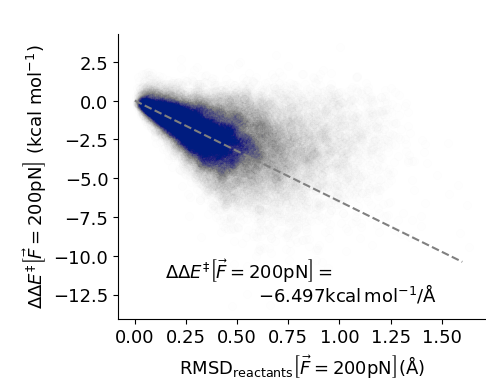

In [48]:
mask = rmsds_R < .5
fit_stuff = rda.get_compliance_fit(
    rmsds_R[mask],
    uuh.deltas[mask] * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
    include_intercept=False
)  # [1]
slope, fit = fit_stuff[:2]

f0 = plt.ScatterPlot(
    rmsds_R,
    uuh.deltas * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
    color=plt.prep_color(palette='default', index=0, alpha=.005),
    axes_labels=[
        r"$\text{RMSD}_\text{reactants} \left[\vec{F}=200 \text{pN}\right] (\mathrm{\AA})$",
        r"$\Delta \Delta E^{\ddagger} \left[\vec{F}=200 \text{pN}\right]$ (kcal mol$^{-1}$)"
    ],
    image_size=[350, 280],
    padding=[[85, 0], [50, 25]],
    # plot_range=[[-.01, .22], [-2.8, 1.9]],
)

# for n, rr, uu in [
#     [1, rmsds_R_100, uuh_100],
#     [2, rmsds_R_50, uuh_50],
# ]:
#     vv = uu.deltas * UnitsData.convert("Hartrees", "Kilocalories/Mole")
#     mask = np.abs(vv) < 10
#     plt.ScatterPlot(
#         rr[mask],
#         vv[mask],
#         color=plt.prep_color(palette='default', index=n, alpha=.005),
#         image_size=[350, 280],
#         figure=f0
#         # plot_range=[[-.01, .22], [-2.8, 1.9]],
#     )

plt.Plot([0, 1.6], [fit(0), fit(1.6)], figure=f0,
         linestyle='dashed', color='gray'
         )
plt.Text(
    rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{F}}=200 \text{{pN}}\right] =$",
    [.15, -11.4],
    font_size=13
).plot(f0)
plt.Text(
    rf"${slope[0]:.3f}\text{{kcal}}\, \text{{mol}}^{{-1}} / \mathrm{{\AA}}$",
    [.6, -12.9],
    font_size=13
).plot(f0)
# f0
f0#.savefig('figs/RMSD_r_base_panel.png', dpi=288)

In [22]:
mask = rmsds_R < .5
fit_stuff = rda.get_compliance_fit(
    rmsds_R[mask],
    uuh.deltas[mask] * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
    include_intercept=False
)  # [1]
slope, fit = fit_stuff[:2]

f0 = plt.ScatterPlot(
    rmsds_R,
    uuh.deltas * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
    color=plt.prep_color(palette='default', index=0, alpha=.01),
    axes_labels=[
        r"$\text{RMSD}_\text{reactants} \left[\vec{F}=200 \text{pN}\right] (\mathrm{\AA})$",
        r"$\Delta \Delta E^{\ddagger} \left[\vec{F}=200 \text{pN}\right]$ (kcal mol$^{-1}$)"
    ],
    image_size=[350, 280],
    padding=[[85, 0], [50, 25]],
    # plot_range=[[-.1, 1.8], [-13.5, 2.8]],
)

plt.Plot([0, 1.6], [fit(0), fit(1.6)], figure=f0,
         linestyle='dashed', color='gray'
         )
plt.Text(
    rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{F}}=200 \text{{pN}}\right] =$",
    [.15, -11.4],
    font_size=13
).plot(f0)
plt.Text(
    rf"${slope[0]:.3f}\text{{kcal}}\, \text{{mol}}^{{-1}} / \mathrm{{\AA}}$",
    [.6, -12.9],
    font_size=13
).plot(f0)
# f0
# f0#.savefig('figs/RMSD_r_base_panel.png', dpi=288)
f0.plot_range

/Users/Mark/Documents/Postdoc/Development/cmcc-reactions/cmcc_reactions/reaction_data_analysis.py:2262: RuntimeWarning: invalid value encountered in sqrt
  rmse = np.sqrt(np.mean(residuals))


([np.float64(-0.08173502691979435), np.float64(1.7164355653156813)],
 [np.float64(-14.048929228939848), np.float64(4.305240759825287)])

/Users/Mark/Documents/Postdoc/Development/cmcc-reactions/cmcc_reactions/reaction_data_analysis.py:2262: RuntimeWarning: invalid value encountered in sqrt
  rmse = np.sqrt(np.mean(residuals))



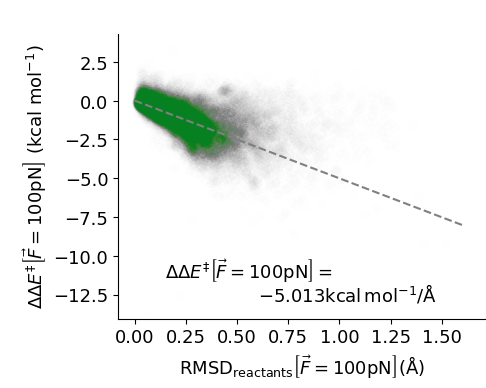

In [52]:
mag = 100
r_data = rmsds_R_100
uuh_data = uuh_100
idx = 1

mask = r_data < .5
fit_stuff = rda.get_compliance_fit(
    r_data[mask],
    uuh_data.deltas[mask] * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
    include_intercept=False
)  # [1]
slope, fit = fit_stuff[:2]

f0 = plt.ScatterPlot(
    r_data,
    uuh_data.deltas * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
    color=plt.prep_color(palette='default', index=idx, alpha=.005),
    axes_labels=[
        r"$\text{RMSD}_\text{reactants} \left[\vec{F}="+str(mag)+r" \text{pN}\right] (\mathrm{\AA})$",
        r"$\Delta \Delta E^{\ddagger} \left[\vec{F}="+str(mag)+r" \text{pN}\right]$ (kcal mol$^{-1}$)"
    ],
    image_size=[350, 280],
    padding=[[85, 0], [50, 25]],
    plot_range=[
        [np.float64(-0.08173502691979435), np.float64(1.7164355653156813)],
 [np.float64(-14.048929228939848), np.float64(4.305240759825287)]
    ],
)

plt.Plot([0, 1.6], [fit(0), fit(1.6)], figure=f0,
         linestyle='dashed', color='gray'
         )
plt.Text(
    rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{F}}={mag} \text{{pN}}\right] =$",
    [.15, -11.4],
    font_size=13
).plot(f0)
plt.Text(
    rf"${slope[0]:.3f}\text{{kcal}}\, \text{{mol}}^{{-1}} / \mathrm{{\AA}}$",
    [.6, -12.9],
    font_size=13
).plot(f0)
# f0
f0#.savefig('figs/RMSD_r_100.png', dpi=288)

In [41]:
f0 = plt.HistogramPlot(
    rmsds_R,
    image_size=[440, 330],
    axes_labels=[r"RMSD ($\mathrm{\AA}$)", "Density"],
    bins=100,
    weights=np.full(len(rmsds_R), 1/len(rmsds_R))
)
plt.HistogramPlot(
    rmsds_T,
    bins=100,
    figure=f0,
    weights=np.full(len(rmsds_T), 1/len(rmsds_T)),
    color=plt.prep_color(palette='default', index=1, alpha=.5)
)
# f0.savefig('figs/rmsd_force.svg')

In [46]:
f0 = plt.HistogramPlot(
    rmsds_T_50,
    plot_range=[[-.05, 1.65], None],
    image_size=[440, 330],
    axes_labels=[r"RMSD ($\mathrm{\AA}$)", "Density"],
    bins=100,
    weights=np.full(len(rmsds_R_50), 1/len(rmsds_R_50))
)
plt.HistogramPlot(
    rmsds_T_100,
    bins=100,
    figure=f0,
    weights=np.full(len(rmsds_R_100), 1/len(rmsds_R_100)),
    color=plt.prep_color(palette='default', index=1, alpha=.5)
)
plt.HistogramPlot(
    rmsds_T,
    bins=100,
    figure=f0,
    weights=np.full(len(rmsds_R), 1/len(rmsds_R)),
    color=plt.prep_color(palette='default', index=2, alpha=.5)
)
f0#.savefig('figs/rmsd_force_T.svg')

In [45]:
f0 = plt.HistogramPlot(
    rmsds_R_50,
    plot_range=[[-.05, 1.65], None],
    image_size=[440, 330],
    axes_labels=[r"RMSD ($\mathrm{\AA}$)", "Density"],
    bins=100,
    weights=np.full(len(rmsds_R_50), 1/len(rmsds_R_50))
)
plt.HistogramPlot(
    rmsds_R_100,
    bins=100,
    figure=f0,
    weights=np.full(len(rmsds_R_100), 1/len(rmsds_R_100)),
    color=plt.prep_color(palette='default', index=1, alpha=.5)
)
plt.HistogramPlot(
    rmsds_R,
    bins=100,
    figure=f0,
    weights=np.full(len(rmsds_R), 1/len(rmsds_R)),
    color=plt.prep_color(palette='default', index=2, alpha=.5)
)
f0#.savefig('figs/rmsd_force.svg')

### Volume Coordinate Comparisons

In [111]:
subds = d2_reg.sample(100)

In [231]:
bubububu = rda.get_dienophile_groups(subds)[0].group_by_props('d_path')

In [116]:
def get_system_structs(ds, subsampling=1):
    return guh.initial_trajectory.structures[::subsampling]
def get_system_volumes(ds, subsampling=1):
    guh = ds[0]
    vols = [
        m.get_surface().volume() * UnitsData.convert("BohrRadius", "Angstroms")**3
        for m in guh.initial_trajectory.mols[::subsampling]
    ]
    return vols


In [120]:
subvols_5 = {k:get_system_volumes(ds, 5) for k,ds in bubububu.items()}

In [ ]:
fig = None
for k,f in subvols.items():
    fig = trajt.plot_reaction_profile(
        get_system_structs(bubububu[k]),
        f,
        figure=fig,
        baseline=f[0],
        mark_critical_points=False,
        energy_label=r"Volume ($\mathrm{\AA}^3$)",
        initial_energy_unit="Kilocalories/Mole"
    )
fig
    

In [ ]:
trajt.plot_reaction_profile(
        guh.initial_trajectory.structures,
        vols,
        baseline=0,
        mark_critical_points=False,
        energy_label=r"Volume ($\mathrm{\AA}^3$)",
        initial_energy_unit="Kilocalories/Mole"
    )

In [182]:
fack = np.load('volumes_along_reaction_coords_5.npz')

In [201]:
fack_dict = dict(fack)
fack_dict['key_names'] = [f.replace('/', '_') for f in fack_dict['key_names']]

In [202]:
np.savez('volumes_along_reaction_coords_5_fixed.npz',
         **fack_dict
        )

In [198]:
fack['key_names']

array(['AFEKCROTSQZKAP-ASODMVGOSA-N/0/pipeline_data',
       'AFEKCROTSQZKAP-CFCGPWAMSA-N/0/pipeline_data',
       'AFEKCROTSQZKAP-SXNZSPLWSA-N/0/pipeline_data', ...,
       'ZRLBFEQFNUZGJW-SQJZIBIZSA-N/9/pipeline_data', 'coords', 'volumes'],
      shape=(1271,), dtype='<U44')

In [ ]:
fack['key_names'] = [f.replace('/', '_') for f in fack['key_names']]

In [203]:
subvols = scaff.NumpyTreeArchive.load(
    'volumes_along_reaction_coords_5_fixed.npz'
)

In [359]:
activation_vols = np.load(
    'activation_volumes.npz'
)
activation_vols = dict(zip(activation_vols['keys'], activation_vols['volumes']))

In [213]:
k0 = next(iter(bubububu.keys()))

In [357]:
d2_rekeyed = rda.get_dienophile_groups(d2_reg)[0].group_by_props('d_path')

In [360]:
dv_edata = []
for k,ds in d2_rekeyed.items():
    # vols = subvols[k.replace("/", "_")]['volumes']
    v = activation_vols[k]
    ds = ds[lambda d:np.abs(d['force_magnitudes']) > 199]
    for n,dd in enumerate(ds):
        try:
            dv_edata.append([
                v,
                # vols[len(vols) - (1 + dd.refined_trajectory.ts_index)] - vols[-1],
                rda.fmrd_barrier(dd)
            ])
        except IndexError:
            pass
dv_edata = np.array(dv_edata)
    

In [403]:
# mask = rmsds_R < .5
# fit_stuff = rda.get_compliance_fit(
#     rmsds_R[mask],
#     uuh.deltas[mask] * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
#     include_intercept=False
# )  # [1]
# slope, fit = fit_stuff[:2]


f0 = plt.ScatterPlot(dv_edata[:, 0], dv_edata[:, 1], 
                     color=plt.prep_color(palette='default', index=0, alpha=.01),
                     axes_labels=[
                           r"$\Delta$V $\left[\vec{F}=0 \text{pN}\right]$ ($\mathrm{\AA}^3$)", 
                           r"$\Delta \Delta E^{\ddagger} \left[\vec{F}=200 \text{pN}\right]$ (kcal mol$^{-1}$)"
                    ],
                    
                    image_size=[350, 280],
    padding=[[85, 0], [50, 25]],
                    )
fit_stuff = rda.get_compliance_fit(
    dv_edata[:, 0], 
    dv_edata[:, 1],
    include_intercept=True
)  # [1]
slope, fit = fit_stuff[:2]

plt.Plot([-10, -6], [fit(-10), fit(-6)], figure=f0,
         linestyle='dashed', color='gray'
         )
plt.Text(
    rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{F}}=200 \text{{pN}}\right] =$",
    [-10, -11.1 - .3],
    font_size=13
).plot(f0)
plt.Text(
    rf"$\left({slope[0]:.3f} \mathrm{{\AA}}^{{-3}} + {slope[1]:.3f}\right) \text{{kcal}}\,\text{{mol}}^{{-1}}$",
    [-9.2, -12.6 - .3],
    font_size=13
).plot(f0)
# f0
f0#.savefig('figs/activation_volume_force_plot_panel.png', dpi=288)

In [310]:
subvols = scaff.NumpyTreeArchive.load(
    'volumes_along_reaction_coords.npz'
)

In [312]:
fig = None
for k in subvols.keys():
    f = subvols[k]
    fig = trajt.plot_reaction_profile(
        f['coords'],
        f['volumes'],
        figure=fig,
        baseline=f['volumes'][0],
        mark_critical_points=False,
        energy_label=r"$\Delta$Volume ($\mathrm{\AA}^3$)",
        initial_energy_unit="Kilocalories/Mole",
        color=plt.prep_color(palette='default', index=0, alpha=.05)
    )
fig.savefig('figs/reaction_coords_volumes.svg')


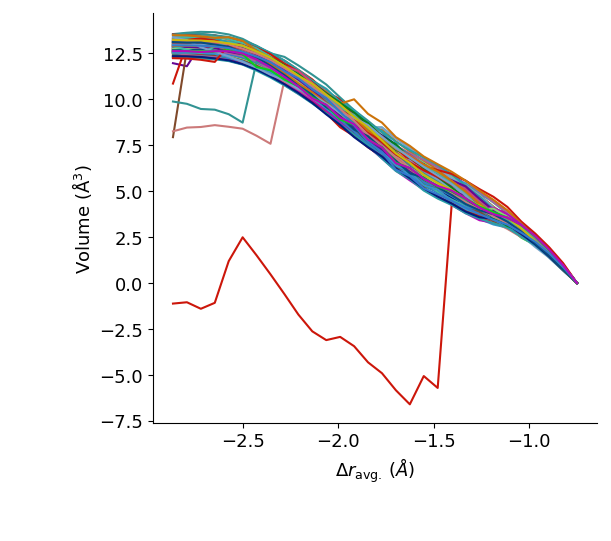

In [119]:
fig = None
for k,f in subvols.items():
    fig = trajt.plot_reaction_profile(
        get_system_structs(bubububu[k]),
        f,
        figure=fig,
        baseline=f[0],
        mark_critical_points=False,
        energy_label=r"Volume ($\mathrm{\AA}^3$)",
        initial_energy_unit="Kilocalories/Mole"
    )
fig
    

In [98]:
guh.initial_trajectory.plot_profile(
    energies=vols
)

TypeError: plot_reaction_profile() got multiple values for argument 'energies'


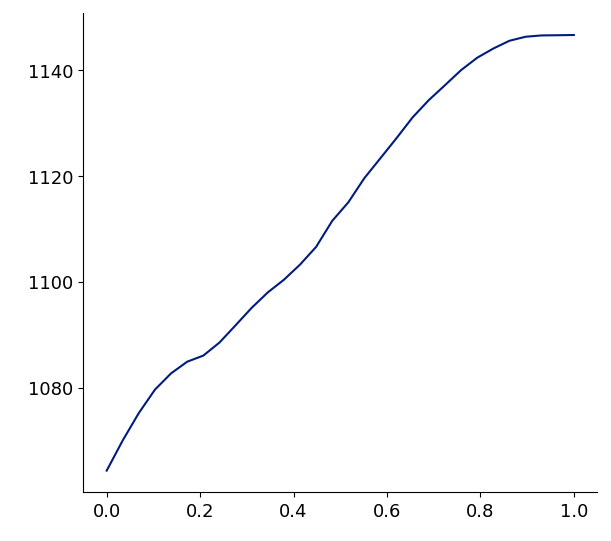

In [97]:
plt.Plot(
    np.linspace(0, 1, len(vols)),
    vols,
    axes_labels["Reaction Coordinate (arb.)", "V"]
)

### Sharon Misc

###### SMILES

In [86]:
smi_groups = ds_reg.group_by_props('smiles')

In [87]:
import rdkit.Chem.AllChem as Chem

cs = {Chem.CanonSmiles(k):d for k,d in smi_groups.items()}

In [140]:
wtf = rda.get_dienophile_groups(d2_reg)

In [108]:
good_smis = np.where(ds_data[1000][2])[0]

In [123]:
np.unique([smis[i] for i in good_smis])

array(['Fc1cc[c:8]([C@@H:3]2[CH:1]3[CH:5]=[CH:6][C@@H:2]([CH:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1',
       'Fc1cc[c:8]([C@@H:3]2[CH:1]3[CH:5]=[CH:6][C@H:2]([CH:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1',
       'Fc1cc[c:8]([C@H:3]2[CH:1]3[CH:5]=[CH:6][C@@H:2]([CH:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1',
       'Fc1cc[c:8]([C@H:3]2[CH:1]3[CH:5]=[CH:6][C@H:2]([CH:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1',
       'N[CH2:8][C:3]1([CH2:9]N)[CH:1]2[CH:5]=[CH:6][C@@H:2]([CH:4]1[CH2:10]N)[CH2:7]2',
       'N[CH2:8][C:3]1([CH2:9]N)[CH:1]2[CH:5]=[CH:6][C@H:2]([CH:4]1[CH2:10]N)[CH2:7]2',
       'N[CH2:8][C@@H:3]1[CH:1]2[CH:5]=[CH:6][C@@H:2]([CH:4]1[c:9]1ccc(F)cc1)[CH2:7]2',
       'N[CH2:8][C@@H:3]1[CH:1]2[CH:5]=[CH:6][C@H:2]([CH:4]1[c:9]1ccc(F)cc1)[CH2:7]2',
       'N[CH2:8][C@H:3]1[CH:1]2[CH:5]=[CH:6][C@@H:2]([CH:4]1[c:9]1ccc(F)cc1)[CH2:7]2',
       'N[CH2:8][C@H:3]1[CH:1]2[CH:5]=[CH:6][C@H:2]([CH:4]1[c:9]1ccc(F)cc1)[CH2:7]2'],
      dtype='<U84')

In [116]:
ds_data[1000][1]

array([-1.08891719, -0.8381644 , -0.69917106, -0.92890227, -0.6063624 ,
       -0.87374419, -0.96347805, -0.66930161, -1.31287532, -0.72759724,
       -0.5696531 , -0.712286  , -0.82498671, -0.61301401,  0.48418631,
       -0.84205496, -0.8408627 , -0.37612918, -0.85617393])

In [149]:

list(wtf[1]['CN CN'].keys())

['N[CH2:8][C@@:3]1([CH2:9]N)[CH:1]2[CH:5]=[CH:6][CH:2]([CH2:4]1)[CH2:7]2',
 'N[CH2:8][C@@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@H:4]1[CH2:9]N)[CH2:7]2',
 'N[CH2:8][C@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@@H:4]1[CH2:9]N)[CH2:7]2',
 'N[CH2:8][C@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@H:4]1[CH2:9]N)[CH2:7]2']

In [150]:
smi_pairs = {
    'N[CH2:8][C:3]1([CH2:9]N)[CH:1]2[CH:5]=[CH:6][C@@H:2]([CH:4]1[CH2:10]N)[CH2:7]2':
    ('CN CN', 'N[CH2:8][C@@:3]1([CH2:9]N)[CH:1]2[CH:5]=[CH:6][CH:2]([CH2:4]1)[CH2:7]2'),
    'N[CH2:8][C:3]1([CH2:9]N)[CH:1]2[CH:5]=[CH:6][C@H:2]([CH:4]1[CH2:10]N)[CH2:7]2':
    ('CN CN', 'N[CH2:8][C@@:3]1([CH2:9]N)[CH:1]2[CH:5]=[CH:6][CH:2]([CH2:4]1)[CH2:7]2'),
    'N[CH2:8][C@@H:3]1[CH:1]2[CH:5]=[CH:6][C@@H:2]([CH:4]1[c:9]1ccc(F)cc1)[CH2:7]2':
    ('CN Fc1ccccc1', 'N[CH2:8][C@@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@@H:4]1[c:9]1ccc(F)cc1)[CH2:7]2'),
    'N[CH2:8][C@@H:3]1[CH:1]2[CH:5]=[CH:6][C@H:2]([CH:4]1[c:9]1ccc(F)cc1)[CH2:7]2':
    ('CN Fc1ccccc1', 'N[CH2:8][C@@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@H:4]1[c:9]1ccc(F)cc1)[CH2:7]2'),
    'N[CH2:8][C@H:3]1[CH:1]2[CH:5]=[CH:6][C@@H:2]([CH:4]1[c:9]1ccc(F)cc1)[CH2:7]2':
    ('CN Fc1ccccc1', 'N[CH2:8][C@H:3]1[CH:1]2[CH:5]=[CH:6][CH:2]([C@@H:4]1[c:9]1ccc(F)cc1)[CH2:7]2'),
    'N[CH2:8][C@H:3]1[CH:1]2[CH:5]=[CH:6][C@H:2]([CH:4]1[c:9]1ccc(F)cc1)[CH2:7]2':
    ('CN Fc1ccccc1', 'N[CH2:8][C@:3]1([c:9]2ccc(F)cc2)[CH:1]2[CH:5]=[CH:6][CH:2]([CH2:4]1)[CH2:7]2'),
    'Fc1cc[c:8]([C@@H:3]2[CH:1]3[CH:5]=[CH:6][C@@H:2]([CH:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1':
    ('Fc1ccccc1 Fc1ccccc1', 'Fc1cc[c:8]([C@H:3]2[CH:1]3[CH:5]=[CH:6][CH:2]([C@H:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1'),
    'Fc1cc[c:8]([C@H:3]2[CH:1]3[CH:5]=[CH:6][C@H:2]([CH:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1':
    ('Fc1ccccc1 Fc1ccccc1', 'Fc1cc[c:8]([C@H:3]2[CH:1]3[CH:5]=[CH:6][CH:2]([C@H:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1'),
    'Fc1cc[c:8]([C@@H:3]2[CH:1]3[CH:5]=[CH:6][C@H:2]([CH:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1':
    ('Fc1ccccc1 Fc1ccccc1', 'Fc1cc[c:8]([C@@H:3]2[CH:1]3[CH:5]=[CH:6][CH:2]([C@H:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1'),
    'Fc1cc[c:8]([C@H:3]2[CH:1]3[CH:5]=[CH:6][C@@H:2]([CH:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1':
    ('Fc1ccccc1 Fc1ccccc1', 'Fc1cc[c:8]([C@H:3]2[CH:1]3[CH:5]=[CH:6][CH:2]([C@@H:4]2[c:9]2ccc(F)cc2)[CH2:7]3)cc1')

}


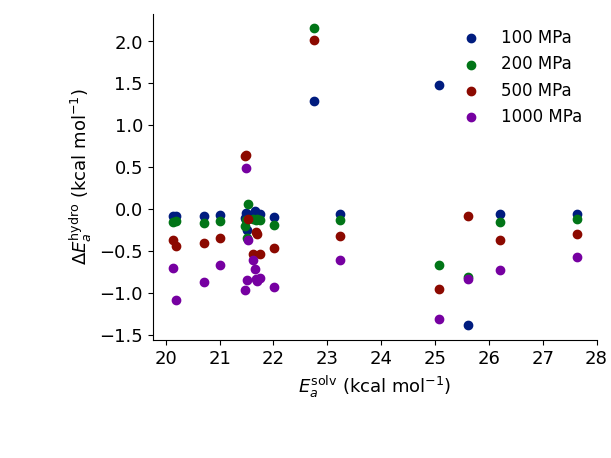

In [181]:
ds_data = {}
for mag in [100, 200, 500, 1000]:
    nf = sheets[mag][:, (2, 3)]
    gf = sheets[mag][:, (10, 12)]
    bf = rda.eh2kcal * (
        (gf[:, 1] - gf[:, 0])
    )
    b0 = rda.eh2kcal * (
        (nf[:, 1] - nf[:, 0])
    )
    db =  bf - b0
    mask=~np.isnan(db)
    mask=mask & (db > -15)
    mask=mask & (b0 > 10)
    ds_data[mag] = (b0[mask], db[mask], bf[mask], mask, db, nf, gf)

figure = None
for i,(mag, ds) in enumerate(ds_data.items()):
    figure = plt.ScatterPlot(ds[0], ds[1],
                             label=f"{mag} MPa",
                             plot_legend=True,
                             legend_style={'frameon':False, 'fontsize':12},
                             image_size=[440, 330],
                             axes_labels=[
                                 r"$E_a^\text{solv}$ (kcal mol$^{-1}$)", 
                                 r"$\Delta E_a^\text{hydro}$ (kcal mol$^{-1}$)"
                             ],
                             figure=figure)
# figure.savefig('pressure_barrier_changes.svg')
figure

In [182]:
len(force_means)

19

In [165]:
ds_data[1000][0]

array([20.19739644, 25.61236394, 20.13364148, 22.01391086, 23.23291077,
       20.70818915, 21.46383606, 21.01253124, 25.06787397, 26.21370627,
       27.63796452, 21.65535195, 21.75462395, 21.61713662, 21.48190833,
       21.50826373, 21.67913456, 21.52558299, 21.69111999])

In [164]:
ds_data[1000][2]

array([19.10847925, 24.77419954, 19.43447042, 21.08500859, 22.62654836,
       19.83444496, 20.50035801, 20.34322964, 23.75499865, 25.48610904,
       27.06831142, 20.94306595, 20.92963724, 21.00412262, 21.96609464,
       20.66620877, 20.83827186, 21.14945381, 20.83494606])

In [170]:
(
    ds_data[1000][-1][mask,] 
    - ds_data[1000][-2][mask,]
) * rda.eh2kcal

array([[13.4850531 , 12.39613591],
       [13.2335473 , 12.39538289],
       [13.16910208, 12.46993102],
       [13.26868783, 12.33978555],
       [12.94652447, 12.34016206],
       [13.34060041, 12.46685622],
       [13.37436042, 12.41088238],
       [13.11670503, 12.44740343],
       [12.54579691, 11.23292159],
       [11.97727333, 11.2496761 ],
       [11.90956506, 11.33991196],
       [15.15937387, 14.44708787],
       [15.22689389, 14.40190719],
       [15.03073443, 14.41772043],
       [13.94068772, 14.42487404],
       [15.22632914, 14.38427417],
       [15.29937124, 14.45850854],
       [14.75199472, 14.37586555],
       [15.25061375, 14.39443983]])

In [184]:
dts

[0.17226864157846286,
 0.17226864157846286,
 0.16545918152324118,
 0.16545918152324118,
 0.20757091550595438,
 0.20757091550595438,
 0.17849669892493203,
 0.17849669892493203,
 0.10707797630576138,
 0.10707797630576138,
 0.10707797630576138,
 1.3247854568003274,
 1.3247854568003274,
 0.8769330259540062,
 0.8769330259540062,
 0.7529664103429491,
 0.7529664103429491,
 0.8769330259540062,
 0.8769330259540062]

In [185]:
drs

[2.4400763323536094,
 2.4400763323536094,
 1.948246633893575,
 1.948246633893575,
 2.1351526258182894,
 2.1351526258182894,
 0.9624784783801305,
 0.9624784783801305,
 0.7867744210975339,
 0.7867744210975339,
 0.7867744210975339,
 2.242988746397677,
 2.242988746397677,
 1.9122729792055997,
 1.9122729792055997,
 2.6738708093539834,
 2.6738708093539834,
 1.9122729792055997,
 1.9122729792055997]

In [ ]:
(
    ds_data[1000][-1][mask,] 
    - ds_data[1000][-2][mask,]
) * rda.eh2kcal


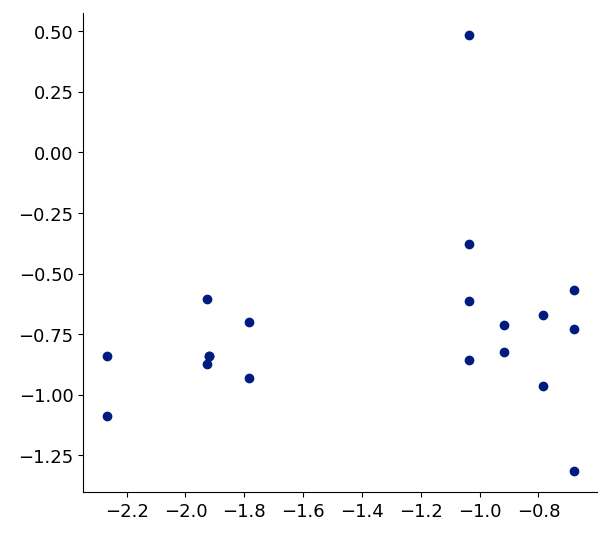

In [183]:
force_means = []
dts = []
drs = []
for s in [smis[i] for i in good_smis]:
    k,v = smi_pairs[s]
    force_means.append(
        np.mean(
            wtf[1][k][v].deltas * rda.eh2kcal
        )
    )
    drs.append(
        np.mean(
            wtf[1][k][v].delta_r * rda.eh2kcal
        )
    )
    dts.append(
        np.mean(
            wtf[1][k][v].delta_t * rda.eh2kcal
        )
    )
plt.ScatterPlot(
    force_means,
    ds_data[1000][-3][good_smis,]
)

### Ryan

In [255]:
import cmcc_reactions.cogef as cog2

In [256]:
all_gamma_data = dev.read_json('../gamma_escans_derivs_expanded.json')

In [313]:
all_gamma_data_old = dev.read_json('../gamma_escans_derivs_original_fscan.json')
if all('fscan' in v or 'cscan' in v 
       for v in all_gamma_data_old.values()):
    _ = {}
    for k,v in all_gamma_data_old.items():
        if k not in _: _[k] = {}
        t = _[k]
        for tag in ['cscan', 'fscan']:
            if tag in v:
                if tag not in t: t[tag] = {}
                r = v[tag]
                for k2,vv in r.items():
                    t[tag][k2] = vv | {'atoms':v['atoms']}
    all_gamma_data_old = _

##### Figure 1

In [259]:
gamma_data = {k:v['cscan'] for k,v in all_gamma_data.items()}

In [260]:
reaction_iter = [
    (i, j)
    for i, v in gamma_data.items()
    for j in v.keys()
]

In [ ]:
# cog2 = importlib.reload(cog2)

# # r, k = reaction_iter[100]
# r, k = list((r,k) for r,k in reaction_iter if k.startswith('bond'))[0]
# base_fig = cog2.plot_gamma_comp(gamma_data[r][k], interpolation_points=100, shift_curves=False)
# cog2.plot_gamma_force_points(gamma_data[r][k], 100, figure=base_fig, interpolation_points=100, 
#                              shift_curves=False)
# cog2.solve_for_force(gamma_data[r][k], 100, interpolation_points=100, return_had_nans=True, return_barriers=True)

In [189]:
cog2 = importlib.reload(cog2)

f = cog2.plot_scan_force_coordinate_data(gamma_data, reaction_iter, verbose=False,
                                         mags=[50],
                                         scatter_styles=dict(
                                             s=15,
                                             plot_range=[None, [-.53, .5]]
                                         ),
                                         # bfs=
                                         )
f.savefig('figs/coordinate_type_rigid_response.png', dpi=300)

In [181]:
np.unique([r.split("_")[0] for r,k in reaction_iter]).shape

(40,)

In [88]:

# r, k = reaction_iter[100]
solve_for_force(gamma_data[r][k], 50)

((np.float64(-0.05967961918443472),
  np.float64(-0.011471563626926308),
  np.int64(15),
  np.float64(-0.14334483121904693)),
 (np.float64(0.04377925091158626),
  np.float64(0.012651496513441763),
  np.int64(15),
  np.float64(-0.14334483121904693)))

In [89]:
np.linalg.norm(
    gamma_data[r][k]['reactant']['dX_dq'],
    axis=1
).shape

(33,)

In [ ]:
plot_gamma_force_points(
    gamma_data[r][k],
    0
)


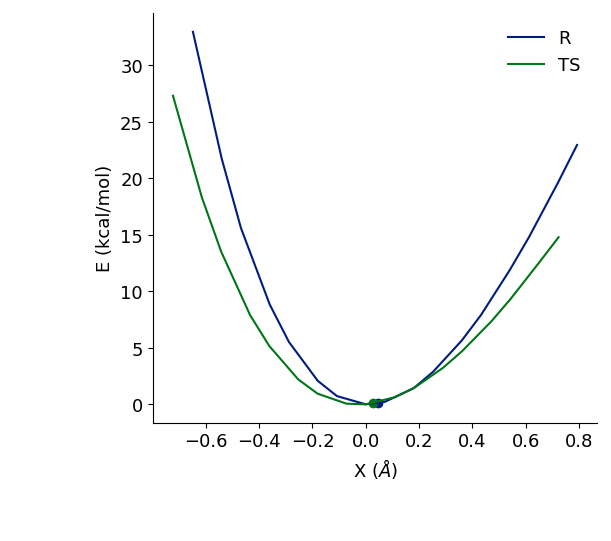

In [217]:
fig = plot_gamma_comp(gamma_data[r][k])
plot_gamma_force_points(gamma_data[r][k], 250, figure=fig)

##### Figure 2

In [310]:
gamma_data_f = {
    k:v['fscan'] 
    for k,v in all_gamma_data.items()
}

fscan_iter = [
    (i, j)
    for i, v in gamma_data_f.items()
    for j in v.keys()
]

In [187]:
all_gamma_data_old.keys()

dict_keys(['Reaction2_m062x_0', 'Reaction2_m062x_1', 'Reaction2_m062x_2', 'Reaction2_m062x_3', 'Reaction2_m062x_6', 'Reaction2_m062x_7', 'Reaction2_m062x_9', 'Reaction2_m062x_10', 'Reaction2_m062x_11', 'Reaction2_m062x_12', 'Reaction2_m062x_13', 'Reaction2_m062x_14', 'Reaction2_m062x_15'])

In [405]:
gamma_data = {
    k:v['cscan'] 
    for k,v in all_gamma_data_old.items()
}
gamma_data_f = {
    k:v['fscan'] 
    for k,v in all_gamma_data_old.items()
}
fscan_iter = [
    (i, j)
    for i, v in gamma_data_f.items()
    for j in v.keys()
]

In [ ]:
r,k = fscan_iter[0]
f0 = cog2.plot_gamma_fcomp(
    gamma_data_f[r][k],
    gamma_data[r][k]
)
cog2.plot_gamma_fscan_force_points(
    gamma_data_f[r][k],
    gamma_data[r][k],
    200,
    figure=f0
)

In [164]:
cog2 = importlib.reload(cog2)

In [ ]:
r,k = fscan_iter[0]
f0 = cog2.plot_gamma_fcomp(
    gamma_data_f[r][k],
    gamma_data[r][k]
)
cog2.plot_gamma_fscan_force_points(
    gamma_data_f[r][k],
    gamma_data[r][k],
    200,
    figure=f0
)


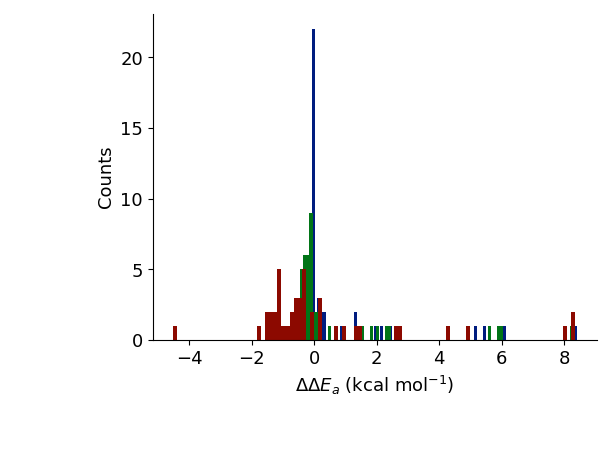

In [207]:
cog2 = importlib.reload(cog2)

f = cog2.plot_fscan_force_coordinate_data(
    gamma_data_f, gamma_data, fscan_iter, verbose=False,
    mags=[50, 100, 200],
    # scatter_styles=dict(
    #     plot_range=[None, [-5, 5]]
    # ),
    hist_max=10,
    scatter_max=10,
    plot_hist=True
)[1]
f  # .savefig('figs/coordinate_type_rigid_response.png', dpi=300)


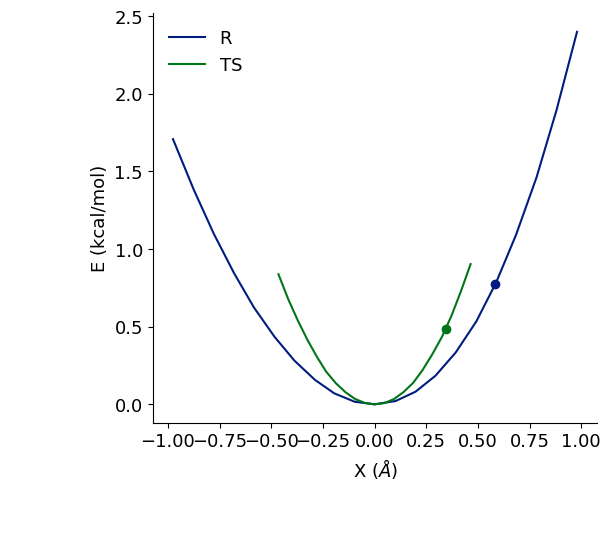

In [209]:
r,k = fscan_iter[3]
f0 = cog2.plot_gamma_fcomp(
    gamma_data_f[r][k],
    gamma_data[r][k]
)
cog2.plot_gamma_fscan_force_points(
    gamma_data_f[r][k],
    gamma_data[r][k],
    200,
    figure=f0
)

In [223]:
import McUtils.Iterators as itut

In [226]:
?itut.index_groups

Signature: itut.index_groups(iterable, hashable=True)
Docstring: <no docstring>
File:      ~/Documents/UW/Research/Development/McUtils/McUtils/Iterators/core.py
Type:      function

In [365]:
fscan_indices = itut.index_groups((f[0].rsplit("_", 1)[-1] for f in fscan_iter)) 

In [ ]:
# 1+3, 6+9, 7+10, 8+11, 13+14

In [412]:
cog2 = importlib.reload(cog2)

In [ ]:
a = gamma_data_f[r1][k1]['atoms']
c = np.array(gamma_data_f[r1][k1]['reactant']['xyz'])
c = c.reshape(-1, c.shape[-1]//3, 3) / UnitsData.bohr_to_angstroms
Molecule(a, c[0]).plot(c)

In [419]:
k1

'dihedralH30C15C2O1'

In [ ]:
r1, k1 = fscan_iter[fscan_indices['11'][1]]
df = gamma_data_f[r1][k1]
dc = gamma_data[r1][k1]
a = df['atoms']
_, (c_r, c_t) = cog2.get_gamma_force_scan_data(df, dc, load_coords=True)
Molecule(a, c_r[0]).plot(c_r)

In [ ]:
r1, k1 = fscan_iter[fscan_indices['8'][0]]
df = gamma_data_f[r1][k1]
dc = gamma_data[r1][k1]
a = df['atoms']
_, (c_r, c_t) = cog2.get_gamma_force_scan_data(df, dc, load_coords=True)
Molecule(a, c_r[0]).plot(c_r)


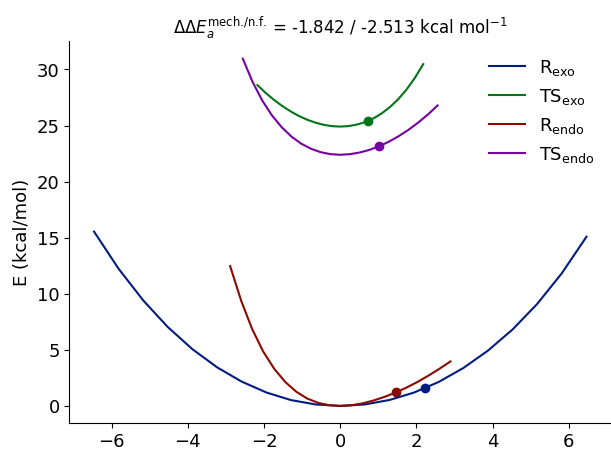


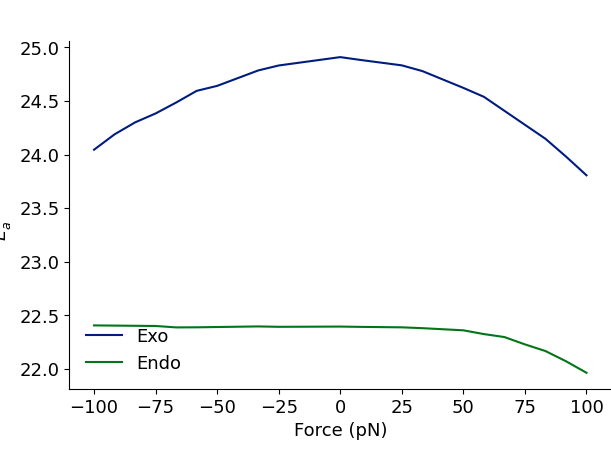

In [442]:
r1, k1 = fscan_iter[fscan_indices['8'][1]]
r2, k2 = fscan_iter[fscan_indices['11'][1]]

mag = -100
cog2.plot_stereopair_curves(
    gamma_data_f[r1][k1],
    gamma_data[r1][k1],
    gamma_data_f[r2][k2],
    gamma_data[r2][k2],
    -mag,
    padding=[[50, 0], [25, 30]],
    image_size=[440, 330]
).show()
cog2.plot_force_barrier_pair_data(
            gamma_data_f[r1][k1],
            gamma_data[r1][k1],
            gamma_data_f[r2][k2],
            gamma_data[r2][k2],
            np.linspace(-mag, mag, 25),
            labels=['Exo', 'Endo'],
            plot_legend=True,
            legend_style={'frameon':False, 'fontsize':13, 'loc':'lower left'},
            image_size=[440, 330]
        )

In [367]:
# cog2 = importlib.reload(cog2)

# i, j = '7', '10'
# n, m = 0, 0

for (i,j) in [
    ('1', '3'),
    ('6', '9'),
    ('7', '10'),
    ('8', '11'),
    ('13', '14'),
    # ('7', '10'),
]:
    for n,m in [[0, 0], [1, 0], [0, 1], [1, 1]]:
        r1,k1 = fscan_iter[fscan_indices[i][n]]
        r2,k2 = fscan_iter[fscan_indices[j][m]]
        
        stereoplot = cog2.plot_stereopair_curves(
            gamma_data_f[r1][k1],
            gamma_data[r1][k1],
            gamma_data_f[r2][k2],
            gamma_data[r2][k2],
            -250,
            padding=[[50, 0], [25, 30]],
            image_size=[440, 330]
        )
        
        barrier_scan_plot = cog2.plot_force_barrier_pair_data(
            gamma_data_f[r1][k1],
            gamma_data[r1][k1],
            gamma_data_f[r2][k2],
            gamma_data[r2][k2],
            np.linspace(-250, 250, 25),
            labels=['Exo', 'Endo'],
            plot_legend=True,
            legend_style={'frameon':False, 'fontsize':13, 'loc':'lower left'},
            image_size=[440, 330]
        )
        
        stereoplot.savefig(f"figs/sample_stereocurves_{r1}_{k1}_{r2}_{k2}.svg")
        barrier_scan_plot.savefig(f"figs/sample_barrier_scan_{r1}_{k1}_{r2}_{k2}.svg")


In [ ]:
1+3, 6+9, 7+10, 8+11, 13+14

##### Figure 3

**M06-2x**

In [314]:
gamma_data = {
    k:v['cscan'] 
    for k,v in all_gamma_data_old.items()
}
gamma_data_f = {
    k:v['fscan'] 
    for k,v in all_gamma_data_old.items()
}
fscan_iter = [
    (i, j)
    for i, v in gamma_data_f.items()
    for j in v.keys()
]

**wB97**

In [257]:
gamma_data = {k:v['cscan'] for k,v in all_gamma_data.items()}
gamma_data_f = {
    k:v['fscan'] 
    for k,v in all_gamma_data.items()
}
fscan_iter = [
    (i, j)
    for i, v in gamma_data_f.items()
    for j in v.keys()
]

### AIMNet2 Comps

In [464]:
r1, k1 = fscan_iter[3]
df = gamma_data_f[r1][k1]
dc = gamma_data[r1][k1]
a = all_gamma_data[r1]['atoms']
e_data, (c_r, c_t) = cog2.get_gamma_force_scan_data(df, dc, load_coords=True)
e_aim = Molecule(a, c_r[0], energy_evaluator='aimnet2:aimnet2-2025').calculate_energy(c_r)
e_aim2 = Molecule(a, c_r[0], energy_evaluator='aimnet2:aimnet2').calculate_energy(c_r)
e_aim3 = Molecule(a, c_r[0], energy_evaluator='aimnet2:aimnet2-nse', spin=1).calculate_energy(c_r)

In [471]:
# interactive.ModuleReloader("McUtils.Zachary").reload()
cog2 = importlib.reload(cog2)


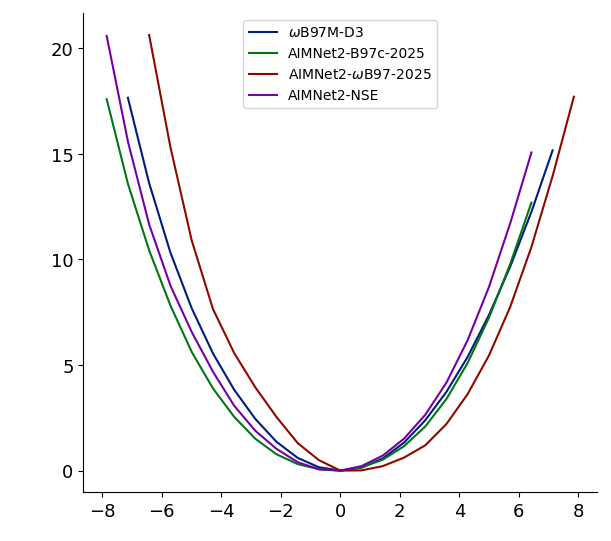

In [490]:
r1, k1 = fscan_iter[15]
df = gamma_data_f[r1][k1]
dc = gamma_data[r1][k1]

cog2.plot_energy_scan_comparison(df, dc,
                                 'reactant',
                                 atoms=all_gamma_data[r1]['atoms'],
                                 dft_lot=r'$\omega$B97M-D3',
                                 shift_curves=True,
                                 shift_baselines=True)

In [323]:
(e_aim - np.min(e_aim)) * UnitsData.convert("Hartrees", "Kilocalories/Mole"

array([2.67522552, 2.32351157, 1.98188541, 1.69769541, 1.42200992,
       1.17734747, 0.95215105, 0.74347121, 0.56396992, 0.39735947,
       0.26339817, 0.15700144, 0.07475374, 0.02149579, 0.        ,
       0.00915227, 0.04572373, 0.11497035, 0.21352075, 0.36126435,
       0.52582348])

#### Stereo Searches

In [113]:
d2_groups = rda.get_dienophile_groups(d2_reg)

pairs = [k for k in d2_groups[1] if ' ' in k]
subwoof = d2_groups[1][pairs[5]]

In [146]:
len(pairs)

15

In [149]:
sg = rda.prep_stereo_subgroups(d2_groups[1], pairs[14])
sg_roots = {
    tag:np.unique([
        k.split("/")[0]
        for k in v.d_path
    ])
    for tag, v in sg.items()
}
{
    t:[
        any(
            k.startswith(r)
            for k in gamma_data_f
        )
        for r in root_set
    ]
    for t,root_set in sg_roots.items()
}

{'2@-1/2@1': [False],
 '2@-1/3@-1': [False],
 '2@-1/3@1': [False, False],
 '2@1/2@-1': [False],
 '2@1/3@-1': [False, False],
 '2@1/3@1': [False]}

In [ ]:
gamma_data_f.keys()

{'2@-1/2@1': [False, False],
 '2@-1/3@-1': [False, False],
 '2@-1/3@1': [False, False],
 '2@1/2@-1': [False, False],
 '2@1/3@-1': [False, False],
 '2@1/3@1': [False, False]}

In [120]:
np.unique([
    "_".join(k.split("/")[:2]) 
    for k in sg['2@-1/2@1'].d_path
])

array(['USWBSYZEYOTXCF-GCZXYKMCSA-N_10', 'USWBSYZEYOTXCF-GCZXYKMCSA-N_13',
       'USWBSYZEYOTXCF-GCZXYKMCSA-N_4', 'USWBSYZEYOTXCF-GCZXYKMCSA-N_6',
       'USWBSYZEYOTXCF-XIVSLSHWSA-N_14', 'USWBSYZEYOTXCF-XIVSLSHWSA-N_15',
       'USWBSYZEYOTXCF-XIVSLSHWSA-N_17'], dtype='<U30')

#### DFT Validation

##### Ryan

In [252]:
ds_old, d2_old = rda.load_prep_filter('/Users/Mark/Documents/Postdoc/Projects/CMCC/disub_alt.npz',
                                     require_aliases=False
                                     )

In [253]:
old_ids = ds_old.data_ids
g1 = dict(zip(*nput.group_indices([o[0] for o in old_ids])[0]))
def get_old_key_mask(r1, k1):
    possible_locs = g1[r1]
    key_map = [i for i in possible_locs if old_ids[i][1] == k1]
    # all_mask = np.full(len(old_ids), False)
    # all_mask[key_map,] = True
    return key_map
    

In [261]:
barrier_comps = []
for r,k in reaction_iter:
    k1, k2 = r.split("_")
    b0 = rda.pre_barrier(
        ds_old[get_old_key_mask(k1, k2)][0]
    )
    _, (__, b1) = cog2.get_gamma_force_data(gamma_data[r][k], return_baselines=True)
    barrier_comps.append([b1, b0])

##### Sharon

In [89]:
import csv

sheets = {}
with open(f'pressure/smi_sheet.csv') as press_100:
    smis = [line[2] for line in itertools.islice(csv.reader(press_100), 1, None)]
for mag in [100, 200, 500, 1000]:
    with open(f'pressure/0728_hydro_compare_organized_{mag}.csv') as press_100:
        sheets[mag] = np.array([
            [float(x) if x != '' else np.nan for x in line]
                for line in itertools.islice(csv.reader(press_100), 1, None)
        ])

smis_2 = []
sheets2 = {}
skip_cols = [1, 2]
for mag in [100, 200, 500, 1000]:
    with open(f'pressure/sorted_master_newdataset_corr_0814_{mag}.csv') as press_100:
        lines = []
        for line in itertools.islice(csv.reader(press_100), 1, None):
            lines.append([float(x) if x != '' else np.nan for j,x in enumerate(line) if j not in skip_cols])
        smis_2.append(line[1] + "_" + line[2])
        sheets2[mag] = np.array(lines)

In [262]:
validation_ea_sheet = pandas.read_excel('pressure/sorted_master_newdataset_rm_0910.xlsx', sheet_name=f'nf_Ea_validation')

In [92]:
# good_barrier_mask = np.where(~np.isnan(sheets2[100][:, 3]))[0]
# good_barrier_mask2 = np.where(~np.isnan(sheets[100][:, 4]))[0]

# barrier_comps2 = []
# lines = sheets2[100]
# for m in good_barrier_mask:
#     # k1, k2 = smis_2[m].split("_")
#     # b0 = rda.pre_barrier(
#     #     d2_old[
#     #         lambda d:[did[0] == k1 and did[1] == k2 for did in d['data_ids']]
#     #     ][0]
#     # )
    
#     b0 = lines[m][11] * UnitsData.convert("Hartrees", "Kilocalories/Mole")
#     b1 = lines[m][3]
#     barrier_comps2.append([b1, b0])

# # barrier_comps2 = []
# lines = sheets[100]
# for m in good_barrier_mask2:
#     # k1, k2 = smis_2[m].split("_")
#     # b0 = rda.pre_barrier(
#     #     d2_old[
#     #         lambda d:[did[0] == k1 and did[1] == k2 for did in d['data_ids']]
#     #     ][0]
#     # )
    
#     b0 = lines[m][18]# * UnitsData.convert("Hartrees", "Kilocalories/Mole")
#     b1 = lines[m][4]
#     barrier_comps2.append([b1, b0])

In [263]:
barrier_dats = validation_ea_sheet.to_numpy()
mask = ~(np.isnan(barrier_dats[:, -1]) | np.isnan(barrier_dats[:, -2]))
barrier_comps2 = barrier_dats[mask][:, (-2, -1)].tolist()
barrier_comps3 = barrier_dats[mask][:, (1, -1)].tolist()

##### Plot

In [298]:
bc_all = (
    barrier_comps 
    + barrier_comps2
)
f0 = plt.ScatterPlot(
    [b[0] for b in barrier_comps],
    [b[1] for b in barrier_comps],
    axes_labels=[r"$\Delta E^{\ddagger}_\text{DFT}$", 
                 r"$\Delta E^{\ddagger}_\text{AIMNet2}$"],
    s=25,
    plot_range= [
        [np.min(bc_all), np.max(bc_all)+1],
        [np.min(bc_all), np.max(bc_all)+1]
    ],
    color=plt.prep_color(palette=rda.COLOR_PALETTE, index=0),# alpha=.1),
    plot_legend=True,
    label='RFO - def2-TSVP'
)
plt.ScatterPlot(
    [b[0] for b in barrier_comps2],
    [b[1] for b in barrier_comps2],
    figure=f0,
    s=25,
    color=plt.prep_color(palette=rda.COLOR_PALETTE, index=1),#, alpha=.2),
    label='FSM - def2-TSVP'
)

plt.ScatterPlot(
    [b[0] for b in barrier_comps3],
    [b[1] for b in barrier_comps3],
    figure=f0,
    s=25,
    color=plt.prep_color(palette=rda.COLOR_PALETTE, index=2),#, alpha=.2),
    label='FSM - def2-TZVP'
)
plt.Plot(
    [np.min(bc_all), np.max(bc_all)],
    [np.min(bc_all), np.max(bc_all)],
    figure=f0,
    color='gray',
    linestyle='dashed'
)
f0#.savefig('figs/initial_dft_validation_scatter_nt.svg')

/Users/Mark/Documents/UW/Research/Development/McUtils/McUtils/Plots/Backends.py:4864: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  )


In [ ]:
r, k = reaction_iter[0]
_, (c_r, c_t) = cog2.get_gamma_force_data(gamma_data[r][k], load_coords=True)
Molecule(["C"] * len(c_r[0]), c_r[0]).plot(c_r)

In [225]:
Molecule(
    gamma_data['GFMOBVPPXIFSSN-UOKDIZQMSA-N_2']['dihedralS7C2C3H32']['reactant'].keys()

dict_keys(['E', 'q', 'dX_dq', 'xyz'])

In [ ]:
d2_groups = rda.get_dienophile_groups(d2_reg)

pairs = [k for k in d2_groups[1] if ' ' in k]
subwoof = d2_groups[1][pairs[5]]

# Misc

## Reproduce the loaded pressure and force panels

Run the following cells in order in a fresh native ARM Python 3.11 kernel, with the working directory set to this paper folder. They use the UW McUtils/Psience sources and the saved, record-aligned inputs in `figs/pressure_force_reproduction/`. Volumes use each plotted pressure or 200 pN geometry; pressures are scalar. The final cell exports the four native SVG/PNG panels with the final two-line equation layout. PowerPoint panel letters, counts, legends, and picture crops are separate assembly elements.


In [ ]:
from pathlib import Path as _dp_Path
import sys as _dp_sys
import os as _dp_os
import platform as _dp_platform
import json as _dp_json

if _dp_sys.version_info[:2] != (3, 11) or _dp_platform.machine() != "arm64":
    raise RuntimeError("Use the native ARM Python 3.11 research environment")

# These two optional overrides are useful when validating a copied notebook.
_dp_paper = _dp_Path(globals().get("DA_PAPER_ROOT", _dp_Path.cwd())).expanduser().resolve()
_dp_bundle = _dp_Path(globals().get(
    "DA_REPRODUCTION_DIR", _dp_paper / "figs/pressure_force_reproduction"
)).expanduser().resolve()
if not (_dp_paper / "DA_figs.ipynb").is_file():
    raise FileNotFoundError("Run from the DA_paper folder or set DA_PAPER_ROOT")
if not (_dp_bundle / "input_data.npz").is_file():
    raise FileNotFoundError(f"Missing reproduction inputs: {_dp_bundle}")

# Use the same local research sources as the original analysis.
_dp_uw = _dp_Path.home() / "Documents/UW/Research/Development"
_dp_sources = (
    _dp_uw / "McUtils", _dp_uw / "Psience",
    _dp_Path.home() / "Documents/Postdoc/Development/cmcc-reactions",
)
for _dp_path in _dp_sources:
    if not _dp_path.is_dir():
        raise FileNotFoundError(f"Missing research source: {_dp_path}")
_dp_sys.path[:0] = [str(_dp_path) for _dp_path in _dp_sources]
_dp_sys.dont_write_bytecode = True
_dp_os.environ.setdefault("PYTHONDONTWRITEBYTECODE", "1")
_dp_os.environ.setdefault("NUMBA_CACHE_DIR", str(_dp_bundle / ".numba"))
_dp_os.environ.setdefault("MPLCONFIGDIR", str(_dp_bundle / ".matplotlib"))
_dp_os.environ.setdefault("TORCH_COMPILE_DISABLE", "1")

import numpy as _dp_np
import McUtils as _dp_mcutils
import Psience as _dp_psience
import McUtils.Plots as _dp_plt
from McUtils.Data import UnitsData as _dp_UnitsData
import cmcc_reactions.reaction_data_analysis as _dp_rda

for _dp_module, _dp_source in (
    (_dp_mcutils, _dp_uw / "McUtils"), (_dp_psience, _dp_uw / "Psience"),
):
    if not _dp_Path(_dp_module.__file__).resolve().is_relative_to(_dp_source.resolve()):
        raise RuntimeError("Restart the kernel and run this section to use the UW sources")

with _dp_np.load(_dp_bundle / "input_data.npz", allow_pickle=False) as _dp_saved:
    _dp_inputs = {key: _dp_saved[key].copy() for key in _dp_saved.files}
_dp_layout = _dp_json.loads((_dp_bundle / "equation_layout.json").read_text())
_dp_provenance = _dp_json.loads((_dp_bundle / "provenance.json").read_text())
_dp_pressure_series, _dp_pressure_rmsds = {}, {}
for _dp_pressure in (100, 200, 500, 1000):
    _dp_pressure_series[_dp_pressure] = {
        key: _dp_inputs[f"volume_P{_dp_pressure}_{key}"]
        for key in ("keys", "x_deltaV", "ybarrier")
    }
    _dp_pressure_rmsds[_dp_pressure] = {
        key: _dp_inputs[f"rmsd_P{_dp_pressure}_{key}"]
        for key in ("keys", "rmsd", "ybarrier")
    }
    for _dp_series in (_dp_pressure_series[_dp_pressure], _dp_pressure_rmsds[_dp_pressure]):
        if len({len(values) for values in _dp_series.values()}) != 1:
            raise ValueError("Pressure arrays are not aligned")
        if len(_dp_np.unique(_dp_series["keys"])) != len(_dp_series["keys"]):
            raise ValueError("Duplicate pressure identities")
    if not _dp_np.array_equal(
        _dp_pressure_series[_dp_pressure]["keys"], _dp_inputs["volume_P1000_keys"]
    ):
        raise ValueError("Pressure volume identity order differs")

_dp_force_x = _dp_inputs["force_delta_volume_a3"]
_dp_force_y = _dp_inputs["force_delta_barrier_kcal_mol"]
_dp_force_rmsd = _dp_inputs["force_reactant_rmsd_a"]
_dp_force_ids = _dp_inputs["force_record_id"]
if not all(len(values) == 26955 for values in (
    _dp_force_x, _dp_force_y, _dp_force_rmsd, _dp_force_ids,
    _dp_inputs["force_dataset_index"], _dp_inputs["force_magnitude_pn"],
)):
    raise ValueError("Unexpected 200 pN dataset size")
if len(_dp_np.unique(_dp_force_ids)) != 26955:
    raise ValueError("Duplicate force record identities")
if not _dp_np.allclose(_dp_np.abs(_dp_inputs["force_magnitude_pn"]), 200, atol=1e-6, rtol=0):
    raise ValueError("Expected the notebook's two force signs at 200 pN")
if not all(_dp_np.isfinite(values).all() for values in (_dp_force_x, _dp_force_y, _dp_force_rmsd)):
    raise ValueError("Nonfinite force data")


In [ ]:
# Native plotting code corresponding to original notebook cell 494.
def _dp_make_pressure_volume(pressure_series, equation_positions):
    np, plt, rda, UnitsData = _dp_np, _dp_plt, _dp_rda, _dp_UnitsData
    pressure_barriers = pressure_series[1000]['ybarrier']
    pressure_barriers_500 = pressure_series[500]['ybarrier']
    pressure_barriers_200 = pressure_series[200]['ybarrier']
    pressure_barriers_100 = pressure_series[100]['ybarrier']
    pbs = pressure_series[1000]['ybarrier']
    # pbs2 = new_barriers[-1][:len(p_key_mask)][both_keys_mask]
    # pbs = pbs - pbs2
    adiff = pressure_series[1000]['x_deltaV']
    # adiff = (all_nfvols_T_unscaled) - (all_nfvols_unscaled)[subkeys_mask]
    # Corrected loaded volumes are already expressed in angstrom cubed.
    # adiff = (all_pvols_T) - (all_pvols)[subkeys_mask]
    # adiff = (all_pvols_T - all_nfvols_T) - (all_pvols - all_nfvols)[subkeys_mask]
    mask = ~np.isnan(pbs) & (np.abs(pbs) < 19) & np.isfinite(adiff) #& (np.abs(apd) < 5)

    f0 = plt.ScatterPlot(
        adiff[mask],
        pbs[mask],
        image_size=[350, 280],
        padding=[[85, 0], [50, 25]],
        plot_range=[[-62, 5], [-2.8, 1.9]],
        color=plt.prep_color(palette=rda.COLOR_PALETTE, index=3),#, alpha=0),
        axes_labels=[
            r"$\Delta \text{V} \left[P=P_\text{ext}\right] (\mathrm{\AA}^3)$", 
            r"$\Delta \Delta E^{\ddagger} \left[P=P_\text{ext}\right]$ (kcal mol$^{-1}$)"
        ],
        s=15
    )
    mask = mask & (pbs > -2) & (pbs < 3)
    fit_stuff = rda.get_compliance_fit(
        adiff[mask],
        pbs[mask],
        include_intercept=True
    )  # [1]
    slope, fit = fit_stuff[:2]
    reference_pressure_slope = slope.copy()

    plt.Plot([-50, 2], [fit(-50), fit(2)], figure=f0,
             linestyle='dashed', color='gray'
             )

    for n,b0 in enumerate([
        pressure_barriers_100,
        pressure_barriers_200,
        pressure_barriers_500
    ]):
        pressure = [100, 200, 500][n]
        pbs3 = b0
        adiff = pressure_series[pressure]['x_deltaV']
        mask2 = ~np.isnan(pbs3) & (np.abs(pbs3) < 19) & np.isfinite(adiff) #& (pbs3 < 1.5)
        plt.ScatterPlot(
            adiff[mask2],
            pbs3[mask2],
            color=plt.prep_color(palette=rda.COLOR_PALETTE, index=n),#, alpha=0),
            figure=f0,
            s=15
        )

        mask = mask & (pbs3 > -2) & (pbs3 < 1) & np.isfinite(adiff)
        fit_stuff = rda.get_compliance_fit(
            adiff[mask],
            pbs3[mask],
            include_intercept=True
        )  # [1]
        slope, fit = fit_stuff[:2]
    
        plt.Plot([-50, 2], [fit(-50), fit(2)], figure=f0,
                 linestyle='dashed', color='gray'
                 )


    eb = '#fdfdfe'
    x0, y0 = [-55, .8]
    x1, y1 = [x0+56, y0+1]
    # plt.Rectangle(
    #     [
    #         [x0, y0],
    #         [x1, y1]
    #     ],
    #     color=eb,
    #     edgecolor='#f0f0f0',#plt.prep_color(eb, lighten=-.2, modification_space='hsl'),
    #     zorder=-1000
    # ).plot(f0)
    plt.Text(
        rf"$\Delta \Delta E^{{\ddagger}} \left[P=1000 \text{{MPa}}\right] =$",
        equation_positions[0],
        font_size=13,
        transform=f0.axes.obj.transAxes,
        horizontalalignment="left",
        verticalalignment="baseline"
    ).plot(
        f0
    )
    plt.Text(
        rf"$\left({reference_pressure_slope[0]:.3f} \mathrm{{\AA}}^{{-3}} + {reference_pressure_slope[1]:.3f}\right) \text{{ kcal mol}}^{{-1}}$",
        equation_positions[1],
        font_size=13,
        transform=f0.axes.obj.transAxes,
        horizontalalignment="left",
        verticalalignment="baseline"
    ).plot(f0)

    # plt.Text(
    #     rf"$\left({reference_pressure_slope[0]:.3f} \mathrm{{\AA}}^{{-3}}\right) \text{{ kcal mol}}^{{-1}}$",
    #     [-35, -3.1],
    #     font_size=13
    # ).plot(f0)
    # plt.Plot([0, .2], [fit(0), fit(.2)], figure=f0, 
    #         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
    #         )

    return f0


In [ ]:
# Native plotting code corresponding to original notebook cell 482.
def _dp_make_pressure_rmsd(pressure_rmsds, equation_positions):
    np, plt, rda, UnitsData = _dp_np, _dp_plt, _dp_rda, _dp_UnitsData
    pressure_barriers = pressure_rmsds[1000]['ybarrier']
    pressure_barriers_500 = pressure_rmsds[500]['ybarrier']
    pressure_barriers_200 = pressure_rmsds[200]['ybarrier']
    pressure_barriers_100 = pressure_rmsds[100]['ybarrier']
    comp_R = pressure_rmsds[1000]['rmsd']
    pbs2 = pressure_barriers[:len(comp_R)]
    mask = ~np.isnan(pbs2) & (np.abs(pbs2) < 19) & (comp_R < .2)

    f0 = plt.ScatterPlot(
        comp_R[mask],
        pbs2[mask],
        # ticks=[[0, .05, .1, .15, .2], None],
        color=plt.prep_color(palette='default', index=3),
        image_size=[350, 280],
        padding=[[85, 0], [50, 25]],
        plot_range=[[-.01, .37], [-2.8, 1.9]],
        s=15,
        axes_labels=[
            r"$\text{RMSD}_\text{reactants} \left[P=P_\text{ext}\right] (\mathrm{\AA})$",
            r"$\Delta \Delta E^{\ddagger} \left[P=P_\text{ext}\right]$ (kcal mol$^{-1}$)"
            # "Full"
            # r"$\Delta E_\text{dist.} \left[P=P_\text{ext}\right]$ (kcal mol$^{-1}$)"
        ]
    )
    fit_stuff = rda.get_compliance_fit(
        comp_R[mask],
        pbs2[mask],
        include_intercept=False
    )  # [1]
    slope, fit = fit_stuff[:2]

    # plt.Plot([0, 0.2], [fit(0), fit(0.2)], figure=f0,
    #          linestyle='dashed', 
    #          color='gray',
    #          # color=plt.prep_color(palette='default', index=2)
    #          )
    plt.Text(
        rf"$\Delta \Delta E^{{\ddagger}} \left[P=1000 \text{{MPa}}\right] = $",
        equation_positions[0],
        font_size=13,
        transform=f0.axes.obj.transAxes,
        horizontalalignment="left",
        verticalalignment="baseline"
    ).plot(f0)
    plt.Text(
        rf"${slope[0]:.1f}\ \text{{kcal}}\,\text{{mol}}^{{-1}} / \mathrm{{\AA}}$",
        equation_positions[1],
        font_size=13,
        transform=f0.axes.obj.transAxes,
        horizontalalignment="left",
        verticalalignment="baseline"
    ).plot(f0)

    for n,b0 in enumerate([
        pressure_barriers_100,
        pressure_barriers_200,
        pressure_barriers_500,
        pressure_barriers,
    ]):
        pressure = [100, 200, 500, 1000][n]
        comp_R = pressure_rmsds[pressure]['rmsd']
        pbs2 = b0
        mask = ~np.isnan(pbs2) & (np.abs(pbs2) < 19)
    
        f0 = plt.ScatterPlot(
            comp_R[mask],
            pbs2[mask],
            color=plt.prep_color(palette=rda.COLOR_PALETTE, index=n),#, alpha=0),
            figure=f0,
            s=15
        )

        mask = mask & (pbs2 > -2) & (pbs2 < 1)
        fit_stuff = rda.get_compliance_fit(
            comp_R[mask],
            pbs2[mask],
            include_intercept=False
        )  # [1]
        slope, fit = fit_stuff[:2]
    
        plt.Plot([0, .345], [fit(0), fit(.345)], figure=f0,
                 linestyle='dashed', color='gray'
                 )


    # eb = '#fdfdfe'
    # x0, y0 = [-55, .8]
    # x1, y1 = [x0+56, y0+1]
    # # plt.Rectangle(
    # #     [
    # #         [x0, y0],
    # #         [x1, y1]
    # #     ],
    # #     color=eb,
    # #     edgecolor='#f0f0f0',#plt.prep_color(eb, lighten=-.2, modification_space='hsl'),
    # #     zorder=-1000
    # # ).plot(f0)
    # plt.Text(
    #     rf"$\Delta \Delta E^{{\ddagger}} \left[P=1000 \text{{MPa}}\right] =$",
    #     [x0+1, y1-.35],
    #     font_size=13
    # ).plot(
    #     f0
    # )
    # plt.Text(
    #     rf"$\left({slope[0]:.3f} \mathrm{{\AA}}^{{-3}} + {slope[1]:.3f}\right) \text{{ kcal mol}}^{{-1}}$",
    #     [x0+6, y0+.15],
    #     font_size=13
    # ).plot(f0)



    # plt.Text(
    #     rf"$\left({slope[0]:.3f} \mathrm{{\AA}}^{{-3}}\right) \text{{ kcal mol}}^{{-1}}$",
    #     [-35, -3.1],
    #     font_size=13
    # ).plot(f0)
    # plt.Plot([0, .2], [fit(0), fit(.2)], figure=f0, 
    #         linestyle='dashed', color=plt.prep_color(palette='default', index=2)
    #         )

    return f0


In [ ]:
# Native plotting code corresponding to original notebook cell 526.
def _dp_make_force_volume(dv_edata, equation_positions):
    np, plt, rda, UnitsData = _dp_np, _dp_plt, _dp_rda, _dp_UnitsData
    # mask = rmsds_R < .5
    # fit_stuff = rda.get_compliance_fit(
    #     rmsds_R[mask],
    #     uuh.deltas[mask] * UnitsData.convert("Hartrees", "Kilocalories/Mole"),
    #     include_intercept=False
    # )  # [1]
    # slope, fit = fit_stuff[:2]


    f0 = plt.ScatterPlot(dv_edata[:, 0], dv_edata[:, 1], 
                         color=plt.prep_color(palette='default', index=0, alpha=.01),
                         axes_labels=[
                               r"$\Delta$V $\left[\vec{F}=200 \text{pN}\right]$ ($\mathrm{\AA}^3$)", 
                               r"$\Delta \Delta E^{\ddagger} \left[\vec{F}=200 \text{pN}\right]$ (kcal mol$^{-1}$)"
                        ],
                    
                        image_size=[350, 280],
        padding=[[85, 0], [50, 25]],
                        )
    fit_stuff = rda.get_compliance_fit(
        dv_edata[:, 0], 
        dv_edata[:, 1],
        include_intercept=True
    )  # [1]
    slope, fit = fit_stuff[:2]

    plt.Plot([-10, -6], [fit(-10), fit(-6)], figure=f0,
             linestyle='dashed', color='gray'
             )
    plt.Text(
        rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{F}}=200 \text{{pN}}\right] =$",
        equation_positions[0],
        font_size=13,
        transform=f0.axes.obj.transAxes,
        horizontalalignment="left",
        verticalalignment="baseline"
    ).plot(f0)
    plt.Text(
        rf"$\left({slope[0]:#.3g} \mathrm{{\AA}}^{{-3}} {slope[1]:+#.3g}\right) \text{{kcal}}\,\text{{mol}}^{{-1}}$",
        equation_positions[1],
        font_size=13,
        transform=f0.axes.obj.transAxes,
        horizontalalignment="left",
        verticalalignment="baseline"
    ).plot(f0)
    # f0

    return f0


In [ ]:
# Native plotting code corresponding to original notebook cell 503.
def _dp_make_force_rmsd(rmsds_R, force_delta_barriers, equation_positions):
    np, plt, rda, UnitsData = _dp_np, _dp_plt, _dp_rda, _dp_UnitsData
    mask = rmsds_R < .5
    fit_stuff = rda.get_compliance_fit(
        rmsds_R[mask],
        force_delta_barriers[mask],
        include_intercept=False
    )  # [1]
    slope, fit = fit_stuff[:2]

    f0 = plt.ScatterPlot(
        rmsds_R,
        force_delta_barriers,
        color=plt.prep_color(palette='default', index=0, alpha=.01),
        axes_labels=[
            r"$\text{RMSD}_\text{reactants} \left[\vec{F}=200 \text{pN}\right] (\mathrm{\AA})$",
            r"$\Delta \Delta E^{\ddagger} \left[\vec{F}=200 \text{pN}\right]$ (kcal mol$^{-1}$)"
        ],
        image_size=[350, 280],
        padding=[[85, 0], [50, 25]],
        # plot_range=[[-.01, .22], [-2.8, 1.9]],
    )

    # for n, rr, uu in [
    #     [1, rmsds_R_100, uuh_100],
    #     [2, rmsds_R_50, uuh_50],
    # ]:
    #     vv = uu.deltas * UnitsData.convert("Hartrees", "Kilocalories/Mole")
    #     mask = np.abs(vv) < 10
    #     plt.ScatterPlot(
    #         rr[mask],
    #         vv[mask],
    #         color=plt.prep_color(palette='default', index=n, alpha=.005),
    #         image_size=[350, 280],
    #         figure=f0
    #         # plot_range=[[-.01, .22], [-2.8, 1.9]],
    #     )

    plt.Plot([0, 1.6], [fit(0), fit(1.6)], figure=f0,
             linestyle='dashed', color='gray'
             )
    plt.Text(
        rf"$\Delta \Delta E^{{\ddagger}} \left[\vec{{F}}=200 \text{{pN}}\right] =$",
        equation_positions[0],
        font_size=13,
        transform=f0.axes.obj.transAxes,
        horizontalalignment="left",
        verticalalignment="baseline"
    ).plot(f0)
    plt.Text(
        rf"${slope[0]:#.3g}\text{{kcal}}\, \text{{mol}}^{{-1}} / \mathrm{{\AA}}$",
        equation_positions[1],
        font_size=13,
        transform=f0.axes.obj.transAxes,
        horizontalalignment="left",
        verticalalignment="baseline"
    ).plot(f0)
    # f0

    return f0


In [ ]:
_dp_output = _dp_bundle / "panels"
_dp_output.mkdir(parents=True, exist_ok=True)
_dp_specs = (
    ("pressure_volume_fit_shrunk", _dp_make_pressure_volume, (_dp_pressure_series,)),
    ("pressure_volume_fit_all", _dp_make_pressure_rmsd, (_dp_pressure_rmsds,)),
    ("activation_volume_force_plot_panel", _dp_make_force_volume,
     (_dp_np.column_stack((_dp_force_x, _dp_force_y)),)),
    ("RMSD_r_base_panel", _dp_make_force_rmsd, (_dp_force_rmsd, _dp_force_y)),
)
_dp_panels, _dp_manifest = {}, {}
for _dp_name, _dp_make, _dp_arguments in _dp_specs:
    _dp_panel_layout = _dp_layout["panels"][_dp_name]
    _dp_graphic = _dp_make(*_dp_arguments, _dp_panel_layout["positions_axes"])
    _dp_graphic.savefig(str(_dp_output / f"{_dp_name}.svg"))
    _dp_graphic.savefig(str(_dp_output / f"{_dp_name}.png"), dpi=288)
    _dp_axes = _dp_graphic.axes.obj
    _dp_figure = _dp_axes.figure
    _dp_baselines_svg = []
    for _dp_text in _dp_axes.texts:
        _dp_x, _dp_y = _dp_text.get_transform().transform(_dp_text.get_position())
        _dp_scale = 72 / _dp_figure.dpi
        _dp_baselines_svg.append([
            float(_dp_x * _dp_scale),
            float(_dp_figure.get_figheight() * 72 - _dp_y * _dp_scale),
        ])
    _dp_mapping = _dp_panel_layout["svg_to_slide"]
    _dp_baselines_slide = [
        _dp_mapping["y_offset"] + _dp_mapping["y_scale"] * point[1]
        for point in _dp_baselines_svg
    ]
    if not _dp_np.allclose(
        _dp_baselines_slide, _dp_panel_layout["expected_slide_baselines_px"], atol=1e-8, rtol=0
    ):
        raise ValueError(f"Equation baseline mismatch: {_dp_name}")
    _dp_manifest[_dp_name] = {
        "x_limits": list(_dp_axes.get_xlim()), "y_limits": list(_dp_axes.get_ylim()),
        "equation_text": [text.get_text() for text in _dp_axes.texts],
        "equation_positions_axes": _dp_panel_layout["positions_axes"],
        "equation_baselines_svg_pt": _dp_baselines_svg,
        "equation_baselines_slide_px": _dp_baselines_slide,
    }
    _dp_panels[_dp_name] = _dp_graphic
(_dp_output / "reproduction_manifest.json").write_text(_dp_json.dumps(_dp_manifest, indent=2) + "\n")

try:
    from IPython.display import display as _dp_display
except ImportError:
    _dp_display = None
if _dp_display is not None:
    for _dp_graphic in _dp_panels.values():
        _dp_display(_dp_graphic)
print(f"Saved four SVG/PNG panels to {_dp_output}")
